# Regresión lineal múltiple: selección de variables y multicolinealidad

Este notebook continúa el análisis de calidad y exploración de `Regresion.ipynb` y trabaja solo con `Train real state.csv`.

1. **Selección de variables:** se buscan las variables que mejor explican `SalePrice` con best subset regression, los criterios AIC y BIC, backward elimination y stepwise regression. Con base en esos resultados se eligen 7 términos: `Size_sqf`, `YrSold`, `MonthSold`, `Floor`, `N_FacilitiesInApt`, `HallwayType` y `SubwayStation`.
2. **Multicolinealidad:** se revisa si los 7 términos elegidos están tan relacionados entre sí que no sea prudente usarlos juntos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from html import escape
from IPython.display import display, HTML
from matplotlib.ticker import FuncFormatter
from scipy.stats import chi2_contingency

AZUL, NARANJA = "#2f6fd6", "#e8743b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))


def mostrar(df, titulo=None, decimales=2):
    if titulo:
        display(HTML(f"<b>{escape(titulo)}</b>"))
    display(df.style.hide(axis="index").format(precision=decimales, thousands=".", decimal=","))


def cargar(archivo):
    """Lee el CSV y aplica la misma limpieza de la sección 5 de Regresion.ipynb."""
    d = pd.read_csv(archivo)
    d.columns = [c.rstrip(".").replace(".", "_") for c in d.columns]
    d["TimeToSubway"] = d["TimeToSubway"].replace({"0-5min": "0~5min", "no_bus_stop_nearby": "no_subway_nearby"})
    d.loc[d["SubwayStation"] == "no_subway_nearby", "TimeToSubway"] = "no_subway_nearby"
    return d


train = cargar("Train real state.csv")

respuesta = "SalePrice"
numericos = ["Size_sqf", "YrSold", "MonthSold", "Floor", "N_FacilitiesInApt"]
categoricos = {  # la primera categoría de cada lista es la de referencia (igual que en Regresion.ipynb)
    "HallwayType": ["terraced", "mixed", "corridor"],
    "SubwayStation": ["Kyungbuk_uni_hospital", "Myung-duk", "Bangoge", "Banwoldang", "Sin-nam",
                      "Chil-sung-market", "Daegu", "no_subway_nearby"],
}
terminos_modelo = numericos + list(categoricos)

mostrar(pd.DataFrame({
    "archivo": ["Train real state.csv"],
    "filas": [len(train)],
    "columnas": [train.shape[1]],
    "faltantes_en_los_7_terminos": [int(train[terminos_modelo].isna().sum().sum())],
}), "Archivo de entrada")

archivo,filas,columnas,faltantes_en_los_7_terminos
Train real state.csv,4.124,31,0


## 1. Selección de variables para la regresión lineal múltiple

Objetivo: elegir las variables que mejor explican la variabilidad de `SalePrice` en un modelo de regresión lineal múltiple ajustado por mínimos cuadrados ordinarios sobre Train limpio (`Train real state.csv` con la limpieza de la sección 5 de `Regresion.ipynb`, 4.124 departamentos).

**Variables candidatas (19 términos)**

- 13 numéricas: `Size_sqf`, `YearBuilt`, `YrSold`, `MonthSold`, `Floor`, `N_Parkinglot_Ground`, `N_Parkinglot_Basement`, `N_APT`, `N_manager`, `N_elevators`, `N_FacilitiesInApt`, `N_FacilitiesNearBy_Total` y `N_SchoolNearBy_Total`.
- 6 categóricas: `HallwayType`, `HeatingType`, `AptManageType`, `TimeToBusStop`, `TimeToSubway` y `SubwayStation`. Cada una entra como un solo término formado por sus variables indicadoras (se omite la primera categoría), así que se incluye o se excluye completa.
- Se usan los totales `N_FacilitiesNearBy_Total` y `N_SchoolNearBy_Total` en lugar de sus componentes, como en la Figura 4 de `Regresion.ipynb`: cada total es la suma exacta de sus componentes, así que no pueden entrar los dos a la vez. Además, con 19 términos el *best subset* puede recorrer todos los modelos posibles (2¹⁹ = 524.288); con los componentes serían 2²⁷ (más de 134 millones).

**Métodos**

| Método | Cómo elige |
|---|---|
| Best subset regression | Ajusta todos los subconjuntos posibles de términos y, para cada tamaño, guarda el de menor suma de cuadrados residual (mayor R²). Se comparan con R² ajustado, Cp de Mallows, AIC y BIC. |
| Criterio AIC | Modelo con menor AIC = −2·log-verosimilitud + 2·p entre todos los subconjuntos. |
| Criterio BIC | Modelo con menor BIC = −2·log-verosimilitud + ln(n)·p. Penaliza más los parámetros que el AIC (ln 4.124 ≈ 8,3 frente a 2). |
| Backward elimination | Parte del modelo completo y elimina, uno por uno, el término con mayor p-valor en la prueba F parcial, mientras ese p-valor sea mayor que 0,05. |
| Stepwise regression | Parte del modelo solo con intercepto. En cada paso entra el término con menor p-valor si es menor que 0,05 y luego sale el término con mayor p-valor si es mayor que 0,10. |

`p` es el número de parámetros estimables (rango de la matriz de diseño, intercepto incluido). Como solo hay 26 edificios y casi todas las variables describen al edificio, algunas indicadoras son combinación lineal de otras (por ejemplo, *no_subway_nearby* es la misma indicadora en `TimeToSubway` y en `SubwayStation`). Por eso los grados de libertad se calculan con el rango y no con el número de columnas; un término que no agrega rango tiene p-valor 1 en la prueba F parcial.

In [2]:
# Variables que la selección usaba de Regresion.ipynb, construidas a partir de Train limpio
datos = train.copy()  # equivale a df_train_limpio.toPandas()
columnas_texto = [c for c in datos.columns if datos[c].dtype == object]
dominios = {
    "HallwayType": ["terraced", "mixed", "corridor"],
    "HeatingType": ["individual_heating", "central_heating"],
    "AptManageType": ["management_in_trust", "self_management"],
    "TimeToBusStop": ["0~5min", "5min~10min", "10min~15min"],
    "TimeToSubway": ["0~5min", "5min~10min", "10min~15min", "15min~20min", "no_subway_nearby"],
    "SubwayStation": ["Kyungbuk_uni_hospital", "Myung-duk", "Bangoge", "Banwoldang", "Sin-nam",
                      "Chil-sung-market", "Daegu", "no_subway_nearby"],
}


def coma(x, decimales=2):
    return f"{x:.{decimales}f}".replace(".", ",")

In [3]:
from itertools import combinations
import time
import statsmodels.api as sm
from scipy import stats

respuesta = "SalePrice"
terminos_numericos = [
    "Size_sqf", "YearBuilt", "YrSold", "MonthSold", "Floor",
    "N_Parkinglot_Ground", "N_Parkinglot_Basement", "N_APT", "N_manager", "N_elevators",
    "N_FacilitiesInApt", "N_FacilitiesNearBy_Total", "N_SchoolNearBy_Total",
]
terminos_categoricos = list(columnas_texto)
terminos = terminos_numericos + terminos_categoricos

# Matriz de diseño: cada categórica se codifica con variables indicadoras (se omite la primera categoría)
bloques_diseno = [datos[terminos_numericos].astype(float)]
columnas_termino = {t: [t] for t in terminos_numericos}
for t in terminos_categoricos:
    niveles = dominios[t] if t in dominios else sorted(datos[t].unique())
    niveles = [v for v in niveles if v in set(datos[t])]
    ind = pd.get_dummies(pd.Categorical(datos[t], categories=niveles), prefix=t, dtype=float).iloc[:, 1:]
    bloques_diseno.append(ind.set_index(datos.index))
    columnas_termino[t] = list(ind.columns)
X_diseno = pd.concat(bloques_diseno, axis=1)
y_precio = datos[respuesta].astype(float)
n_obs = len(y_precio)


def ajustar(lista_terminos):
    """Ajusta por MCO SalePrice ~ términos. statsmodels usa el rango de X para los grados de libertad."""
    cols = [col for t in lista_terminos for col in columnas_termino[t]]
    Xm = sm.add_constant(X_diseno[cols], has_constant="add")
    return sm.OLS(y_precio, Xm).fit()


def resumen_ajuste(ajuste):
    return {
        "parametros": int(ajuste.df_model + 1),
        "R2": ajuste.rsquared,
        "R2_ajustado": ajuste.rsquared_adj,
        "AIC": ajuste.aic,
        "BIC": ajuste.bic,
        "RMSE": float(np.sqrt(ajuste.ssr / n_obs)),
    }


ajuste_completo = ajustar(terminos)
print(f"Observaciones: {n_obs}; columnas de X (sin intercepto): {X_diseno.shape[1]}; "
      f"rango de X con intercepto: {int(ajuste_completo.df_model + 1)}")

Observaciones: 4124; columnas de X (sin intercepto): 30; rango de X con intercepto: 29


C:\Users\Sebastian\AppData\Local\Temp\ipykernel_22284\1709453744.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(y_precio, Xm).fit()


### 1.1 Best subset regression

Para recorrer los 524.288 modelos rápidamente, la suma de cuadrados residual de cada uno se obtiene de la matriz de productos cruzados de las columnas estandarizadas (el resultado es el mismo que ajustar cada modelo; se comprueba con `statsmodels` en la sección 1.2).

In [4]:
# Estadísticos suficientes con las columnas estandarizadas (mejor condicionamiento numérico).
# Al centrar X y y, el intercepto queda fuera de la matriz de Gram.
Z = X_diseno.values - X_diseno.values.mean(axis=0)
Z = Z / Z.std(axis=0)
yc = y_precio.values - y_precio.values.mean()
gram, xty, sst = Z.T @ Z, Z.T @ yc, float(yc @ yc)
indices_termino = {t: [X_diseno.columns.get_loc(col) for col in columnas_termino[t]] for t in terminos}


def rss_y_rango(lista_terminos):
    if not lista_terminos:
        return sst, 1
    idx = [i for t in lista_terminos for i in indices_termino[t]]
    beta, _, rango, _ = np.linalg.lstsq(gram[np.ix_(idx, idx)], xty[idx], rcond=1e-10)
    return sst - float(xty[idx] @ beta), int(rango) + 1  # +1 por el intercepto


def criterio_informacion(rss, p):
    llf = -n_obs / 2 * (np.log(2 * np.pi * rss / n_obs) + 1)
    return -2 * llf + 2 * p, -2 * llf + np.log(n_obs) * p


inicio = time.time()
registros_subconjuntos = []
for tam in range(0, len(terminos) + 1):
    for sub in combinations(range(len(terminos)), tam):
        rss, p = rss_y_rango([terminos[i] for i in sub])
        registros_subconjuntos.append((sub, tam, p, rss))
todos_subconjuntos = pd.DataFrame(registros_subconjuntos, columns=["subconjunto", "n_terminos", "parametros", "RSS"])
todos_subconjuntos["AIC"], todos_subconjuntos["BIC"] = criterio_informacion(
    todos_subconjuntos["RSS"].values, todos_subconjuntos["parametros"].values)
print(f"Modelos evaluados: {len(todos_subconjuntos):,} en {time.time() - inicio:.0f} s".replace(",", "."))

# Mejor modelo (menor RSS = mayor R²) para cada número de términos; Cp de Mallows con el MSE del modelo completo
mse_completo = ajuste_completo.mse_resid
mejores_por_tamano = todos_subconjuntos.loc[todos_subconjuntos.groupby("n_terminos")["RSS"].idxmin()].copy()
mejores_por_tamano["R2"] = 1 - mejores_por_tamano["RSS"] / sst
mejores_por_tamano["R2_ajustado"] = 1 - (mejores_por_tamano["RSS"] / (n_obs - mejores_por_tamano["parametros"])) / (sst / (n_obs - 1))
mejores_por_tamano["Cp"] = mejores_por_tamano["RSS"] / mse_completo - n_obs + 2 * mejores_por_tamano["parametros"]
mejores_por_tamano["terminos"] = mejores_por_tamano["subconjunto"].apply(lambda s: ", ".join(terminos[i] for i in s))
mejores_por_tamano = mejores_por_tamano[mejores_por_tamano["n_terminos"] > 0]

mostrar(mejores_por_tamano[["n_terminos", "parametros", "R2", "R2_ajustado", "Cp", "AIC", "BIC", "terminos"]],
        "Best subset: mejor modelo para cada número de términos", decimales=4)

Modelos evaluados: 524.288 en 39 s


n_terminos,parametros,R2,R2_ajustado,Cp,AIC,BIC,terminos
1,2,"0,4992","0,4990","14.168,8163","104.321,5032","104.334,1524",Size_sqf
2,3,"0,6822","0,6821","7.486,5047","102.447,5105","102.466,4843","Size_sqf, YrSold"
3,4,"0,7893","0,7892","3.576,6169","100.754,0008","100.779,2991","Size_sqf, YearBuilt, YrSold"
4,11,"0,8416","0,8412","1.682,5987","99.592,4050","99.661,9753","Size_sqf, YrSold, N_FacilitiesInApt, SubwayStation"
5,13,"0,8516","0,8512","1.320,0070","99.326,4027","99.408,6223","Size_sqf, YrSold, N_FacilitiesInApt, HallwayType, SubwayStation"
6,14,"0,8594","0,8589","1.039,3100","99.107,4065","99.195,9506","Size_sqf, YrSold, Floor, N_FacilitiesInApt, HallwayType, SubwayStation"
7,15,"0,8653","0,8649","824,1963","98.931,2565","99.026,1252","Size_sqf, YrSold, MonthSold, Floor, N_FacilitiesInApt, HallwayType, SubwayStation"
8,16,"0,8701","0,8696","651,5445","98.784,1442","98.885,3374","Size_sqf, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_FacilitiesInApt, HallwayType, SubwayStation"
9,18,"0,8725","0,8720","568,2785","98.711,5693","98.825,4117","Size_sqf, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_FacilitiesInApt, HallwayType, TimeToSubway, SubwayStation"
10,19,"0,8738","0,8732","522,3804","98.670,9269","98.791,0939","Size_sqf, YearBuilt, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_FacilitiesInApt, HallwayType, TimeToSubway, SubwayStation"


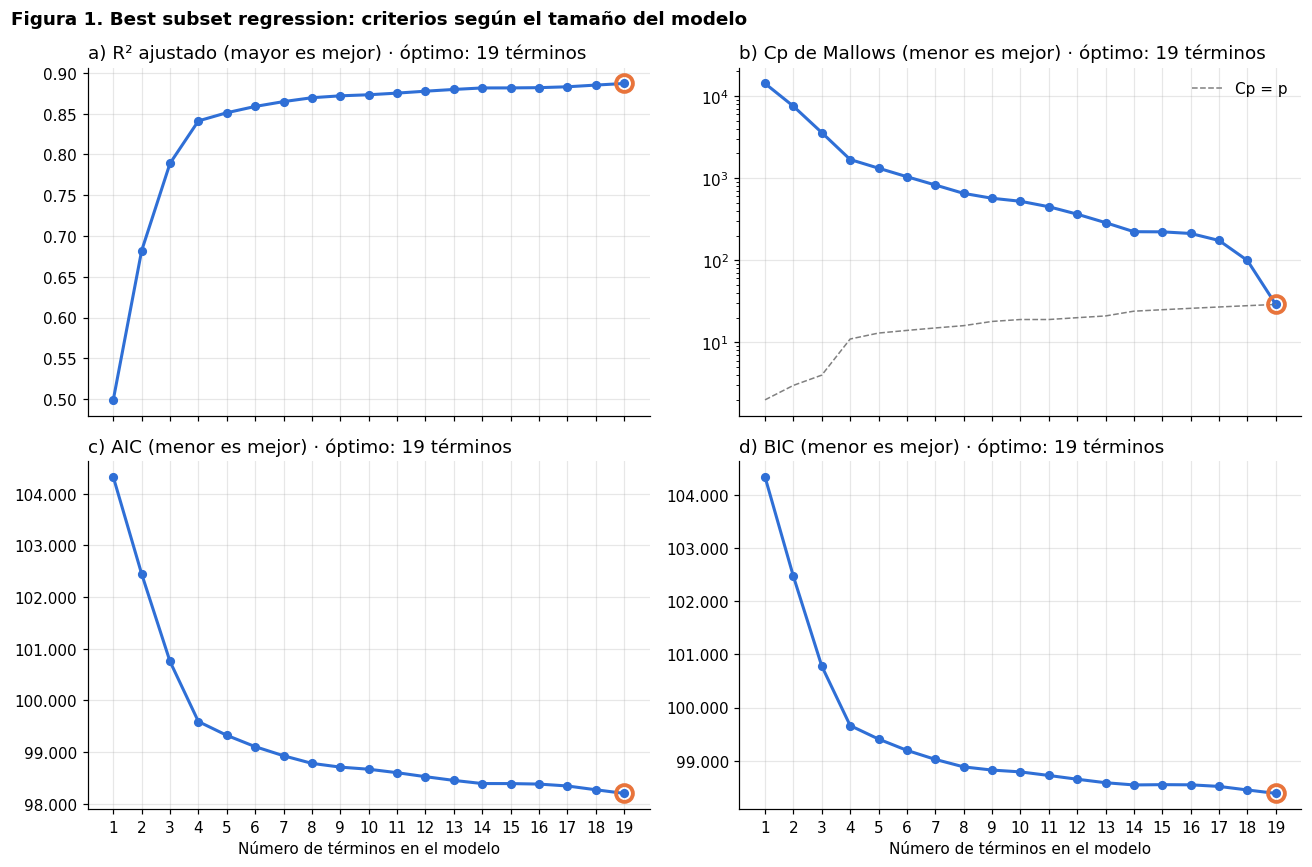

In [5]:
mejor_tamano = {
    "R2_ajustado": mejores_por_tamano.loc[mejores_por_tamano["R2_ajustado"].idxmax(), "n_terminos"],
    "Cp": mejores_por_tamano.loc[mejores_por_tamano["Cp"].idxmin(), "n_terminos"],
    "AIC": mejores_por_tamano.loc[mejores_por_tamano["AIC"].idxmin(), "n_terminos"],
    "BIC": mejores_por_tamano.loc[mejores_por_tamano["BIC"].idxmin(), "n_terminos"],
}
titulos_panel = {"R2_ajustado": "a) R² ajustado (mayor es mejor)", "Cp": "b) Cp de Mallows (menor es mejor)",
                 "AIC": "c) AIC (menor es mejor)", "BIC": "d) BIC (menor es mejor)"}
fig, ejes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, (crit, titulo) in zip(ejes.flat, titulos_panel.items()):
    ax.plot(mejores_por_tamano["n_terminos"], mejores_por_tamano[crit], color=AZUL, lw=2, marker="o", ms=5)
    if crit == "Cp":
        ax.plot(mejores_por_tamano["n_terminos"], mejores_por_tamano["parametros"], color="gray", lw=1, ls="--", label="Cp = p")
        ax.set_yscale("log")
        ax.legend(frameon=False)
    elegido = mejores_por_tamano[mejores_por_tamano["n_terminos"] == mejor_tamano[crit]]
    ax.plot(elegido["n_terminos"], elegido[crit], "o", ms=11, mfc="none", mec=NARANJA, mew=2.5)
    ax.set_title(f"{titulo} · óptimo: {mejor_tamano[crit]} términos", loc="left")
    if crit in ("AIC", "BIC"):
        ax.yaxis.set_major_formatter(miles)
for ax in ejes[1]:
    ax.set_xlabel("Número de términos en el modelo")
ax.set_xticks(range(1, len(terminos) + 1))
fig.suptitle("Figura 1. Best subset regression: criterios según el tamaño del modelo", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

### 1.2 Criterios AIC y BIC

Mejores modelos según cada criterio entre todos los subconjuntos posibles. Una diferencia de AIC o BIC menor que 2 respecto al mínimo indica que los modelos son prácticamente equivalentes.

In [6]:
mejor_aic = todos_subconjuntos.loc[todos_subconjuntos["AIC"].idxmin()]
mejor_bic = todos_subconjuntos.loc[todos_subconjuntos["BIC"].idxmin()]
terminos_aic = [terminos[i] for i in mejor_aic["subconjunto"]]
terminos_bic = [terminos[i] for i in mejor_bic["subconjunto"]]


def top_modelos(criterio, cuantos=5):
    top = todos_subconjuntos.nsmallest(cuantos, criterio).copy()
    top[f"diferencia_{criterio}"] = top[criterio] - top[criterio].min()
    top["terminos"] = top["subconjunto"].apply(lambda s: ", ".join(terminos[i] for i in s))
    return top[["n_terminos", "parametros", criterio, f"diferencia_{criterio}", "terminos"]]


mostrar(top_modelos("AIC"), "Criterio AIC: los 5 mejores modelos entre todos los subconjuntos", decimales=2)
mostrar(top_modelos("BIC"), "Criterio BIC: los 5 mejores modelos entre todos los subconjuntos", decimales=2)

ajuste_aic, ajuste_bic = ajustar(terminos_aic), ajustar(terminos_bic)
# Comprobación: el cálculo rápido coincide con statsmodels
for nombre_crit, fila_crit, ajuste_crit in [("AIC", mejor_aic, ajuste_aic), ("BIC", mejor_bic, ajuste_bic)]:
    assert int(ajuste_crit.df_model + 1) == fila_crit["parametros"]
    assert np.isclose(ajuste_crit.aic, fila_crit["AIC"]) and np.isclose(ajuste_crit.bic, fila_crit["BIC"])

n_terminos,parametros,AIC,diferencia_AIC,terminos
19,29,"98.203,84","0,00","Size_sqf, YearBuilt, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
18,28,"98.274,13","70,28","Size_sqf, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
18,28,"98.341,09","137,25","Size_sqf, YearBuilt, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
17,27,"98.347,34","143,50","Size_sqf, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
18,28,"98.357,19","153,35","Size_sqf, YearBuilt, YrSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"


n_terminos,parametros,BIC,diferencia_BIC,terminos
19,29,"98.387,26","0,00","Size_sqf, YearBuilt, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
18,28,"98.451,21","63,96","Size_sqf, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
17,27,"98.518,11","130,85","Size_sqf, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
18,28,"98.518,18","130,92","Size_sqf, YearBuilt, YrSold, MonthSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"
18,28,"98.534,28","147,03","Size_sqf, YearBuilt, YrSold, Floor, N_Parkinglot_Ground, N_Parkinglot_Basement, N_APT, N_manager, N_elevators, N_FacilitiesInApt, N_FacilitiesNearBy_Total, N_SchoolNearBy_Total, HallwayType, HeatingType, AptManageType, TimeToBusStop, TimeToSubway, SubwayStation"


C:\Users\Sebastian\AppData\Local\Temp\ipykernel_22284\1709453744.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(y_precio, Xm).fit()
C:\Users\Sebastian\AppData\Local\Temp\ipykernel_22284\1709453744.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(y_precio, Xm).fit()


### 1.3 Backward elimination

In [7]:
alfa_salida, alfa_entrada = 0.05, 0.05


def prueba_f_termino(lista_grande, lista_chica):
    """Prueba F parcial: ¿aportan los términos que están en lista_grande y no en lista_chica?"""
    rss_g, p_g = rss_y_rango(lista_grande)
    rss_c, p_c = rss_y_rango(lista_chica)
    gl_num = p_g - p_c
    if gl_num == 0:  # el término es combinación lineal de los demás: no aporta nada
        return np.nan, 1.0, 0
    estad_f = ((rss_c - rss_g) / gl_num) / (rss_g / (n_obs - p_g))
    return estad_f, float(stats.f.sf(estad_f, gl_num, n_obs - p_g)), gl_num


def eliminacion_backward(alfa=alfa_salida):
    actuales, pasos = list(terminos), []
    while actuales:
        pruebas = {t: prueba_f_termino(actuales, [s for s in actuales if s != t]) for t in actuales}
        peor = max(pruebas, key=lambda t: (pruebas[t][1], -np.nan_to_num(pruebas[t][0], nan=-1)))
        estad_f, p_valor, gl = pruebas[peor]
        if p_valor <= alfa:
            break
        actuales.remove(peor)
        pasos.append({"paso": len(pasos) + 1, "termino_eliminado": peor, "gl": gl, "F": estad_f, "p_valor": p_valor,
                      "AIC_resultante": criterio_informacion(*rss_y_rango(actuales))[0]})
    return actuales, pd.DataFrame(pasos)


terminos_backward, pasos_backward = eliminacion_backward()
if pasos_backward.empty:
    display(HTML(f"<b>Backward elimination:</b> no se elimina ningún término; en el modelo completo todos tienen "
                 f"p-valor ≤ {coma(alfa_salida)} en la prueba F parcial."))
else:
    mostrar(pasos_backward, f"Backward elimination (se elimina el término con mayor p-valor mientras p > {coma(alfa_salida)})", decimales=4)
ajuste_backward = ajustar(terminos_backward)
pruebas_finales_backward = pd.DataFrame(
    [{"termino": t, **dict(zip(["F", "p_valor", "gl"], prueba_f_termino(terminos_backward, [s for s in terminos_backward if s != t])))}
     for t in terminos_backward]).sort_values("p_valor")
mostrar(pruebas_finales_backward, "Prueba F parcial de cada término en el modelo final (backward)", decimales=4)

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_22284\1709453744.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(y_precio, Xm).fit()


termino,F,p_valor,gl
Size_sqf,"4.519,7321","0,0000",1
YrSold,"3.227,0435","0,0000",1
SubwayStation,"211,2934","0,0000",5
N_elevators,"257,7789","0,0000",1
Floor,"253,6213","0,0000",1
N_FacilitiesInApt,"234,4648","0,0000",1
AptManageType,"220,1855","0,0000",1
TimeToSubway,"113,0151","0,0000",2
HeatingType,"214,3592","0,0000",1
TimeToBusStop,"103,0807","0,0000",2


### 1.4 Stepwise regression

In [8]:
def regresion_stepwise(alfa_in=alfa_entrada, alfa_out=0.10, max_pasos=100):
    actuales, pasos = [], []
    for _ in range(max_pasos):
        cambio = False
        # Paso hacia adelante: entra el término con menor p-valor, si es menor que alfa_in
        candidatos = [t for t in terminos if t not in actuales]
        if candidatos:
            pruebas = {t: prueba_f_termino(actuales + [t], actuales) for t in candidatos}
            mejor = min(pruebas, key=lambda t: (pruebas[t][1], -np.nan_to_num(pruebas[t][0], nan=-1)))
            if pruebas[mejor][1] < alfa_in:
                actuales.append(mejor)
                cambio = True
                pasos.append({"paso": len(pasos) + 1, "accion": "entra", "termino": mejor, "gl": pruebas[mejor][2],
                              "F": pruebas[mejor][0], "p_valor": pruebas[mejor][1],
                              "AIC_resultante": criterio_informacion(*rss_y_rango(actuales))[0]})
        # Paso hacia atrás: sale el término con mayor p-valor, si es mayor que alfa_out
        if len(actuales) > 1:
            pruebas = {t: prueba_f_termino(actuales, [s for s in actuales if s != t]) for t in actuales}
            peor = max(pruebas, key=lambda t: pruebas[t][1])
            if pruebas[peor][1] > alfa_out:
                actuales.remove(peor)
                cambio = True
                pasos.append({"paso": len(pasos) + 1, "accion": "sale", "termino": peor, "gl": pruebas[peor][2],
                              "F": pruebas[peor][0], "p_valor": pruebas[peor][1],
                              "AIC_resultante": criterio_informacion(*rss_y_rango(actuales))[0]})
        if not cambio:
            break
    return actuales, pd.DataFrame(pasos)


terminos_stepwise, pasos_stepwise = regresion_stepwise()
mostrar(pasos_stepwise, f"Stepwise regression (entra si p < {coma(alfa_entrada)}; sale si p > 0,10)", decimales=4)
ajuste_stepwise = ajustar(terminos_stepwise)

paso,accion,termino,gl,F,p_valor,AIC_resultante
1,entra,Size_sqf,1,"4.108,0389","0,0000","104.321,5032"
2,entra,YrSold,1,"2.373,7375","0,0000","102.447,5105"
3,entra,YearBuilt,1,"2.095,1229","0,0000","100.754,0008"
4,entra,N_FacilitiesInApt,1,"519,2057","0,0000","100.266,4112"
5,entra,SubwayStation,7,"120,8423","0,0000","99.508,9264"
6,entra,HallwayType,2,"96,5487","0,0000","99.323,5850"
7,entra,Floor,1,"221,2295","0,0000","99.109,3189"
8,sale,YearBuilt,1,"0,0873","0,7676","99.107,4065"
9,entra,MonthSold,1,"181,3918","0,0000","98.931,2565"
10,entra,N_Parkinglot_Ground,1,"151,2518","0,0000","98.784,1442"


C:\Users\Sebastian\AppData\Local\Temp\ipykernel_22284\1709453744.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(y_precio, Xm).fit()


### 1.5 Comparación de los métodos

In [9]:
modelos_seleccion = {
    "Modelo completo (19 términos)": (terminos, ajuste_completo),
    "Criterio AIC (best subset)": (terminos_aic, ajuste_aic),
    "Criterio BIC (best subset)": (terminos_bic, ajuste_bic),
    "Backward elimination": (terminos_backward, ajuste_backward),
    "Stepwise regression": (terminos_stepwise, ajuste_stepwise),
}
comparacion_modelos_pd = pd.DataFrame([
    {"metodo": nombre, "n_terminos": len(lista), **resumen_ajuste(aj)}
    for nombre, (lista, aj) in modelos_seleccion.items()
])
mostrar(comparacion_modelos_pd, "Comparación de los modelos seleccionados", decimales=4)

presencia_pd = pd.DataFrame(
    {nombre: ["✔" if t in lista else "" for t in terminos] for nombre, (lista, _) in list(modelos_seleccion.items())[1:]},
    index=terminos).rename_axis("termino").reset_index()
presencia_pd["veces_seleccionado"] = (presencia_pd.iloc[:, 1:] == "✔").sum(axis=1)
mostrar(presencia_pd.sort_values("veces_seleccionado", ascending=False, kind="stable"), "Términos elegidos por cada método")

metodo,n_terminos,parametros,R2,R2_ajustado,AIC,BIC,RMSE
Modelo completo (19 términos),19,29,"0,8879","0,8871","98.203,8423","98.387,2551","35.611,0723"
Criterio AIC (best subset),19,29,"0,8879","0,8871","98.203,8423","98.387,2551","35.611,0723"
Criterio BIC (best subset),19,29,"0,8879","0,8871","98.203,8423","98.387,2551","35.611,0723"
Backward elimination,19,29,"0,8879","0,8871","98.203,8423","98.387,2551","35.611,0723"
Stepwise regression,17,27,"0,8831","0,8824","98.369,6877","98.540,4513","36.351,9891"


termino,Criterio AIC (best subset),Criterio BIC (best subset),Backward elimination,Stepwise regression,veces_seleccionado
Size_sqf,✔,✔,✔,✔,4
YearBuilt,✔,✔,✔,✔,4
YrSold,✔,✔,✔,✔,4
MonthSold,✔,✔,✔,✔,4
Floor,✔,✔,✔,✔,4
N_Parkinglot_Basement,✔,✔,✔,✔,4
N_APT,✔,✔,✔,✔,4
N_elevators,✔,✔,✔,✔,4
N_FacilitiesInApt,✔,✔,✔,✔,4
N_FacilitiesNearBy_Total,✔,✔,✔,✔,4


### 1.6 ¿Bastan 7 términos?

En la Figura 1, AIC y BIC bajan mucho en los primeros términos y después la curva se aplana. Se eligen 7 términos: `Size_sqf`, `YrSold`, `MonthSold`, `Floor`, `N_FacilitiesInApt`, `HallwayType` y `SubwayStation`. Aquí se revisa: (a) si esos 7 son el mejor modelo de 7 términos según cada criterio, (b) cuánto bajan AIC y BIC con cada término adicional y (c) cuánto explica el modelo de 7 términos frente al de 5 y al modelo completo, y cuánto aporta cada uno de sus términos.

Regla usual para AIC y BIC: una diferencia mayor que 10 entre dos modelos es evidencia fuerte a favor del de menor valor.

In [10]:
todos_subconjuntos["R2_ajustado"] = 1 - (todos_subconjuntos["RSS"] / (n_obs - todos_subconjuntos["parametros"])) / (sst / (n_obs - 1))

# Los 7 términos elegidos para el modelo
terminos_7 = ["Size_sqf", "YrSold", "MonthSold", "Floor", "N_FacilitiesInApt", "HallwayType", "SubwayStation"]

# a) ¿Qué modelo de 7 términos elige cada criterio? ¿Coincide con los 7 elegidos?
del_tamano = todos_subconjuntos[todos_subconjuntos["n_terminos"] == 7]
filas_eleccion = []
for crit, mejor_fila in [("R² ajustado (máximo)", del_tamano.loc[del_tamano["R2_ajustado"].idxmax()]),
                         ("AIC (mínimo)", del_tamano.loc[del_tamano["AIC"].idxmin()]),
                         ("BIC (mínimo)", del_tamano.loc[del_tamano["BIC"].idxmin()])]:
    elegidos = [terminos[i] for i in mejor_fila["subconjunto"]]
    filas_eleccion.append({"criterio": crit, "parametros": mejor_fila["parametros"],
                           "R2_ajustado": mejor_fila["R2_ajustado"], "AIC": mejor_fila["AIC"], "BIC": mejor_fila["BIC"],
                           "coincide_con_los_7_elegidos": "sí" if set(elegidos) == set(terminos_7) else "no",
                           "terminos": ", ".join(elegidos)})
eleccion_pd = pd.DataFrame(filas_eleccion)
mostrar(eleccion_pd, "Mejor modelo de 7 términos según cada criterio (entre los 50.388 modelos de 7 términos)", decimales=4)

criterio,parametros,R2_ajustado,AIC,BIC,coincide_con_los_7_elegidos,terminos
R² ajustado (máximo),15,"0,8649","98.931,2565","99.026,1252",sí,"Size_sqf, YrSold, MonthSold, Floor, N_FacilitiesInApt, HallwayType, SubwayStation"
AIC (mínimo),15,"0,8649","98.931,2565","99.026,1252",sí,"Size_sqf, YrSold, MonthSold, Floor, N_FacilitiesInApt, HallwayType, SubwayStation"
BIC (mínimo),15,"0,8649","98.931,2565","99.026,1252",sí,"Size_sqf, YrSold, MonthSold, Floor, N_FacilitiesInApt, HallwayType, SubwayStation"


n_terminos,parametros,R2_ajustado,AIC,BIC,mejora_R2_ajustado,mejora_AIC,mejora_BIC
2,3,"0,6821","102.447,5105","102.466,4843","0,1830","1.873,9927","1.867,6681"
3,4,"0,7892","100.754,0008","100.779,2991","0,1071","1.693,5098","1.687,1852"
4,11,"0,8412","99.592,4050","99.661,9753","0,0520","1.161,5958","1.117,3238"
5,13,"0,8512","99.326,4027","99.408,6223","0,0100","266,0022","253,3531"
6,14,"0,8589","99.107,4065","99.195,9506","0,0077","218,9962","212,6716"
7,15,"0,8649","98.931,2565","99.026,1252","0,0059","176,1500","169,8254"
8,16,"0,8696","98.784,1442","98.885,3374","0,0048","147,1124","140,7878"
9,18,"0,8720","98.711,5693","98.825,4117","0,0023","72,5749","59,9258"
10,19,"0,8732","98.670,9269","98.791,0939","0,0013","40,6423","34,3178"
11,19,"0,8753","98.603,9711","98.724,1381","0,0020","66,9558","66,9558"


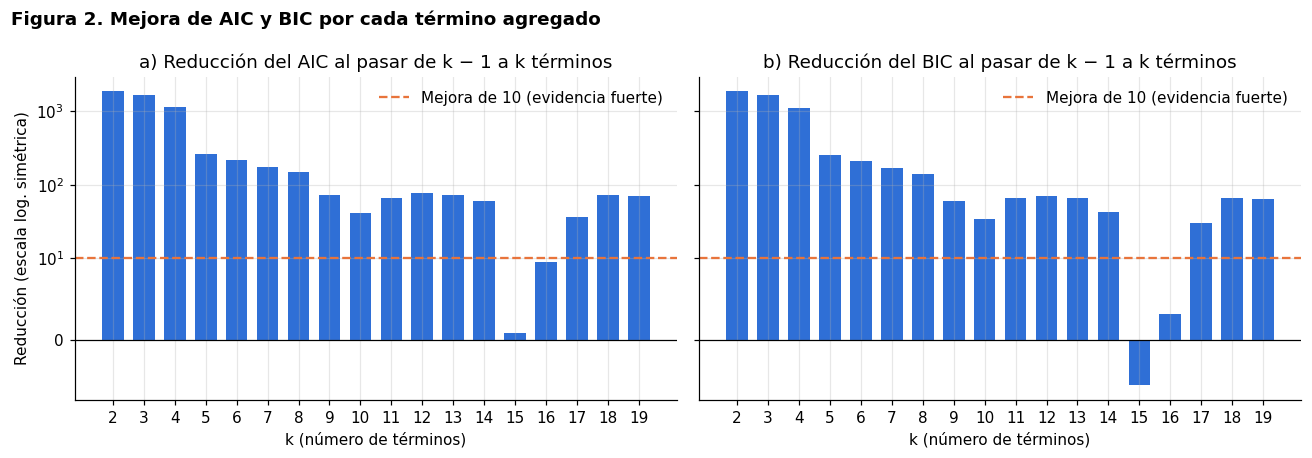

In [11]:
# b) Mejora de AIC y BIC al pasar del mejor modelo de k términos al de k + 1
mejora_pd = mejores_por_tamano[["n_terminos", "parametros", "R2_ajustado", "AIC", "BIC"]].copy()
mejora_pd["mejora_R2_ajustado"] = mejora_pd["R2_ajustado"].diff()
mejora_pd["mejora_AIC"] = -mejora_pd["AIC"].diff()
mejora_pd["mejora_BIC"] = -mejora_pd["BIC"].diff()
mostrar(mejora_pd.iloc[1:], "Mejora al agregar un término (mejor modelo de cada tamaño)", decimales=4)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, letra, crit in zip(ejes, "ab", ["AIC", "BIC"]):
    ax.bar(mejora_pd["n_terminos"].iloc[1:], mejora_pd[f"mejora_{crit}"].iloc[1:], color=AZUL, width=0.7)
    ax.axhline(10, color=NARANJA, lw=1.5, ls="--", label="Mejora de 10 (evidencia fuerte)")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_yscale("symlog", linthresh=10)  # simétrica: permite ver mejoras negativas (el criterio empeora)
    ax.set_xticks(range(2, len(terminos) + 1))
    ax.set(title=f"{letra}) Reducción del {crit} al pasar de k − 1 a k términos", xlabel="k (número de términos)")
    ax.legend(frameon=False)
ejes[0].set_ylabel("Reducción (escala log. simétrica)")
fig.suptitle("Figura 2. Mejora de AIC y BIC por cada término agregado", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [12]:
# c) ¿Explica lo suficiente el modelo de 7 términos frente al modelo completo?
terminos_5 = [terminos[i] for i in mejores_por_tamano.loc[mejores_por_tamano["n_terminos"] == 5, "subconjunto"].iloc[0]]
filas_suficiencia = []
for nombre_mod, lista in [("Mejor de 5 términos (referencia)", terminos_5), ("7 términos elegidos", terminos_7),
                          ("Modelo completo (AIC y BIC)", terminos)]:
    aj = ajustar(lista)
    estad_f, p_valor, gl = prueba_f_termino(terminos, lista) if len(lista) < len(terminos) else (np.nan, np.nan, 0)
    filas_suficiencia.append({"modelo": nombre_mod, "n_terminos": len(lista), **resumen_ajuste(aj),
                              "pct_del_R2_completo": aj.rsquared / ajuste_completo.rsquared * 100,
                              "dif_AIC": aj.aic - ajuste_completo.aic, "dif_BIC": aj.bic - ajuste_completo.bic,
                              "F_vs_completo": estad_f, "gl_F": gl, "p_valor_F": p_valor})
suficiencia_pd = pd.DataFrame(filas_suficiencia)
mostrar(suficiencia_pd, "Modelo de 7 términos frente al de 5 términos y al modelo completo", decimales=4)

# Aporte de cada término dentro del modelo de 7 (prueba F parcial)
aporte_7 = pd.DataFrame(
    [{"termino": t, **dict(zip(["F", "p_valor", "gl"], prueba_f_termino(terminos_7, [s for s in terminos_7 if s != t])))}
     for t in terminos_7]).sort_values("F", ascending=False)
mostrar(aporte_7, "Prueba F parcial de cada término en el modelo de 7 términos", decimales=4)

ajuste_7 = ajustar(terminos_7)
display(HTML("<b>Coeficientes del modelo de 7 términos</b>"))
display(ajuste_7.summary().tables[1])

C:\Users\Sebastian\AppData\Local\Temp\ipykernel_22284\1709453744.py:33: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  return sm.OLS(y_precio, Xm).fit()


modelo,n_terminos,parametros,R2,R2_ajustado,AIC,BIC,RMSE,pct_del_R2_completo,dif_AIC,dif_BIC,F_vs_completo,gl_F,p_valor_F
Mejor de 5 términos (referencia),5,13,"0,8516","0,8512","99.326,4027","99.408,6223","40.961,6911","95,9193","1.122,5605","1.021,3672","82,6879",16,"0,0000"
7 términos elegidos,7,15,"0,8653","0,8649","98.931,2565","99.026,1252","39.026,6277","97,4609","727,4143","638,8701","58,7997",14,"0,0000"
Modelo completo (AIC y BIC),19,29,"0,8879","0,8871","98.203,8423","98.387,2551","35.611,0723","100,0000","0,0000","0,0000",nan,0,nan


termino,F,p_valor,gl
Size_sqf,"6.326,2312","0,0000",1
YrSold,"3.080,4898","0,0000",1
N_FacilitiesInApt,"1.274,0558","0,0000",1
Floor,"244,6186","0,0000",1
MonthSold,"181,3918","0,0000",1
HallwayType,"176,8868","0,0000",2
SubwayStation,"133,5641","0,0000",7


,coef,std err,t,P>|t|,[0.025,0.975]
const,-2.514e+07,4.52e+05,-55.600,0.000,-2.6e+07,-2.43e+07
Size_sqf,158.9793,1.999,79.538,0.000,155.061,162.898
YrSold,1.247e+04,224.624,55.502,0.000,1.2e+04,1.29e+04
MonthSold,2499.6896,185.600,13.468,0.000,2135.814,2863.566
Floor,1331.9470,85.161,15.640,0.000,1164.985,1498.909
N_FacilitiesInApt,1.364e+04,382.271,35.694,0.000,1.29e+04,1.44e+04
HallwayType_mixed,-5.06e+04,2877.372,-17.587,0.000,-5.62e+04,-4.5e+04
HallwayType_corridor,-4.036e+04,2864.409,-14.091,0.000,-4.6e+04,-3.47e+04
SubwayStation_Myung-duk,2.483e+04,2365.054,10.498,0.000,2.02e+04,2.95e+04
SubwayStation_Bangoge,2.385e+04,3534.333,6.749,0.000,1.69e+04,3.08e+04


### 1.7 Resultados y opinión

**Lo que muestran los métodos**

- **AIC, BIC y backward elimination eligen el mismo modelo: los 19 términos** (29 parámetros, R² ajustado = 0,887, RMSE = 35.611). En el *best subset*, el modelo completo tiene el menor AIC y el menor BIC entre los 524.288 posibles, y quitar cualquier término empeora el AIC en al menos 70 puntos. En el backward elimination, todos los términos del modelo completo tienen p-valor < 0,001, así que no se elimina ninguno.
- **El stepwise se detiene en 17 términos** (R² ajustado = 0,882): no incluye `N_Parkinglot_Ground` ni `N_manager`. Su AIC es 165,8 puntos mayor que el del modelo completo. Al agregar un término a la vez, ninguno de los dos aporta lo suficiente por sí solo, pero juntos sí; es la limitación conocida de los métodos paso a paso.

**¿Bastan 7 términos? (sección 1.6)**

- **Los 7 términos elegidos son el mejor modelo de su tamaño.** Entre los 50.388 modelos posibles de 7 términos, el de mayor R² ajustado, el de menor AIC y el de menor BIC son el mismo: `Size_sqf`, `YrSold`, `MonthSold`, `Floor`, `N_FacilitiesInApt`, `HallwayType` y `SubwayStation`.
- **Explican casi todo lo que explica el modelo completo.** El R² es 0,865 (R² ajustado también 0,865), el 97,5 % del R² del modelo completo (0,888). El error típico (RMSE) es 39.027, un 9,6 % mayor que el del modelo completo (35.611).
- **Mejoran claramente al modelo de 5 términos.** Agregar `MonthSold` y `Floor` baja el AIC en 395,1 puntos y el BIC en 382,5, sube el R² ajustado de 0,851 a 0,865 y baja el RMSE de 40.962 a 39.027.
- **Todos los términos aportan.** En la prueba F parcial, cada uno de los 7 tiene p < 0,001. El que más aporta es `Size_sqf` (F = 6.326), seguido de `YrSold` (3.080) y `N_FacilitiesInApt` (1.274). Entre los coeficientes, solo la indicadora de *Chil-sung-market* no es significativa (p = 0,15).
- **Pero AIC y BIC siguen prefiriendo el modelo completo.** Su mínimo está en 19 términos: el modelo de 7 tiene un AIC 727,4 puntos y un BIC 638,9 puntos mayores, y la prueba F indica que los 12 términos restantes aportan (F = 58,8; p < 0,001). El octavo término (`N_Parkinglot_Ground`) todavía baja el AIC en 147 puntos (Figura 2). **Según AIC y BIC, el modelo de 7 términos no es el seleccionado.**
- **"Término" no es lo mismo que "parámetro".** `SubwayStation` aporta 7 indicadoras y `HallwayType` 2, así que el modelo de 7 términos estima 15 parámetros.

**Opinión**

- El modelo de 7 términos es una **elección razonable por parsimonia**: con 15 parámetros en lugar de 29 explica el 86,5 % de la variabilidad del precio, y sus términos son fáciles de interpretar. Es una decisión de criterio propio, no el resultado de AIC, BIC, backward o stepwise, y conviene reportarlo así.
- Cuatro de los 7 términos describen al **departamento y la venta**: `Size_sqf`, `YrSold`, `MonthSold` y `Floor`. Los otros tres describen al **edificio**: `N_FacilitiesInApt`, `HallwayType` y `SubwayStation`.
- Como solo hay 26 edificios, los términos de edificio funcionan en buena parte como un identificador del edificio. Sus coeficientes deben leerse con cuidado, y no conviene usar el modelo para edificios que no están en los datos.

## 2. Multicolinealidad de los 7 términos

- **Correlación de Pearson** entre las cinco variables numéricas: `Size_sqf`, `YrSold`, `MonthSold`, `Floor` y `N_FacilitiesInApt`.
- **V de Cramér** entre las dos variables categóricas, `HallwayType` y `SubwayStation`, con su tabla cruzada. Va de 0 (sin asociación) a 1 (asociación perfecta).
- **GVIF (VIF generalizado, Fox y Monette, 1992).** Complementa a las dos medidas anteriores, porque también capta la relación entre variables numéricas y categóricas. El VIF clásico mide cuánto se infla la varianza de un coeficiente por su relación con los demás términos; para una variable categórica con varias indicadoras se usa el GVIF, que mide el término completo. Para comparar términos con distinto número de indicadoras (gl) se usa **GVIF^(1/(2·gl))**, que equivale a √VIF. Referencias usuales: VIF > 5 (√5 ≈ 2,24) indica multicolinealidad moderada y VIF > 10 (√10 ≈ 3,16), alta.
- **Número de condición** de la matriz de diseño con las columnas estandarizadas: por encima de 30 indica multicolinealidad fuerte.

In [13]:
def diseno(d):
    """Matriz de diseño sin intercepto: numéricas + indicadoras (sin la categoría de referencia)."""
    bloques, columnas_de = [d[numericos].astype(float)], {c: [c] for c in numericos}
    for c, niveles in categoricos.items():
        ind = pd.get_dummies(pd.Categorical(d[c], categories=niveles), prefix=c, dtype=float).iloc[:, 1:]
        ind.index = d.index
        bloques.append(ind)
        columnas_de[c] = list(ind.columns)
    return pd.concat(bloques, axis=1), columnas_de


def gvif(X, columnas_de):
    R = np.corrcoef(X.values, rowvar=False)
    det_total = np.linalg.det(R)
    filas = []
    for t, cols in columnas_de.items():
        dentro = [X.columns.get_loc(c) for c in cols]
        fuera = [i for i in range(X.shape[1]) if i not in dentro]
        valor = np.linalg.det(R[np.ix_(dentro, dentro)]) * np.linalg.det(R[np.ix_(fuera, fuera)]) / det_total
        filas.append({"termino": t, "gl": len(cols), "GVIF": valor, "GVIF_ajustado": valor ** (1 / (2 * len(cols)))})
    return pd.DataFrame(filas)


def numero_condicion(X):
    Z = (X - X.mean()) / X.std()
    s = np.linalg.svd(Z.values, compute_uv=False)
    return s.max() / s.min()


def v_cramer(a, b):
    tabla = pd.crosstab(a, b)
    chi2, p, _, _ = chi2_contingency(tabla)
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))), p


X_train, columnas_de = diseno(train)

# a) Correlaciones entre numéricas
mostrar(train[numericos].corr().round(3).reset_index().rename(columns={"index": "variable"}),
        "Correlación de Pearson entre las variables numéricas", decimales=3)

# b) Asociación entre las categóricas
v, p = v_cramer(train["SubwayStation"], train["HallwayType"])
display(HTML(f"<b>V de Cramér entre SubwayStation y HallwayType:</b> {v:.3f} (p = {p:.2g})".replace(".", ",")))
mostrar(pd.crosstab(train["SubwayStation"], train["HallwayType"]).reset_index(),
        "Departamentos por SubwayStation y HallwayType", decimales=0)

# c) GVIF y d) número de condición
gvif_pd = gvif(X_train, columnas_de)
mostrar(gvif_pd, "GVIF de los 7 términos", decimales=3)
display(HTML(f"<b>Número de condición de la matriz de diseño estandarizada:</b> {coma(numero_condicion(X_train))}"))

variable,Size_sqf,YrSold,MonthSold,Floor,N_FacilitiesInApt
Size_sqf,"1,000","-0,083","0,098","0,195","0,137"
YrSold,"-0,083","1,000","-0,179","0,061","0,220"
MonthSold,"0,098","-0,179","1,000","-0,009","-0,028"
Floor,"0,195","0,061","-0,009","1,000","0,266"
N_FacilitiesInApt,"0,137","0,220","-0,028","0,266","1,000"


SubwayStation,corridor,mixed,terraced
Bangoge,0,525,0
Banwoldang,44,0,470
Chil-sung-market,0,75,0
Daegu,45,0,15
Kyungbuk_uni_hospital,51,0,1.125
Myung-duk,206,583,256
Sin-nam,54,0,405
no_subway_nearby,36,0,234


termino,gl,GVIF,GVIF_ajustado
Size_sqf,1,"1,531","1,237"
YrSold,1,"1,147","1,071"
MonthSold,1,"1,063","1,031"
Floor,1,"1,135","1,065"
N_FacilitiesInApt,1,"2,122","1,457"
HallwayType,2,"7,133","1,634"
SubwayStation,7,"6,846","1,147"


## 3. Conclusión sobre la multicolinealidad

**Es prudente seguir con los 7 términos.**

- **Variables numéricas (Pearson):** las cinco casi no están correlacionadas entre sí. La mayor correlación en valor absoluto es 0,27, entre `Floor` y `N_FacilitiesInApt`; le siguen `YrSold` y `N_FacilitiesInApt` (0,22) y `Size_sqf` y `Floor` (0,20). Las dos variables nuevas no generan problemas: `MonthSold` tiene correlaciones de 0,18 o menos y `Floor` de 0,27 o menos.
- **Variables categóricas (V de Cramér):** la asociación entre `SubwayStation` y `HallwayType` es fuerte (V = 0,65). Algunas estaciones tienen un solo tipo de pasillo (*Bangoge* y *Chil-sung-market* solo *mixed*). Esto obliga a leer el efecto de cada una **controlando por la otra**, no por separado: juntas describen la ubicación y el tipo de edificio.
- **GVIF:** todos los GVIF^(1/(2·gl)) están entre 1,03 y 1,63, lejos de 2,24 (VIF = 5). El GVIF más alto es el de `HallwayType`: 7,13 con 2 gl, que equivale a 1,63. Como `HallwayType` tiene 2 gl, ese 7,13 no se compara con el umbral de 10 del VIF clásico, sino a través del valor ajustado (1,63 frente a 3,16). Por eso, aunque la asociación entre las dos categóricas es fuerte, no llega a inflar los errores estándar.
- **Número de condición:** 4,69, muy por debajo de 30.
- En el modelo de 7 términos (sección 1.6), todos los coeficientes son significativos menos la indicadora de *Chil-sung-market* (p = 0,15), que tiene solo 75 departamentos.

## 4. Estructura del modelo

Aquí se busca la ecuación que mejor relaciona `SalePrice` con los 7 términos elegidos: `Size_sqf`, `YrSold`, `MonthSold`, `Floor`, `N_FacilitiesInApt`, `HallwayType` y `SubwayStation`. Las dos categóricas entran como indicadoras, así que la pregunta es qué forma darle a cada una de las cinco numéricas y si conviene transformar `SalePrice`.

Formas candidatas para cada variable numérica:

| Forma | Cuándo conviene | Término en el modelo |
|---|---|---|
| Lineal | la relación es una recta | x |
| Logarítmica | curva suave: crece cada vez más lento | log(x) |
| Inversa | curva muy pronunciada en un extremo y luego plana | 1/x |
| Cuadrática | la pendiente cambia: crece y luego decrece, o al revés | x y (x − media)² |

En la cuadrática, el término al cuadrado se centra en la media para que x y x² no queden casi perfectamente correlacionados.

Pasos:

1. **Gráficas** de la relación de `SalePrice` con cada término (4.1) y de la relación una vez descontado el efecto de los demás (4.2).
2. **Mínimos cuadrados** con cada forma candidata, una variable a la vez (4.3).
3. **Subset regression sobre las formas:** se ajustan todas las combinaciones de formas de las 5 variables (4⁵ = 1.024) para cada escala de `SalePrice` (sin transformar, raíz cuadrada, logarítmica e inversa) y se elige la de menor BIC (4.4).
4. **Mínimos cuadrados no lineales:** se estima directamente el exponente de cada variable, para confirmar las formas elegidas (4.5).
5. **Diagnóstico de residuos** (4.6) y **modelo final** con su explicación (4.7).

### 4.1 Relación de SalePrice con cada término

Para las variables numéricas se muestran los departamentos (puntos) y la tendencia del precio: el precio medio para cada valor cuando la variable toma pocos valores, y una curva LOWESS (promedio local) cuando toma muchos. Entre paréntesis está la correlación de Pearson con el precio. Para las categóricas, la línea naranja de cada caja es la mediana y el rombo la media.

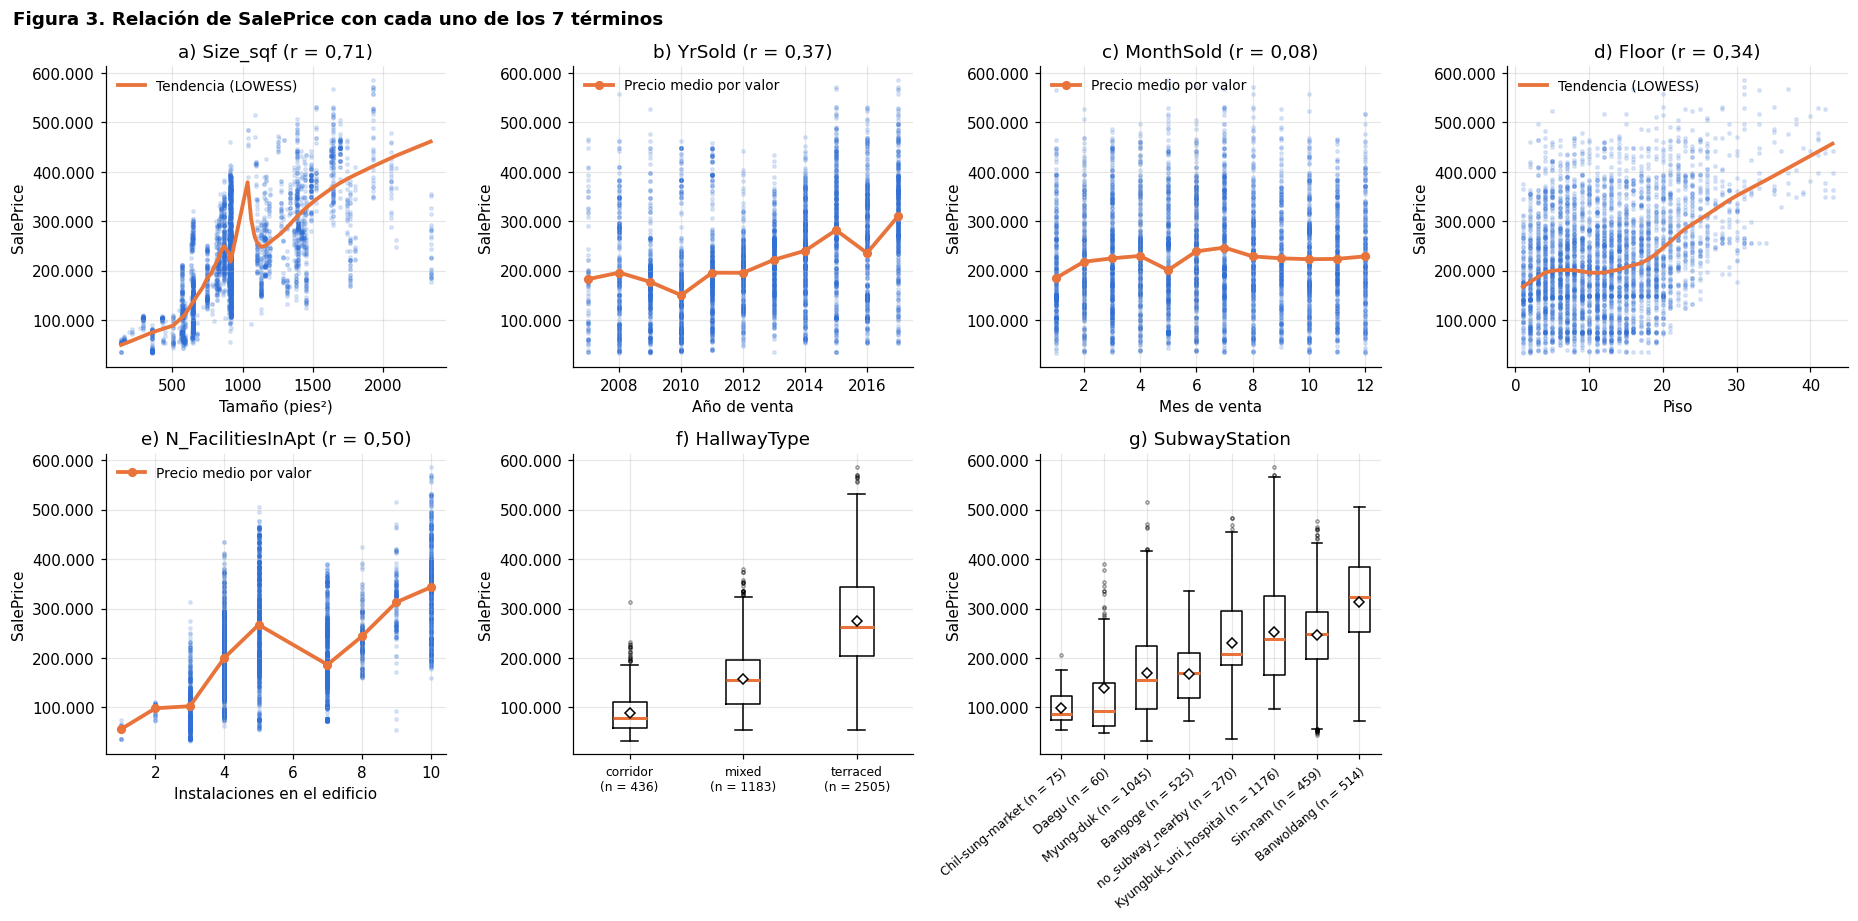

In [14]:
from itertools import product
from scipy.optimize import least_squares
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import het_breuschpagan

etiquetas_num = {"Size_sqf": "Tamaño (pies²)", "YrSold": "Año de venta", "MonthSold": "Mes de venta",
                 "Floor": "Piso", "N_FacilitiesInApt": "Instalaciones en el edificio"}
y_venta = train[respuesta].astype(float)

fig, ejes = plt.subplots(2, 4, figsize=(17, 8.5))
for ax, letra, c in zip(ejes.flat, "abcde", numericos):
    ax.scatter(train[c], y_venta, s=5, alpha=0.15, color=AZUL)
    if train[c].nunique() > 15:
        curva = lowess(y_venta, train[c], frac=0.3)
        ax.plot(curva[:, 0], curva[:, 1], color=NARANJA, lw=2.5, label="Tendencia (LOWESS)")
    else:
        medias = y_venta.groupby(train[c]).mean()
        ax.plot(medias.index, medias.values, color=NARANJA, lw=2.5, marker="o", ms=5, label="Precio medio por valor")
    r = np.corrcoef(train[c], y_venta)[0, 1]
    ax.set(title=f"{letra}) {c} (r = {coma(r)})", xlabel=etiquetas_num[c], ylabel="SalePrice")
    ax.yaxis.set_major_formatter(miles)
    ax.legend(frameon=False, loc="upper left", fontsize=9)

for ax, letra, c in zip(ejes.flat[5:7], "fg", categoricos):
    orden = y_venta.groupby(train[c]).median().sort_values().index.tolist()
    grupos = [y_venta[train[c] == v] for v in orden]
    separador = " " if c == "SubwayStation" else "\n"
    ax.boxplot(grupos, tick_labels=[f"{v}{separador}(n = {len(g)})" for v, g in zip(orden, grupos)], showmeans=True,
               medianprops={"color": NARANJA, "lw": 2}, flierprops={"markersize": 2, "alpha": 0.4},
               meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5})
    ax.set(title=f"{letra}) {c}", ylabel="SalePrice")
    ax.yaxis.set_major_formatter(miles)
    ax.tick_params(axis="x", labelsize=8)
    if c == "SubwayStation":
        plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
ejes.flat[7].axis("off")
fig.suptitle("Figura 3. Relación de SalePrice con cada uno de los 7 términos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Lectura de la Figura 3**

- **`Size_sqf`** tiene la relación más fuerte con el precio (r = 0,71): el precio sube con el tamaño, rápido al principio y más despacio en los departamentos grandes.
- **`YrSold`** baja hasta 2010 y después sube; los precios de 2015 a 2017 son los más altos.
- **`MonthSold`** casi no se relaciona con el precio (r = 0,08), salvo enero, que es más barato que el resto del año.
- **`Floor`** sube suave hasta el piso 20 y más rápido por encima.
- **`N_FacilitiesInApt`** sube con el número de instalaciones, aunque con saltos, porque cada valor corresponde a pocos edificios.
- **`HallwayType`** y **`SubwayStation`** separan bien los precios: *terraced* es mucho más caro que *mixed* y *corridor*, y *Banwoldang* es la estación más cara.

Estas son relaciones de una variable a la vez, así que parte de cada patrón puede deberse a las otras variables. Por eso la Figura 4 mira la forma de cada relación controlando por los demás términos.

### 4.2 Relación controlando por los demás términos

Un **residuo parcial** es el residuo del modelo más el efecto estimado de una variable. Muestra cómo se relaciona esa variable con el precio una vez descontado el efecto de los otros 6 términos. Si la tendencia de los puntos (naranja) se aparta de la recta del modelo lineal (negra), la relación no es lineal y conviene transformar la variable.

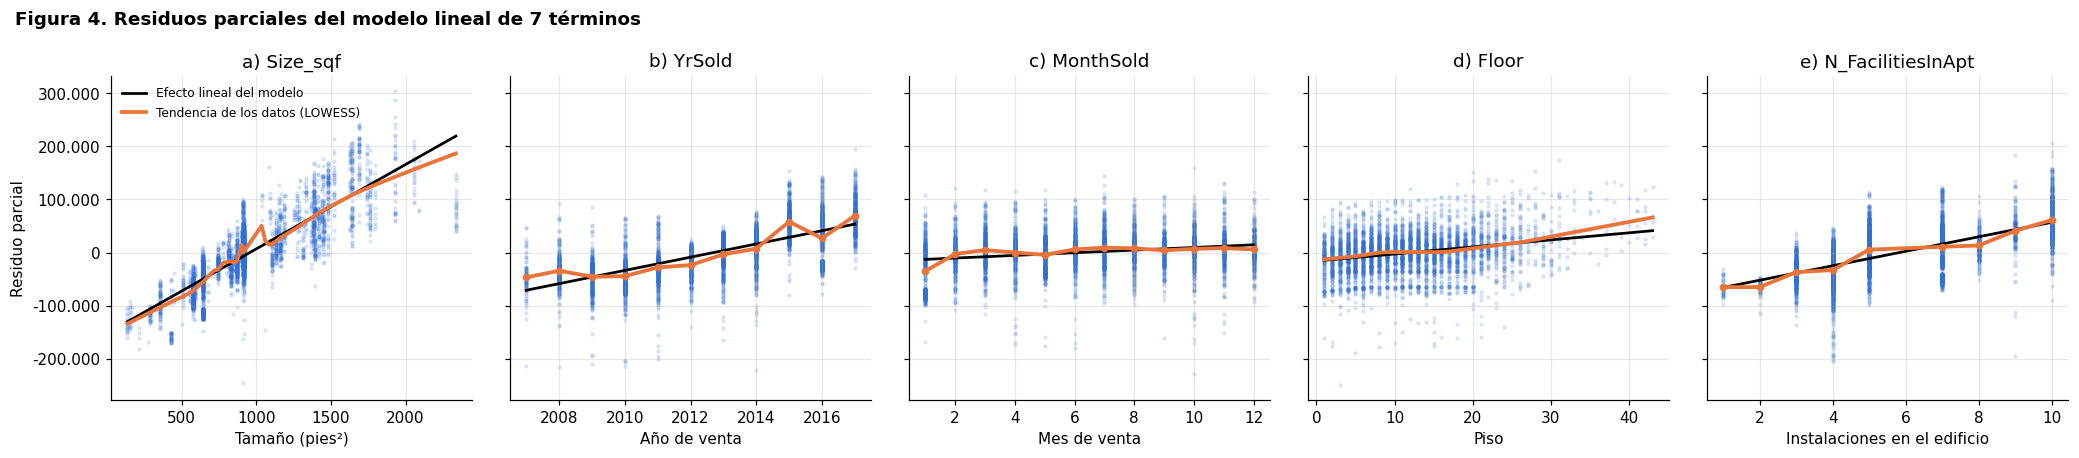

In [15]:
# Residuos parciales del modelo lineal de 7 términos: residuo + efecto lineal de la variable.
# Muestran la relación de cada variable con el precio una vez descontado el efecto de los otros 6 términos.
def graficar_residuos_parciales(ajuste, efecto, titulo, etiqueta_curva):
    fig, ejes = plt.subplots(1, 5, figsize=(19, 4.2), sharey=True)
    for ax, letra, c in zip(ejes, "abcde", numericos):
        x = train[c].astype(float)
        parcial = ajuste.resid + efecto(c, x)
        ax.scatter(x, parcial, s=4, alpha=0.12, color=AZUL)
        rejilla = np.linspace(x.min(), x.max(), 200)
        ax.plot(rejilla, efecto(c, pd.Series(rejilla)), color="black", lw=1.8, label=etiqueta_curva)
        if x.nunique() > 15:
            curva = lowess(parcial, x, frac=0.3)
            ax.plot(curva[:, 0], curva[:, 1], color=NARANJA, lw=2.5, label="Tendencia de los datos (LOWESS)")
        else:
            medias = parcial.groupby(x).mean()
            ax.plot(medias.index, medias.values, color=NARANJA, lw=2.5, marker="o", ms=4, label="Media por valor")
        ax.set(title=f"{letra}) {c}", xlabel=etiquetas_num[c])
        ax.yaxis.set_major_formatter(miles)
    ejes[0].set_ylabel("Residuo parcial")
    ejes[0].legend(frameon=False, loc="upper left", fontsize=8)
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


graficar_residuos_parciales(
    ajuste_7, lambda c, x: ajuste_7.params[c] * (x - train[c].mean()),
    "Figura 4. Residuos parciales del modelo lineal de 7 términos", "Efecto lineal del modelo")

**Lectura de la Figura 4**

- **`Size_sqf`:** la tendencia queda por debajo de la recta en los departamentos más grandes: el precio crece cada vez más despacio (curva cóncava).
- **`YrSold`:** el precio se mantiene o baja de 2007 a 2010 y luego sube: la pendiente aumenta con el tiempo (curva convexa).
- **`MonthSold`:** enero queda muy por debajo y el resto de los meses son casi iguales: una curva muy pronunciada al inicio y luego plana, el patrón de la transformación inversa.
- **`Floor`:** casi recta, con una leve curvatura hacia arriba en los pisos altos.
- **`N_FacilitiesInApt`:** sigue bien la recta.

### 4.3 Mínimos cuadrados con cada forma candidata

Se ajusta el modelo de 7 términos por mínimos cuadrados cambiando la forma de una sola variable a la vez (las demás numéricas quedan lineales). Las diferencias son respecto al modelo con todas las variables lineales; un valor negativo indica que la forma mejora el modelo.

In [16]:
formas_posibles = ["lineal", "log", "inversa", "cuadratica"]
medias_num = {c: train[c].mean() for c in numericos}


def columnas_forma(dd, c, forma):
    x = dd[c].astype(float)
    if forma == "lineal":
        return pd.DataFrame({c: x})
    if forma == "log":
        return pd.DataFrame({f"log({c})": np.log(x)})
    if forma == "inversa":
        return pd.DataFrame({f"1/{c}": 1 / x})
    # cuadrática con el término al cuadrado centrado en la media (reduce la colinealidad entre x y x²)
    return pd.DataFrame({c: x, f"({c} - media)²": (x - medias_num[c]) ** 2})


indicadoras = diseno(train)[0].drop(columns=numericos)


def X_formas(dd, formas):
    partes = [columnas_forma(dd, c, formas[c]) for c in numericos]
    return sm.add_constant(pd.concat(partes + [diseno(dd)[0].drop(columns=numericos)], axis=1))


def ajustar_formas(formas, y=y_venta):
    return sm.OLS(y, X_formas(train, formas)).fit()


formas_lineales = {c: "lineal" for c in numericos}
ajuste_lineal = ajustar_formas(formas_lineales)

filas_formas = []
for c in numericos:
    for forma in formas_posibles:
        aj = ajustar_formas({**formas_lineales, c: forma})
        filas_formas.append({"variable": c, "forma": forma, "parametros": int(aj.df_model + 1),
                             "R2_ajustado": aj.rsquared_adj, "AIC": aj.aic, "BIC": aj.bic,
                             "dif_AIC_vs_lineal": aj.aic - ajuste_lineal.aic, "dif_BIC_vs_lineal": aj.bic - ajuste_lineal.bic})
formas_pd = pd.DataFrame(filas_formas)
mejor_forma_individual = formas_pd.loc[formas_pd.groupby("variable", sort=False)["BIC"].idxmin(), ["variable", "forma"]]
mostrar(formas_pd, "Mínimos cuadrados: cada variable con cada forma (las demás numéricas en forma lineal)", decimales=4)
mostrar(mejor_forma_individual, "Mejor forma de cada variable por separado (menor BIC)")

variable,forma,parametros,R2_ajustado,AIC,BIC,dif_AIC_vs_lineal,dif_BIC_vs_lineal
Size_sqf,lineal,15,"0,8649","98.931,2565","99.026,1252","0,0000","0,0000"
Size_sqf,log,15,"0,8611","99.042,9060","99.137,7747","111,6495","111,6495"
Size_sqf,inversa,15,"0,7586","101.323,2116","101.418,0802","2.391,9550","2.391,9550"
Size_sqf,cuadratica,16,"0,8774","98.530,0367","98.631,2299","-401,2199","-394,8953"
YrSold,lineal,15,"0,8649","98.931,2565","99.026,1252","0,0000","0,0000"
YrSold,log,15,"0,8648","98.932,3131","99.027,1818","1,0566","1,0566"
YrSold,inversa,15,"0,8648","98.933,3725","99.028,2412","2,1160","2,1160"
YrSold,cuadratica,16,"0,8714","98.726,2056","98.827,3989","-205,0509","-198,7263"
MonthSold,lineal,15,"0,8649","98.931,2565","99.026,1252","0,0000","0,0000"
MonthSold,log,15,"0,8686","98.814,3531","98.909,2218","-116,9034","-116,9034"


variable,forma
Size_sqf,cuadratica
YrSold,cuadratica
MonthSold,inversa
Floor,cuadratica
N_FacilitiesInApt,lineal


### 4.4 Subset regression sobre las formas y la escala de SalePrice

Como en el *best subset* de la sección 1, se ajustan todos los modelos posibles, pero en lugar de elegir qué términos entran se elige **qué forma tiene cada variable numérica** (4⁵ = 1.024 combinaciones) y **en qué escala se mide `SalePrice`** (sin transformar, raíz cuadrada, logarítmica o inversa): 4.096 modelos en total.

Para comparar modelos con distinta escala de `SalePrice`, el AIC y el BIC se corrigen con el jacobiano de la transformación; así todos quedan medidos en la escala original del precio. El error (RMSE) y el R² también se calculan en pesos: la predicción se lleva de vuelta a la escala original con el estimador de *smearing* de Duan, que corrige el sesgo de deshacer la transformación.

In [17]:
# Escalas de SalePrice: (transformación, transformación inversa, log del jacobiano dz/dy)
escalas_y = {
    "sin transformar": (lambda y: y, lambda z: z, lambda y: np.zeros_like(y)),
    "raíz cuadrada": (np.sqrt, lambda z: z ** 2, lambda y: np.log(0.5) - 0.5 * np.log(y)),
    "logarítmica": (np.log, np.exp, lambda y: -np.log(y)),
    "inversa": (lambda y: 1 / y, lambda z: 1 / z, lambda y: -2 * np.log(y)),
}


def medidas_escala(ajuste, escala):
    """AIC y BIC en la escala original de SalePrice (corregidos con el jacobiano) y error en pesos."""
    _, inversa, log_jac = escalas_y[escala]
    correccion = 2 * float(np.sum(log_jac(y_venta.values)))
    if escala == "sin transformar":
        pred = ajuste.fittedvalues.values
    elif escala == "inversa":  # 1/z no admite el promedio de Duan cuando z se acerca a 0
        pred = inversa(ajuste.fittedvalues.values)
    else:  # estimador de "smearing" de Duan: corrige el sesgo al deshacer la transformación
        z = ajuste.fittedvalues.values[:, None] + ajuste.resid.values[None, :]
        pred = inversa(z).mean(axis=1)
    error = y_venta.values - pred
    return {"AIC": ajuste.aic - correccion, "BIC": ajuste.bic - correccion,
            "RMSE_pesos": float(np.sqrt(np.mean(error ** 2))),
            "R2_pesos": 1 - float(np.sum(error ** 2)) / float(np.sum((y_venta.values - y_venta.mean()) ** 2)),
            "predicciones_negativas": int((pred <= 0).sum())}


inicio_busqueda = time.time()
filas_combinaciones = []
for escala, (transformar, _, log_jac) in escalas_y.items():
    y_t = transformar(y_venta)
    correccion = 2 * float(np.sum(log_jac(y_venta.values)))
    for combinacion in product(formas_posibles, repeat=len(numericos)):
        formas = dict(zip(numericos, combinacion))
        aj = sm.OLS(y_t, X_formas(train, formas)).fit()
        filas_combinaciones.append({"escala_SalePrice": escala, **formas, "parametros": int(aj.df_model + 1),
                                    "AIC": aj.aic - correccion, "BIC": aj.bic - correccion})
combinaciones_pd = pd.DataFrame(filas_combinaciones)
combinaciones_pd["dif_BIC_vs_minimo"] = combinaciones_pd["BIC"] - combinaciones_pd["BIC"].min()
print(f"Modelos evaluados: {len(combinaciones_pd)} (4 escalas de SalePrice × 4⁵ combinaciones de formas) "
      f"en {time.time() - inicio_busqueda:.0f} s")

# Mejor combinación de formas para cada escala de SalePrice
filas_mejores = []
for escala, grupo in combinaciones_pd.groupby("escala_SalePrice", sort=False):
    mejor = grupo.loc[grupo["BIC"].idxmin()]
    formas = mejor[numericos].to_dict()
    aj = sm.OLS(escalas_y[escala][0](y_venta), X_formas(train, formas)).fit()
    filas_mejores.append({"escala_SalePrice": escala, **formas, "parametros": mejor["parametros"],
                          **medidas_escala(aj, escala),
                          "p_valor_Breusch_Pagan": het_breuschpagan(aj.resid, X_formas(train, formas))[1]})
mejores_escala_pd = pd.DataFrame(filas_mejores)
mostrar(mejores_escala_pd, "Mejor combinación de formas para cada escala de SalePrice (AIC y BIC en la escala original)",
        decimales=4)
mostrar(combinaciones_pd.nsmallest(8, "BIC"), "Las 8 mejores combinaciones entre todas según BIC", decimales=4)
todo_lineal = combinaciones_pd[(combinaciones_pd["escala_SalePrice"] == "sin transformar")
                               & (combinaciones_pd[numericos] == "lineal").all(axis=1)]
mostrar(todo_lineal, "Referencia: SalePrice sin transformar y las 5 variables en forma lineal", decimales=4)

mejor_global = combinaciones_pd.loc[combinaciones_pd["BIC"].idxmin()]
escala_elegida = mejor_global["escala_SalePrice"]
formas_elegidas = mejor_global[numericos].to_dict()
y_elegida = escalas_y[escala_elegida][0](y_venta)
X_elegida = X_formas(train, formas_elegidas)
display(HTML(f"<b>Estructura elegida (menor BIC):</b> SalePrice en escala <i>{escala_elegida}</i>; "
             + ", ".join(f"{c}: {f}" for c, f in formas_elegidas.items())))

Modelos evaluados: 4096 (4 escalas de SalePrice × 4⁵ combinaciones de formas) en 45 s


escala_SalePrice,Size_sqf,YrSold,MonthSold,Floor,N_FacilitiesInApt,parametros,AIC,BIC,RMSE_pesos,R2_pesos,predicciones_negativas,p_valor_Breusch_Pagan
sin transformar,cuadratica,cuadratica,inversa,cuadratica,lineal,18,"98.092,6849","98.206,5274","35.228,2050","0,8903",14,"0,0000"
raíz cuadrada,cuadratica,cuadratica,inversa,lineal,lineal,17,"96.888,4282","96.995,9461","33.822,1607","0,8988",0,"0,0000"
logarítmica,cuadratica,cuadratica,inversa,log,lineal,17,"97.367,1902","97.474,7080","39.099,9431","0,8648",0,"0,0000"
inversa,cuadratica,lineal,log,log,log,16,"103.578,1249","103.679,3182","1.236.401,7688","-134,1835",43,"0,0000"


escala_SalePrice,Size_sqf,YrSold,MonthSold,Floor,N_FacilitiesInApt,parametros,AIC,BIC,dif_BIC_vs_minimo
raíz cuadrada,cuadratica,cuadratica,inversa,lineal,lineal,17,"96.888,4282","96.995,9461","0,0000"
raíz cuadrada,cuadratica,cuadratica,inversa,lineal,cuadratica,18,"96.887,1593","97.001,0017","5,0557"
raíz cuadrada,cuadratica,cuadratica,inversa,cuadratica,lineal,18,"96.890,1757","97.004,0181","8,0721"
raíz cuadrada,cuadratica,cuadratica,inversa,cuadratica,cuadratica,19,"96.888,7703","97.008,9373","12,9912"
raíz cuadrada,cuadratica,cuadratica,inversa,log,lineal,17,"96.916,1643","97.023,6822","27,7361"
raíz cuadrada,cuadratica,cuadratica,inversa,log,cuadratica,18,"96.916,1825","97.030,0250","34,0789"
raíz cuadrada,cuadratica,cuadratica,log,lineal,lineal,17,"96.963,4282","97.070,9461","75,0000"
raíz cuadrada,cuadratica,cuadratica,log,cuadratica,lineal,18,"96.964,8913","97.078,7337","82,7876"


escala_SalePrice,Size_sqf,YrSold,MonthSold,Floor,N_FacilitiesInApt,parametros,AIC,BIC,dif_BIC_vs_minimo
sin transformar,lineal,lineal,lineal,lineal,lineal,15,"98.931,2565","99.026,1252","2.030,1791"


### 4.5 Mínimos cuadrados no lineales

En lugar de probar formas fijas, aquí se **estima el exponente** de cada variable continua: cada una entra como (x^γ − 1)/γ, que es log(x) cuando γ = 0. El exponente indica la forma: γ = 1 lineal, γ = 0,5 raíz cuadrada, γ = 0 logarítmica, γ = −1 inversa, y γ > 1 una curva que se acelera. Como el modelo deja de ser lineal en los parámetros, se ajusta por mínimos cuadrados no lineales. Se usa la escala de `SalePrice` elegida en 4.4, y `YrSold` queda cuadrática, porque su curva baja y luego sube, cosa que una potencia no puede representar.

In [18]:
# Mínimos cuadrados no lineales, en la escala de SalePrice elegida. Cada variable continua entra con la
# transformación de Box-Cox de exponente gamma estimado: (x^gamma - 1) / gamma, y log(x) si gamma = 0.
# Se divide x por su media para que gamma sea comparable entre variables. YrSold queda cuadrática (4.3 y 4.4).
potencias = ["Size_sqf", "MonthSold", "Floor", "N_FacilitiesInApt"]
x_escalada = {c: train[c].astype(float).values / medias_num[c] for c in potencias}
fijas = sm.add_constant(pd.concat([columnas_forma(train, "YrSold", "cuadratica"), indicadoras], axis=1)).values
y_nls = y_elegida.values


def box_cox_x(x, g):
    return np.log(x) if abs(g) < 1e-8 else (x ** g - 1) / g


def matriz_nls(gammas):
    return np.column_stack([fijas] + [box_cox_x(x_escalada[c], g) for c, g in zip(potencias, gammas)])


def residuos_perfil(gammas):  # para cada gamma, los coeficientes lineales se obtienen por mínimos cuadrados
    Z = matriz_nls(gammas)
    return y_nls - Z @ np.linalg.lstsq(Z, y_nls, rcond=None)[0]


perfil = least_squares(residuos_perfil, x0=np.ones(len(potencias)))
beta0 = np.linalg.lstsq(matriz_nls(perfil.x), y_nls, rcond=None)[0]


def residuos_completos(theta):  # todos los parámetros a la vez, para obtener los errores estándar
    return y_nls - matriz_nls(theta[:len(potencias)]) @ theta[len(potencias):]


nls = least_squares(residuos_completos, x0=np.concatenate([perfil.x, beta0]))
k_nls = len(nls.x)
rss_nls = float(np.sum(nls.fun ** 2))
cov_nls = rss_nls / (n_obs - k_nls) * np.linalg.pinv(nls.jac.T @ nls.jac)
gammas = nls.x[:len(potencias)]
ee_gamma = np.sqrt(np.diag(cov_nls))[:len(potencias)]


def forma_cercana(g):
    referencias = {"inversa (γ = −1)": -1, "logarítmica (γ = 0)": 0, "raíz cuadrada (γ = 0,5)": 0.5,
                   "lineal (γ = 1)": 1, "cuadrática (γ = 2)": 2}
    return min(referencias, key=lambda k: abs(referencias[k] - g))


gammas_pd = pd.DataFrame({"variable": potencias, "gamma": gammas, "error_estandar": ee_gamma,
                          "IC95_inferior": gammas - 1.96 * ee_gamma, "IC95_superior": gammas + 1.96 * ee_gamma,
                          "forma_mas_cercana": [forma_cercana(g) for g in gammas],
                          "forma_elegida_en_4_4": [formas_elegidas[c] for c in potencias]})
mostrar(gammas_pd, f"Mínimos cuadrados no lineales (SalePrice en escala {escala_elegida}): exponente de cada variable",
        decimales=3)

correccion_elegida = 2 * float(np.sum(escalas_y[escala_elegida][2](y_venta.values)))
llf_nls = -n_obs / 2 * (np.log(2 * np.pi * rss_nls / n_obs) + 1)
ajuste_lineal_elegida = sm.OLS(y_elegida, X_formas(train, formas_lineales)).fit()
ajuste_elegido = sm.OLS(y_elegida, X_elegida).fit()
comparacion_nls = pd.DataFrame([
    {"modelo": "Mínimos cuadrados, 5 variables lineales", "parametros": int(ajuste_lineal_elegida.df_model + 1),
     "AIC": ajuste_lineal_elegida.aic - correccion_elegida, "BIC": ajuste_lineal_elegida.bic - correccion_elegida},
    {"modelo": "Mínimos cuadrados no lineales (exponentes estimados)", "parametros": k_nls,
     "AIC": -2 * llf_nls + 2 * k_nls - correccion_elegida,
     "BIC": -2 * llf_nls + np.log(n_obs) * k_nls - correccion_elegida},
    {"modelo": "Mínimos cuadrados con las formas elegidas (4.4)", "parametros": int(ajuste_elegido.df_model + 1),
     "AIC": ajuste_elegido.aic - correccion_elegida, "BIC": ajuste_elegido.bic - correccion_elegida},
])
mostrar(comparacion_nls, "Mínimos cuadrados frente a mínimos cuadrados no lineales (AIC y BIC en la escala original)",
        decimales=2)

variable,gamma,error_estandar,IC95_inferior,IC95_superior,forma_mas_cercana,forma_elegida_en_4_4
Size_sqf,"0,245","0,029","0,188","0,302",logarítmica (γ = 0),cuadratica
MonthSold,"-1,850","0,249","-2,338","-1,362",inversa (γ = −1),inversa
Floor,"1,053","0,153","0,752","1,353",lineal (γ = 1),lineal
N_FacilitiesInApt,"1,367","0,235","0,906","1,827",lineal (γ = 1),lineal


modelo,parametros,AIC,BIC
"Mínimos cuadrados, 5 variables lineales",15,"98.151,47","98.246,34"
Mínimos cuadrados no lineales (exponentes estimados),20,"97.172,24","97.298,73"
Mínimos cuadrados con las formas elegidas (4.4),17,"96.888,43","96.995,95"


### 4.6 Diagnóstico de residuos

Para que la regresión sea confiable, los residuos no deben mostrar patrones frente a los valores ajustados y su dispersión debería ser parecida en todo el rango.

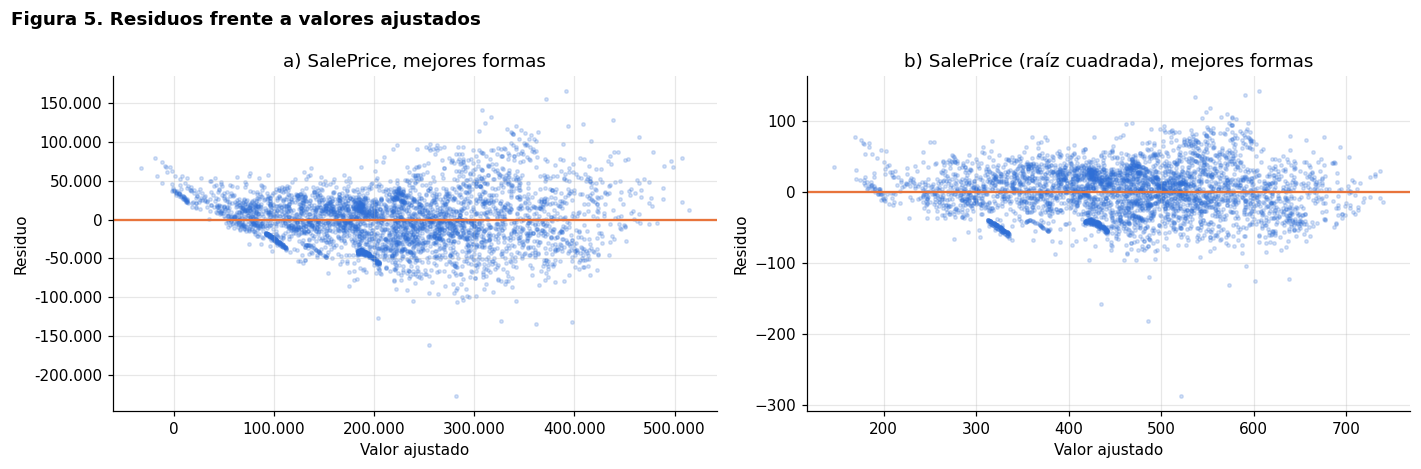

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.3))
escalas_figura = ["sin transformar", escala_elegida]
for ax, letra, escala in zip(ejes, "ab", escalas_figura):
    fila = mejores_escala_pd[mejores_escala_pd["escala_SalePrice"] == escala].iloc[0]
    aj = sm.OLS(escalas_y[escala][0](y_venta), X_formas(train, fila[numericos].to_dict())).fit()
    ax.scatter(aj.fittedvalues, aj.resid, s=5, alpha=0.2, color=AZUL)
    ax.axhline(0, color=NARANJA, lw=1.5)
    nombre_y = "SalePrice" if escala == "sin transformar" else f"SalePrice ({escala})"
    ax.set(title=f"{letra}) {nombre_y}, mejores formas", xlabel="Valor ajustado", ylabel="Residuo")
    if escala == "sin transformar":
        ax.xaxis.set_major_formatter(miles)
        ax.yaxis.set_major_formatter(miles)
fig.suptitle("Figura 5. Residuos frente a valores ajustados", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

### 4.7 Modelo final

**Lectura de 4.3 a 4.6**

- **Mínimos cuadrados, una variable a la vez (4.3):** cada variable mejora con la forma que sugieren las gráficas: `Size_sqf` cuadrática (el BIC baja 395), `YrSold` cuadrática (199), `MonthSold` inversa (207) y `Floor` cuadrática (21). `N_FacilitiesInApt` queda mejor lineal. La logarítmica empeora `Size_sqf` (+112): curva más de lo que muestran los datos.
- **Subset regression (4.4):** la mejor estructura de los 4.096 modelos usa **`SalePrice` en raíz cuadrada**, `Size_sqf` y `YrSold` cuadráticas, `MonthSold` inversa y `Floor` y `N_FacilitiesInApt` lineales. En esa escala basta la forma lineal para `Floor`. Frente a dejar `SalePrice` sin transformar con sus mejores formas, la raíz cuadrada baja el BIC en 1.211 puntos y el RMSE de 35.228 a 33.822 pesos, y elimina las 14 predicciones negativas. La escala logarítmica también mejora el BIC, pero su error en pesos es mayor (39.100), y la inversa no sirve (sus predicciones se vuelven negativas o enormes).
- **Mínimos cuadrados no lineales (4.5):** los exponentes estimados confirman las formas: `Floor` (γ = 1,05) y `N_FacilitiesInApt` (γ = 1,37, con un intervalo que incluye 1) son lineales, `MonthSold` (γ = −1,85) tiene una curva incluso más pronunciada que la inversa y `Size_sqf` (γ = 0,25) es cóncava. Aun así, el modelo no lineal tiene un BIC 303 puntos mayor que el de mínimos cuadrados con las formas elegidas: la cuadrática representa mejor a `Size_sqf` que una potencia, porque permite que la curva se aplane del todo. Por eso se elige el modelo de mínimos cuadrados.
- **Residuos (4.6):** con `SalePrice` sin transformar la dispersión de los residuos crece mucho con el valor ajustado (forma de embudo). Con la raíz cuadrada es más pareja, aunque la prueba de Breusch-Pagan sigue detectando heterocedasticidad (p < 0,001). Por eso el modelo final usa errores estándar robustos (HC3).

**Departamento retirado del modelo final**

Antes de ajustar el modelo final se retira el departamento **id 3798**. Se vendió en 54.867, cuando departamentos comparables (mismo tamaño, estación y tipo de pasillo, vendidos entre 2013 y 2015) se vendieron entre 224.690 y 384.070, así que probablemente es un error de registro o una venta fuera de mercado. Además, por sí solo explicaba la mayor parte de la falta de normalidad de los residuos (sección 6.5). El modelo final y la verificación de supuestos usan los **4.123 departamentos restantes**. La selección de variables y de formas (secciones 1 a 4.6) se hizo con todos los datos; un solo departamento no cambia esa estructura.

**Ecuación del modelo final**

√SalePrice = β₀ + β₁·Size_sqf + β₂·(Size_sqf − 955,9)² + β₃·YrSold + β₄·(YrSold − 2.012,7)² + β₅·(1/MonthSold) + β₆·Floor + β₇·N_FacilitiesInApt + efectos de HallwayType + efectos de SubwayStation

Tiene 17 parámetros (las 9 indicadoras de las dos categóricas incluidas). Para obtener el precio se eleva al cuadrado la predicción.

In [20]:
# Se retira el departamento id 3798 (justificación en la sección 6.5): se vendió en 54.867, cuando departamentos
# comparables se vendieron entre 224.690 y 384.070, y por sí solo explica la mayor parte de la falta de normalidad
# de los residuos. Desde aquí, el modelo final y la verificación de supuestos usan los datos sin ese departamento.
# Se guardan los datos completos para comparar en 6.5.
train_completo, X_elegida_completa, y_venta_completo = train, X_elegida, y_venta
id_retirado = 3798
retirar = train["id"] == id_retirado
assert retirar.sum() == 1, "el id a retirar debe existir una sola vez"
mostrar(train.loc[retirar, ["id", respuesta] + numericos + list(categoricos)].assign(id=lambda t: t["id"].astype(str)),
        f"Departamento retirado del modelo final (id {id_retirado})", decimales=0)

train = train.loc[~retirar]
y_venta = train[respuesta].astype(float)
y_elegida = escalas_y[escala_elegida][0](y_venta)
X_elegida = X_formas(train, formas_elegidas)
n_obs = len(train)
display(HTML(f"<b>Observaciones para el modelo final:</b> {num_es(n_obs, ',d') if 'num_es' in globals() else n_obs}"))

id,SalePrice,Size_sqf,YrSold,MonthSold,Floor,N_FacilitiesInApt,HallwayType,SubwayStation
3798,54.867,910,2.014,10,3,9,terraced,Myung-duk


In [21]:
# Modelo final con errores estándar robustos a heterocedasticidad (HC3): la prueba de Breusch-Pagan (4.4)
# indica que la varianza de los residuos no es constante.
modelo_final = sm.OLS(y_elegida, X_elegida).fit(cov_type="HC3")
display(modelo_final.summary())
mostrar(pd.DataFrame([{"escala_SalePrice": escala_elegida, "parametros": int(modelo_final.df_model + 1),
                       "R2_escala_del_modelo": modelo_final.rsquared, **medidas_escala(modelo_final, escala_elegida)}]),
        "Resumen del modelo final (AIC, BIC, RMSE y R² en la escala original de SalePrice)", decimales=4)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              SalePrice   R-squared:                       0.913
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     3820.
Date:                Fri, 13 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:52:51   Log-Likelihood:                -20425.
No. Observations:                4123   AIC:                         4.088e+04
Df Residuals:                    4106   BIC:                         4.099e+04
Df Model:                          16                                         
Covariance Type:                  HC3                                         
==================================================================================================
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                          -3.091e+04    388.945    -79.465      0.000   -3.17e+04   -3.01e+04
Size_sqf                           0.2107      0.002     86.625      0.000       0.206       0.215
(Size_sqf - media)²            -9.928e-05   3.26e-06    -30.435      0.000      -0.000   -9.29e-05
YrSold                            15.4503      0.194     79.778      0.000      15.071      15.830
(YrSold - media)²                  1.0082      0.070     14.332      0.000       0.870       1.146
1/MonthSold                      -44.4769      2.516    -17.676      0.000     -49.409     -39.545
Floor                              1.2431      0.077     16.054      0.000       1.091       1.395
N_FacilitiesInApt                 11.9781      0.329     36.381      0.000      11.333      12.623
HallwayType_mixed                -41.2959      2.126    -19.423      0.000     -45.463     -37.129
HallwayType_corridor             -43.5773      2.511    -17.356      0.000     -48.498     -38.656
SubwayStation_Myung-duk           12.8555      1.903      6.755      0.000       9.125      16.586
SubwayStation_Bangoge             15.9320      2.635      6.045      0.000      10.767      21.097
SubwayStation_Banwoldang          57.0975      2.560     22.301      0.000      52.079      62.116
SubwayStation_Sin-nam             13.5790      1.668      8.143      0.000      10.311      16.847
SubwayStation_Chil-sung-market   -13.8519      3.140     -4.411      0.000     -20.006      -7.698
SubwayStation_Daegu                4.4536      4.540      0.981      0.327      -4.444      13.352
SubwayStation_no_subway_nearby    26.1517      2.165     12.079      0.000      21.908      30.395
==============================================================================
Omnibus:                       12.078   Durbin-Watson:                   1.104
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               15.217
Skew:                           0.008   Prob(JB):                     0.000496
Kurtosis:                       3.297   Cond. No.                     2.12e+08
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 2.12e+08. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

escala_SalePrice,parametros,R2_escala_del_modelo,AIC,BIC,RMSE_pesos,R2_pesos,predicciones_negativas
raíz cuadrada,17,"0,9126","96.797,5024","96.905,0161","33.655,2759","0,8998",0


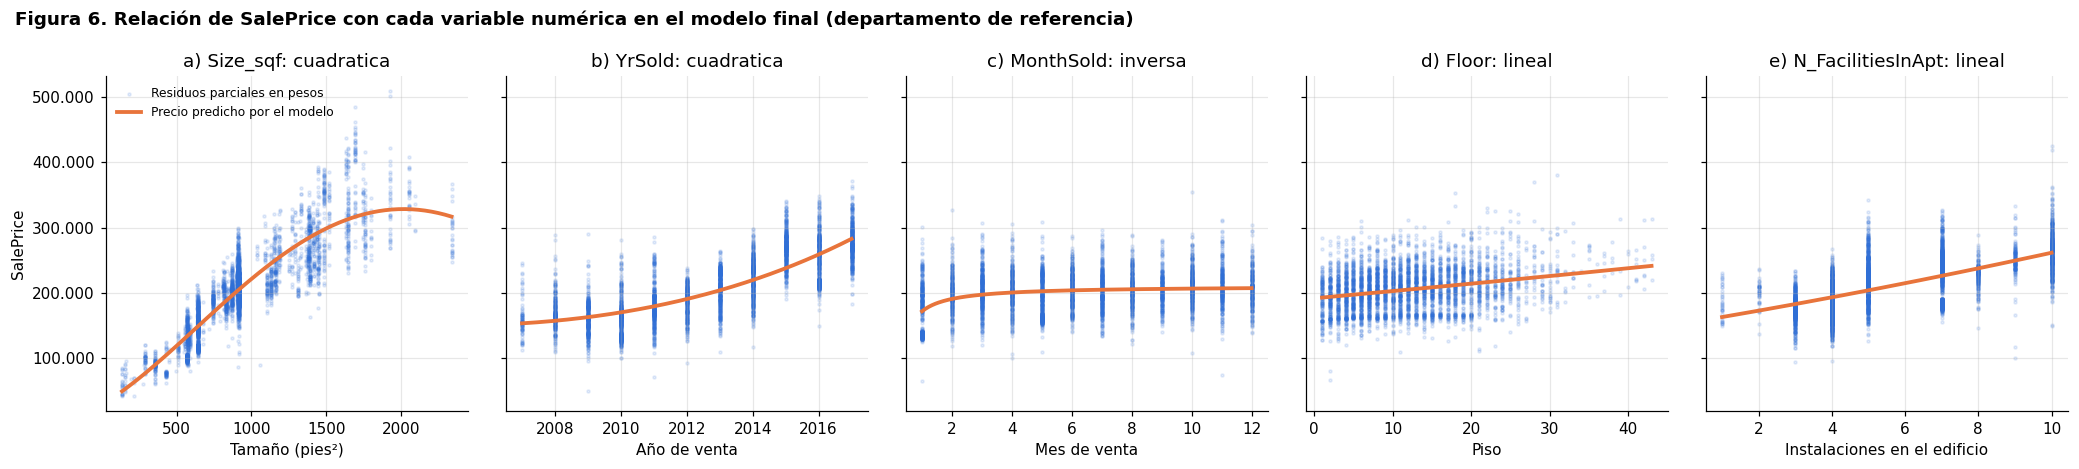

variable,categoria,SalePrice_predicho
HallwayType,terraced,203.855
HallwayType,mixed,168.270
HallwayType,corridor,166.404
SubwayStation,Kyungbuk_uni_hospital,203.855
SubwayStation,Myung-duk,215.629
SubwayStation,Bangoge,218.496
SubwayStation,Banwoldang,258.675
SubwayStation,Sin-nam,216.302
SubwayStation,Chil-sung-market,191.539
SubwayStation,Daegu,207.897


In [22]:
# Figura 6: precio predicho para un departamento de referencia al variar cada variable numérica.
# Referencia: las demás numéricas en su mediana; HallwayType = terraced y SubwayStation = Kyungbuk_uni_hospital
# (las categorías más frecuentes). Los puntos son los residuos parciales llevados a pesos: el precio que tendría
# cada departamento con sus residuos si el resto de sus características fueran las de referencia.
referencia = {c: float(train[c].median()) for c in numericos}
referencia.update({c: niveles[0] for c, niveles in categoricos.items()})
_, inversa_elegida, _ = escalas_y[escala_elegida]


def predecir_referencia(c, valores):
    dd = pd.DataFrame({k: [v] * len(valores) for k, v in referencia.items()})
    dd[c] = np.asarray(valores, dtype=float)
    X = X_formas(dd, formas_elegidas).reindex(columns=X_elegida.columns, fill_value=0.0)
    X["const"] = 1.0
    return X @ modelo_final.params.values


fig, ejes = plt.subplots(1, 5, figsize=(19, 4.3), sharey=True)
for ax, letra, c in zip(ejes, "abcde", numericos):
    x = train[c].astype(float)
    puntos = inversa_elegida(predecir_referencia(c, x.values).values + modelo_final.resid.values)
    ax.scatter(x, puntos, s=4, alpha=0.12, color=AZUL, label="Residuos parciales en pesos")
    rejilla = np.linspace(x.min(), x.max(), 200)
    ax.plot(rejilla, inversa_elegida(predecir_referencia(c, rejilla).values), color=NARANJA, lw=2.5,
            label="Precio predicho por el modelo")
    ax.set(title=f"{letra}) {c}: {formas_elegidas[c]}", xlabel=etiquetas_num[c])
    ax.yaxis.set_major_formatter(miles)
ejes[0].set_ylabel("SalePrice")
ejes[0].legend(frameon=False, loc="upper left", fontsize=8)
fig.suptitle("Figura 6. Relación de SalePrice con cada variable numérica en el modelo final "
             "(departamento de referencia)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

efectos_cat = pd.DataFrame([{
    "variable": c, "categoria": v,
    "SalePrice_predicho": float(inversa_elegida(
        (X_formas(pd.DataFrame({**{k: [w] for k, w in referencia.items()}, c: [v]}), formas_elegidas)
         .reindex(columns=X_elegida.columns, fill_value=0.0).assign(const=1.0) @ modelo_final.params.values).iloc[0])),
} for c, niveles in categoricos.items() for v in niveles])
mostrar(efectos_cat, "Precio predicho del departamento de referencia según cada categoría", decimales=0)

**Explicación del modelo con base en la relación de cada variable con el precio**

La Figura 6 muestra, para un departamento de referencia (910 pies², vendido en junio de 2013, piso 11, con 5 instalaciones, *terraced* y cerca de *Kyungbuk_uni_hospital*), cómo cambia el precio predicho al mover una sola variable. Para ese departamento el modelo predice 203.855.

- **`Size_sqf` (cuadrática, cóncava):** es la variable que más pesa. El precio sube de 78.700 con 300 pies² a 201.900 con 900 y a 298.800 con 1.500, pero cada pie² adicional suma menos: la curva llega a su máximo cerca de 2.017 pies² (328.500) y baja un poco después (316.900 con 2.337). Esa caída final se apoya en solo 54 departamentos, así que no debe leerse como que los departamentos más grandes valen menos.
- **`YrSold` (cuadrática, convexa):** el precio crece cada vez más rápido: 153.300 en 2007, 190.500 en 2012 y 282.900 en 2017. El mínimo de la parábola está en 2005, antes de los datos, así que entre 2007 y 2017 el precio predicho siempre sube.
- **`MonthSold` (inversa):** la venta en enero tiene un precio claramente menor (171.800); desde febrero el efecto se desvanece rápido (190.700 en febrero, 203.900 en junio y 207.200 en diciembre). Es la curva muy pronunciada en un extremo que describe la transformación inversa.
- **`Floor` (lineal):** cada piso adicional sube el precio de forma pareja: 192.800 en el piso 1 y 237.700 en el 40.
- **`N_FacilitiesInApt` (lineal):** pasar de 1 a 10 instalaciones sube el precio de 162.900 a 261.500.
- **`HallwayType`:** con todo lo demás igual, un departamento *mixed* (168.300) o *corridor* (166.400) vale entre 35.600 y 37.500 menos que uno *terraced*.
- **`SubwayStation`:** la estación más cara es *Banwoldang* (258.700) y la más barata *Chil-sung-market* (191.500). *Daegu* no se diferencia de la referencia (p = 0,33).

Como el precio entra con raíz cuadrada, los efectos de las variables se suman en la escala de la raíz y no en pesos: el aumento en pesos que produce una variable es mayor cuanto más caro es el departamento. Esto refleja lo que muestra la Figura 5: los departamentos caros varían más en precio que los baratos.

El modelo explica el 90,0 % de la variabilidad del precio medida en pesos (91,3 % en la escala de la raíz), con un error típico de 33.655 pesos. Como referencia, el modelo con las 7 variables lineales, ajustado con todos los datos, explicaba el 86,5 % con un error de 39.027. La nota de *statsmodels* sobre un número de condición alto se debe a la escala de las variables (años cerca de 2.000 y tamaños al cuadrado del orden de un millón), no a multicolinealidad: con las variables estandarizadas el número de condición es 4,69 (sección 2).

### 4.8 Datos atípicos y varianza de los residuos

Para ver si la varianza no constante de los residuos (4.6) se debe a valores extremos, se descartan los datos atípicos de los términos elegidos con la regla de Tukey: es atípico todo valor menor que Q1 − 1,5·RIC o mayor que Q3 + 1,5·RIC, donde RIC = Q3 − Q1 es el rango intercuartílico.

- La regla se aplica a las 5 variables numéricas. `HallwayType` y `SubwayStation` son categóricas, así que no tienen cuartiles ni datos atípicos en este sentido.
- Se descarta toda fila que sea atípica en al menos una variable.
- Después se vuelven a ajustar los dos modelos de la Figura 5, con la misma estructura, sin esas filas: `SalePrice` sin transformar y en raíz cuadrada.

Además de la prueba de Breusch-Pagan, se calcula la **razón de dispersión**: la desviación estándar de los residuos en el 20 % de valores ajustados más altos dividida por la del 20 % más bajo. Si la varianza fuera constante, esta razón estaría cerca de 1.

In [23]:
# Regla de Tukey: es atípico todo valor menor que Q1 − 1,5·RIC o mayor que Q3 + 1,5·RIC (RIC = Q3 − Q1).
# Se aplica a las 5 variables numéricas elegidas; HallwayType y SubwayStation son categóricas y no tienen RIC.
fuera_de_rango = pd.Series(False, index=train.index)
filas_atipicos = []
for c in numericos:
    q1, q3 = train[c].quantile([0.25, 0.75])
    ric = q3 - q1
    limite_inf, limite_sup = q1 - 1.5 * ric, q3 + 1.5 * ric
    atipico = (train[c] < limite_inf) | (train[c] > limite_sup)
    fuera_de_rango |= atipico
    filas_atipicos.append({"variable": c, "Q1": q1, "Q3": q3, "RIC": ric, "limite_inferior": limite_inf,
                           "limite_superior": limite_sup, "atipicos_abajo": int((train[c] < limite_inf).sum()),
                           "atipicos_arriba": int((train[c] > limite_sup).sum()), "atipicos": int(atipico.sum())})
atipicos_pd = pd.DataFrame(filas_atipicos)
mostrar(atipicos_pd, "Datos atípicos de cada variable numérica (regla de 1,5 · RIC)", decimales=1)

train_sin_atipicos = train[~fuera_de_rango]
mostrar(pd.DataFrame([{"filas_originales": len(train), "filas_descartadas": int(fuera_de_rango.sum()),
                       "porcentaje_descartado": fuera_de_rango.mean() * 100, "filas_que_quedan": len(train_sin_atipicos)}]),
        "Filas descartadas (atípicas en al menos una variable)", decimales=2)

variable,Q1,Q3,RIC,limite_inferior,limite_superior,atipicos_abajo,atipicos_arriba,atipicos
Size_sqf,"644,0","1.149,0","505,0","-113,5","1.906,5",0,88,88
YrSold,"2.010,0","2.015,0","5,0","2.002,5","2.022,5",0,0,0
MonthSold,"3,0","9,0","6,0","-6,0","18,0",0,0,0
Floor,"6,0","17,0","11,0","-10,5","33,5",0,42,42
N_FacilitiesInApt,"4,0","7,0","3,0","-0,5","11,5",0,0,0


filas_originales,filas_descartadas,porcentaje_descartado,filas_que_quedan
4.123,130,"3,15",3.993


escala_SalePrice,datos,n,R2_escala_del_modelo,RMSE_pesos,Breusch_Pagan,p_valor_BP,razon_desv_residuos_alto_bajo
sin transformar,todos los datos,4.123,"0,8913","35.053,4246","835,3500","0,0000","2,0340"
sin transformar,sin atípicos,3.993,"0,8891","33.996,0869","826,4280","0,0000","2,0546"
raíz cuadrada,todos los datos,4.123,"0,9126","33.655,2759","573,5568","0,0000","1,3376"
raíz cuadrada,sin atípicos,3.993,"0,9089","33.189,1745","649,2268","0,0000","1,3919"


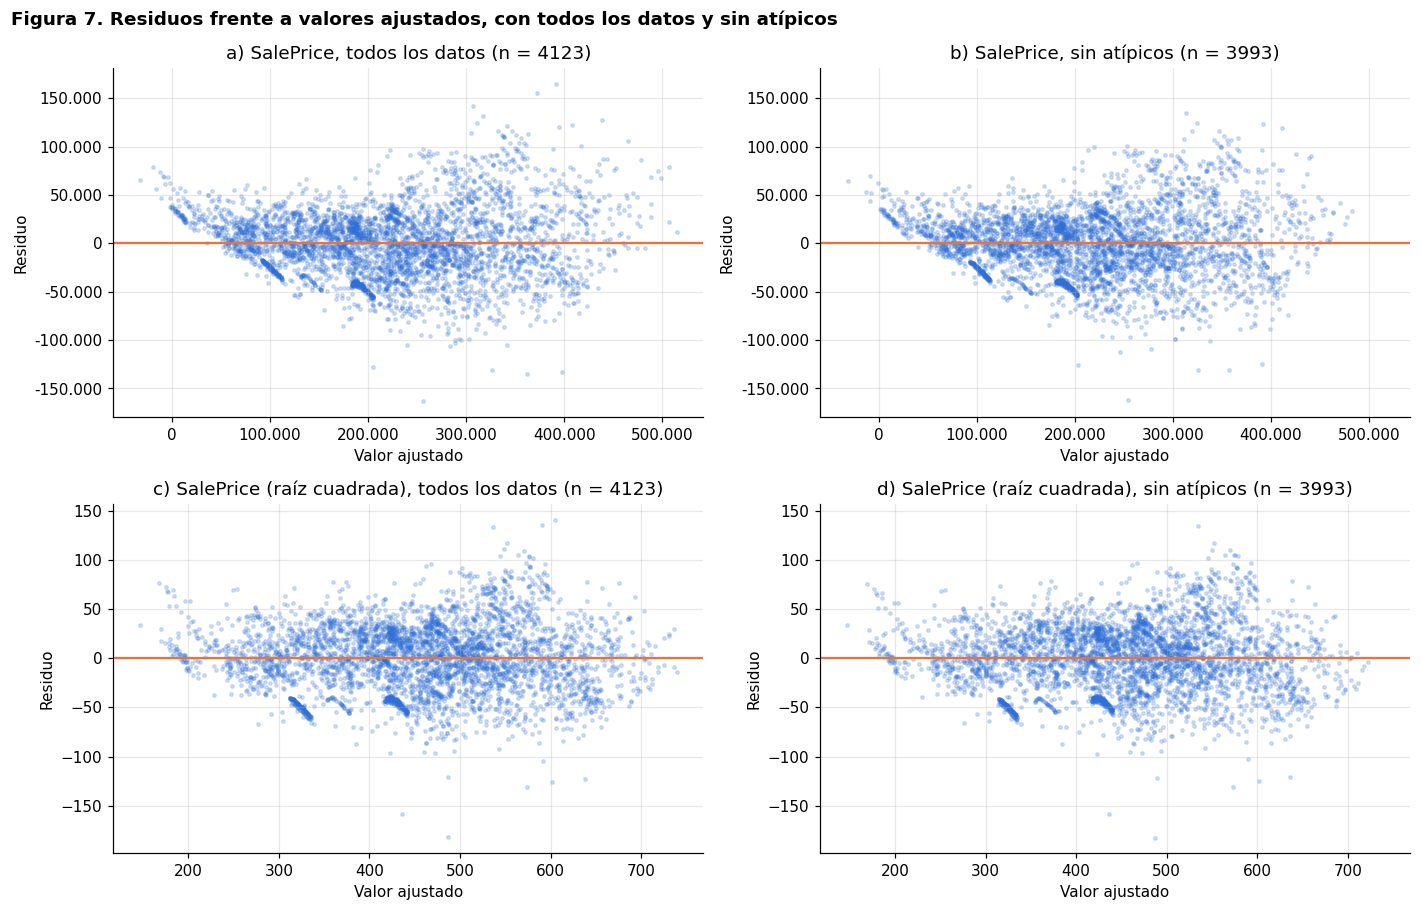

parametro,coef_todos,coef_sin_atipicos,cambio_pct
const,"-30.907,6950","-30.932,1033","0,0790"
Size_sqf,"0,2107","0,2094","-0,6036"
(Size_sqf - media)²,"-0,0001","-0,0001","-3,6373"
YrSold,"15,4503","15,4637","0,0868"
(YrSold - media)²,"1,0082","0,9344","-7,3161"
1/MonthSold,"-44,4769","-45,4716","2,2366"
Floor,"1,2431","1,1382","-8,4433"
N_FacilitiesInApt,"11,9781","11,9607","-0,1458"
HallwayType_mixed,"-41,2959","-40,6000","-1,6853"
HallwayType_corridor,"-43,5773","-44,9623","3,1781"


In [24]:
# Se vuelven a ajustar los dos modelos de la Figura 5 (misma estructura) sin las filas atípicas.
def ajustar_estructura(dd, escala):
    formas = mejores_escala_pd.loc[mejores_escala_pd["escala_SalePrice"] == escala, numericos].iloc[0].to_dict()
    X = X_formas(dd, formas)
    return sm.OLS(escalas_y[escala][0](dd[respuesta].astype(float)), X).fit(), X


def razon_dispersion(ajuste):
    """Desviación estándar de los residuos en el 20 % de valores ajustados más altos / en el 20 % más bajo.
    Si la varianza fuera constante, sería cercana a 1."""
    quintil = pd.qcut(ajuste.fittedvalues, 5, labels=False)
    return ajuste.resid[quintil == 4].std() / ajuste.resid[quintil == 0].std()


def rmse_pesos(ajuste, escala, y_real):
    inversa = escalas_y[escala][1]
    if escala == "sin transformar":
        pred = ajuste.fittedvalues.values
    else:
        pred = inversa(ajuste.fittedvalues.values[:, None] + ajuste.resid.values[None, :]).mean(axis=1)
    return float(np.sqrt(np.mean((y_real.values - pred) ** 2)))


ajustes_atipicos, filas_residuos = {}, []
for escala in ["sin transformar", escala_elegida]:
    for datos_nombre, dd in [("todos los datos", train), ("sin atípicos", train_sin_atipicos)]:
        aj, X = ajustar_estructura(dd, escala)
        ajustes_atipicos[(escala, datos_nombre)] = aj
        estad_bp, p_bp, _, _ = het_breuschpagan(aj.resid, X)
        filas_residuos.append({"escala_SalePrice": escala, "datos": datos_nombre, "n": int(aj.nobs),
                               "R2_escala_del_modelo": aj.rsquared, "RMSE_pesos": rmse_pesos(aj, escala, dd[respuesta]),
                               "Breusch_Pagan": estad_bp, "p_valor_BP": p_bp,
                               "razon_desv_residuos_alto_bajo": razon_dispersion(aj)})
residuos_atipicos_pd = pd.DataFrame(filas_residuos)
mostrar(residuos_atipicos_pd, "Residuos con todos los datos y sin atípicos", decimales=4)

fig, ejes = plt.subplots(2, 2, figsize=(13, 8.4))
for fila, escala in enumerate(["sin transformar", escala_elegida]):
    for col, datos_nombre in enumerate(["todos los datos", "sin atípicos"]):
        ax = ejes[fila, col]
        aj = ajustes_atipicos[(escala, datos_nombre)]
        ax.scatter(aj.fittedvalues, aj.resid, s=5, alpha=0.2, color=AZUL)
        ax.axhline(0, color=NARANJA, lw=1.5)
        nombre_y = "SalePrice" if escala == "sin transformar" else f"SalePrice ({escala})"
        ax.set(title=f"{'abcd'[2 * fila + col]}) {nombre_y}, {datos_nombre} (n = {int(aj.nobs)})",
               xlabel="Valor ajustado", ylabel="Residuo")
        if escala == "sin transformar":
            ax.xaxis.set_major_formatter(miles)
            ax.yaxis.set_major_formatter(miles)
    ejes[fila, 1].sharey(ejes[fila, 0])
    ejes[fila, 1].sharex(ejes[fila, 0])
fig.suptitle("Figura 7. Residuos frente a valores ajustados, con todos los datos y sin atípicos",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

coeficientes_comparados = pd.DataFrame({
    "coef_todos": ajustes_atipicos[(escala_elegida, "todos los datos")].params,
    "coef_sin_atipicos": ajustes_atipicos[(escala_elegida, "sin atípicos")].params,
})
coeficientes_comparados["cambio_pct"] = (coeficientes_comparados["coef_sin_atipicos"] / coeficientes_comparados["coef_todos"] - 1) * 100
mostrar(coeficientes_comparados.reset_index().rename(columns={"index": "parametro"}),
        f"Coeficientes del modelo final (SalePrice en {escala_elegida}) con todos los datos y sin atípicos", decimales=4)

**Resultados**

- **Solo dos variables tienen atípicos, y todos por arriba.** `Size_sqf` tiene 88 departamentos de más de 1.906,5 pies², y `Floor` tiene 42 por encima del piso 33,5. `YrSold`, `MonthSold` y `N_FacilitiesInApt` no tienen ninguno, porque sus valores caen dentro de los límites. En total se descartan 130 de los 4.123 departamentos del modelo final (3,2 %) y quedan 3.993.
- **Descartarlos no reduce la heterocedasticidad.** La razón de dispersión casi no cambia: con `SalePrice` sin transformar pasa de 2,03 a 2,05, y con la raíz cuadrada de 1,34 a 1,39. La prueba de Breusch-Pagan sigue indicando varianza no constante en los dos casos (p < 0,001). En la Figura 7 el embudo de los paneles a) y b) es el mismo con o sin atípicos.
- **El modelo casi no cambia.** Sin los atípicos, el R² en la escala de la raíz pasa de 0,913 a 0,909 y el RMSE de 33.655 a 33.189 pesos; la leve baja del error se debe a que se quitaron los departamentos más grandes, que son los más caros. Los coeficientes de las variables principales cambian menos del 1 % (`Size_sqf`, `YrSold`, `N_FacilitiesInApt`); los que más cambian son los de `Floor` (−8 %), el término cuadrático de `YrSold` (−7 %) y la indicadora de *Daegu*, que ya no era significativa.
- **Lo que más ayuda contra la varianza no constante es la raíz cuadrada de `SalePrice`, no quitar atípicos.** Con la raíz, la razón de dispersión baja de 2,03 a 1,34, con o sin atípicos.

**Conclusión:** la varianza no constante no la producen los valores extremos de las variables explicativas: aparece en todo el rango de valores ajustados, porque los departamentos caros varían más en precio que los baratos. Descartar los atípicos además tiene un costo: el modelo dejaría de cubrir los departamentos de más de 1.906 pies² y los pisos por encima del 33. Por eso **el modelo final de 4.7 no descarta estos atípicos** y usa errores estándar robustos (HC3), que siguen siendo válidos aunque la varianza no sea constante.

## 5. Estimación de los parámetros del modelo

Se presentan los parámetros del modelo final de la sección 4.7:

√SalePrice = β₀ + β₁·Size_sqf + β₂·(Size_sqf − media)² + β₃·YrSold + β₄·(YrSold − media)² + β₅·(1/MonthSold) + β₆·Floor + β₇·N_FacilitiesInApt + efectos de HallwayType + efectos de SubwayStation + ε

Los parámetros se estiman por mínimos cuadrados ordinarios con los 4.123 departamentos de Train (sin el id 3798; ver 4.7 y 6.5). Todos los coeficientes están en la **escala de √SalePrice**: indican cuánto cambia la raíz cuadrada del precio, no el precio en pesos (ver 4.7). Como la varianza de los residuos no es constante (4.6, 4.8 y 6.2), las pruebas y los intervalos usan **errores estándar robustos HC3**.

### 5.1 Parámetros del modelo

**Qué significa cada columna de la tabla**

| Columna | Qué es |
|---|---|
| `termino` | Columna de la matriz de diseño a la que corresponde el parámetro. Una variable puede tener varias: una cuadrática tiene el término lineal y el término al cuadrado, y una categórica una indicadora por cada categoría distinta de la de referencia. |
| `variable` | Variable original (de las 7 elegidas) a la que pertenece el término. |
| `forma` | Transformación con la que entra la variable: lineal, cuadrática (término lineal o al cuadrado), inversa o indicadora de una categoría. Las indicadoras se comparan con la categoría de referencia (*terraced* y *Kyungbuk_uni_hospital*). |
| `coeficiente` | Estimación del parámetro β: cambio en √SalePrice cuando el término aumenta en una unidad y los demás términos quedan fijos. En una indicadora, es la diferencia en √SalePrice frente a la categoría de referencia. |
| `error_estandar_HC3` | Error estándar del coeficiente, robusto a varianza no constante (HC3). Mide cuánto variaría el coeficiente de una muestra a otra. Es el que se usa en las pruebas y los intervalos. |
| `error_estandar_clasico` | Error estándar de mínimos cuadrados, que supone varianza constante. Se incluye para comparar: si difiere mucho del HC3, la varianza no constante sí afecta la precisión de ese coeficiente. |
| `estadistico_t` | Estadístico t de la prueba de hipótesis individual H₀: β = 0 frente a H₁: β ≠ 0: coeficiente dividido por su error estándar HC3. Bajo H₀ sigue una distribución t de Student con n − p = 4.123 − 17 = 4.106 grados de libertad. Cuanto mayor es su valor absoluto, más evidencia hay de que el término aporta; con α = 0,05 se rechaza H₀ si el valor absoluto de t es mayor que 1,9605. |
| `p_valor` | Probabilidad, según la distribución t con 4.106 grados de libertad, de obtener un estadístico t tan extremo si β fuera 0. Si es menor que 0,05, se rechaza H₀: el término aporta a explicar el precio. |
| `IC95_inferior`, `IC95_superior` | Intervalo de confianza del 95 % para β: coeficiente ± t₀,₉₇₅;₄.₁₀₆ × error estándar HC3, con t₀,₉₇₅;₄.₁₀₆ = 1,9605. Si el intervalo no incluye el 0, el término es significativo al 5 %. |
| `significativo_5pct` | «sí» si p < 0,05. |
| `coeficiente_estandarizado` | Coeficiente multiplicado por la desviación estándar del término y dividido por la de √SalePrice: cambio en √SalePrice, medido en desviaciones estándar, cuando el término aumenta una desviación estándar. Sirve para comparar la importancia relativa de términos medidos en unidades distintas (pies², años, pisos). |

In [25]:
# Variable original y forma de cada columna del modelo final
def describir_columna(col):
    if col == "const":
        return "Intercepto", "constante"
    for c in numericos:
        if col == c:
            return c, "lineal" if formas_elegidas[c] == "lineal" else "cuadrática: término lineal"
        if col == f"({c} - media)²":
            return c, "cuadrática: término al cuadrado (centrado)"
        if col == f"1/{c}":
            return c, "inversa"
        if col == f"log({c})":
            return c, "logarítmica"
    for c, niveles in categoricos.items():
        if col.startswith(c + "_"):
            return c, f"indicadora de «{col[len(c) + 1:]}» (referencia: «{niveles[0]}»)"
    return col, ""


ajuste_clasico = sm.OLS(y_elegida, X_elegida).fit()  # mismo ajuste, con errores estándar clásicos (para comparar)
# Pruebas t: estadístico = coeficiente / error estándar HC3, con n − p grados de libertad
from scipy import stats as st
gl_t = modelo_final.df_resid
t_critico = st.t.ppf(0.975, gl_t)
estadistico_t = modelo_final.params.values / modelo_final.bse.values
parametros_pd = pd.DataFrame({
    "termino": X_elegida.columns,
    "variable": [describir_columna(c)[0] for c in X_elegida.columns],
    "forma": [describir_columna(c)[1] for c in X_elegida.columns],
    "coeficiente": modelo_final.params.values,
    "error_estandar_HC3": modelo_final.bse.values,
    "error_estandar_clasico": ajuste_clasico.bse.values,
    "estadistico_t": estadistico_t,
    "p_valor": 2 * st.t.sf(np.abs(estadistico_t), gl_t),
    "IC95_inferior": modelo_final.params.values - t_critico * modelo_final.bse.values,
    "IC95_superior": modelo_final.params.values + t_critico * modelo_final.bse.values,
})
parametros_pd["significativo_5pct"] = np.where(parametros_pd["p_valor"] < 0.05, "sí", "no")
# Coeficiente estandarizado: cambio en √SalePrice, en desviaciones estándar, cuando la columna aumenta una desviación estándar
desv_columnas = X_elegida.std()
parametros_pd["coeficiente_estandarizado"] = np.where(
    parametros_pd["termino"] == "const", np.nan,
    parametros_pd["coeficiente"].values * desv_columnas.values / y_elegida.std())

display(HTML("<b>Estimación de los parámetros del modelo final</b> (variable dependiente: √SalePrice; "
             f"pruebas t con {gl_t:.0f} grados de libertad, valor crítico t = {coma(t_critico, 4)})"))
def num_es(v, fmt):
    """Número con coma decimal y punto de miles."""
    if pd.isna(v):
        return "—"
    texto = format(v, fmt)
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")


def p_es(p):
    return "< 0,0001" if p < 1e-4 else num_es(p, ".4f")


display(parametros_pd.style.hide(axis="index").format({
    "coeficiente": lambda v: num_es(v, ",.6g"), "error_estandar_HC3": lambda v: num_es(v, ",.4g"),
    "error_estandar_clasico": lambda v: num_es(v, ",.4g"), "estadistico_t": lambda v: num_es(v, ",.2f"),
    "p_valor": p_es, "IC95_inferior": lambda v: num_es(v, ",.6g"), "IC95_superior": lambda v: num_es(v, ",.6g"),
    "coeficiente_estandarizado": lambda v: num_es(v, ".3f")}))

termino,variable,forma,coeficiente,error_estandar_HC3,error_estandar_clasico,estadistico_t,p_valor,IC95_inferior,IC95_superior,significativo_5pct,coeficiente_estandarizado
const,Intercepto,constante,"-30.907,7","388,9","407,5","-79,47","< 0,0001","-31.670,2","-30.145,2",sí,—
Size_sqf,Size_sqf,cuadrática: término lineal,"0,210678","0,002432","0,002346","86,63","< 0,0001","0,20591","0,215446",sí,"0,685"
(Size_sqf - media)²,Size_sqf,cuadrática: término al cuadrado (centrado),"-9,92832e-05","3,262e-06","3,093e-06","-30,44","< 0,0001","-0,000105679","-9,28877e-05",sí,"-0,205"
YrSold,YrSold,cuadrática: término lineal,"15,4503","0,1937","0,2025","79,78","< 0,0001","15,0706","15,83",sí,"0,387"
(YrSold - media)²,YrSold,cuadrática: término al cuadrado (centrado),"1,00816","0,07034","0,07351","14,33","< 0,0001","0,870248","1,14606",sí,"0,066"
1/MonthSold,MonthSold,inversa,"-44,4769","2,516","2,106","-17,68","< 0,0001","-49,4101","-39,5436",sí,"-0,103"
Floor,Floor,lineal,"1,24312","0,07743","0,0749","16,05","< 0,0001","1,09131","1,39493",sí,"0,082"
N_FacilitiesInApt,N_FacilitiesInApt,lineal,"11,9781","0,3292","0,3387","36,38","< 0,0001","11,3326","12,6236",sí,"0,240"
HallwayType_mixed,HallwayType,indicadora de «mixed» (referencia: «terraced»),"-41,2959","2,126","2,581","-19,42","< 0,0001","-45,4642","-37,1276",sí,"-0,161"
HallwayType_corridor,HallwayType,indicadora de «corridor» (referencia: «terraced»),"-43,5773","2,511","2,839","-17,36","< 0,0001","-48,4998","-38,6549",sí,"-0,116"


**Lectura de la tabla**

- **Pruebas individuales:** 16 de los 17 parámetros son significativos (p < 0,0001). La única excepción es la indicadora de *Daegu* (p = 0,33): su intervalo, de −4,45 a 13,35, incluye el 0, así que su precio no se distingue del de *Kyungbuk_uni_hospital* una vez controladas las demás variables.
- **Curvaturas:** los términos al cuadrado de `Size_sqf` (−0,0000993) y `YrSold` (1,008) son significativos, y el término inverso `1/MonthSold` también. Eso confirma que las formas elegidas en la sección 4 son necesarias: la relación de esas variables con el precio no es una recta. El signo negativo en `Size_sqf` indica que la curva se aplana; el positivo en `YrSold`, que se acelera.
- **Importancia relativa (coeficientes estandarizados):** `Size_sqf` es el término que más pesa (0,685 en su parte lineal), seguido de `YrSold` (0,387) y `N_FacilitiesInApt` (0,240). Entre las categóricas destacan *Banwoldang* (0,163) y *mixed* (−0,161). En las cuadráticas, el término lineal y el término al cuadrado actúan juntos, así que no deben leerse por separado; la prueba conjunta de 5.2 mide el peso de la variable completa.
- **Errores HC3 frente a clásicos:** en la mayoría de los términos son parecidos. Los mayores cambios son en `1/MonthSold` (2,52 frente a 2,11) y *Banwoldang* (2,56 frente a 2,02), donde el error clásico subestimaba la incertidumbre, y en *Chil-sung-market* (3,14 frente a 4,79), donde la sobreestimaba. Ninguna conclusión de significancia cambia al usar HC3.
- **Intercepto:** −30.907,7 no tiene interpretación práctica. Es el valor de √SalePrice cuando todas las columnas valen 0, incluido el año 0; solo compensa que `YrSold` vale cerca de 2.013 (15,450 × 2.013 ≈ 31.101).

### 5.2 Pruebas conjuntas y medidas globales

Cuando una variable entra con varias columnas, las pruebas individuales de 5.1 no responden si **la variable completa** aporta. Para eso se usa la **prueba conjunta de Wald** (con errores HC3), con H₀: todos los coeficientes de la variable valen 0.

| Columna | Qué es |
|---|---|
| `columnas` | Número de términos de la variable en el modelo. |
| `estadistico_F` | Estadístico de la prueba: cuanto más grande, más aporta la variable una vez controladas las demás. |
| `gl_numerador`, `gl_denominador` | Grados de libertad de la prueba F: número de restricciones (columnas) y grados de libertad de los residuos. |
| `p_valor` | Si es menor que 0,05, la variable completa es significativa. |

La tabla de medidas globales resume el ajuste del modelo:

| Medida | Qué es |
|---|---|
| R² y R² ajustado | Proporción de la variabilidad de √SalePrice que explica el modelo; el ajustado penaliza el número de parámetros. |
| Error estándar de la regresión σ̂ | Desviación estándar de los residuos, en la escala de √SalePrice. |
| Prueba F global | H₀: todos los coeficientes, salvo el intercepto, valen 0 (el modelo no explica nada). |
| Corrección de Duan | Promedio de los residuos al cuadrado. Para predecir el precio promedio en pesos se eleva al cuadrado la predicción y se le suma este valor (ver 4.7). |
| RMSE y R² en pesos | Error típico y proporción de variabilidad explicada, medidos en la escala original del precio después de deshacer la transformación con la corrección de Duan. |

In [26]:
# Prueba conjunta de cada variable: ¿todas sus columnas valen 0 a la vez? (prueba de Wald con errores HC3)
filas_conjuntas = []
for variable in numericos + list(categoricos):
    columnas = [c for c in X_elegida.columns if describir_columna(c)[0] == variable]
    R = np.zeros((len(columnas), X_elegida.shape[1]))
    for fila, c in enumerate(columnas):
        R[fila, X_elegida.columns.get_loc(c)] = 1
    prueba = modelo_final.wald_test(R, scalar=True, use_f=True)
    filas_conjuntas.append({"variable": variable, "forma": formas_elegidas.get(variable, "categórica"),
                            "columnas": len(columnas), "estadistico_F": float(prueba.statistic),
                            "gl_numerador": int(prueba.df_num), "gl_denominador": int(prueba.df_denom),
                            "p_valor": float(prueba.pvalue)})
conjuntas_pd = pd.DataFrame(filas_conjuntas).sort_values("estadistico_F", ascending=False)
display(HTML("<b>Prueba conjunta de cada variable (Wald, errores HC3)</b>"))
display(conjuntas_pd.style.hide(axis="index").format({
    "estadistico_F": lambda v: num_es(v, ",.2f"), "gl_denominador": lambda v: num_es(v, ",d"), "p_valor": p_es}))

# Medidas globales del ajuste
factor_smearing = float(np.mean(modelo_final.resid ** 2))
global_pd = pd.DataFrame([
    {"medida": "Observaciones (n)", "valor": modelo_final.nobs},
    {"medida": "Parámetros estimados (p)", "valor": modelo_final.df_model + 1},
    {"medida": "Grados de libertad de los residuos (n − p)", "valor": modelo_final.df_resid},
    {"medida": "R² (escala √SalePrice)", "valor": modelo_final.rsquared},
    {"medida": "R² ajustado (escala √SalePrice)", "valor": modelo_final.rsquared_adj},
    {"medida": "Error estándar de la regresión σ̂ (escala √SalePrice)", "valor": np.sqrt(modelo_final.mse_resid)},
    {"medida": "Prueba F global (HC3): estadístico", "valor": modelo_final.fvalue},
    {"medida": "Prueba F global (HC3): p-valor", "valor": modelo_final.f_pvalue},
    {"medida": "Corrección de Duan para predecir en pesos (promedio de residuos²)", "valor": factor_smearing},
    {"medida": "RMSE en pesos", "valor": medidas_escala(modelo_final, escala_elegida)["RMSE_pesos"]},
    {"medida": "R² en pesos", "valor": medidas_escala(modelo_final, escala_elegida)["R2_pesos"]},
])
formatos_globales = [",.0f", ",.0f", ",.0f", ".4f", ".4f", ".2f", ",.2f", "p", ",.1f", ",.0f", ".4f"]
global_pd["valor"] = [p_es(v) if f == "p" else num_es(v, f) for v, f in zip(global_pd["valor"], formatos_globales)]
mostrar(global_pd, "Medidas globales del modelo final")

variable,forma,columnas,estadistico_F,gl_numerador,gl_denominador,p_valor
Size_sqf,cuadratica,2,"4.095,39",2,4.106,"< 0,0001"
YrSold,cuadratica,2,"3.194,29",2,4.106,"< 0,0001"
N_FacilitiesInApt,lineal,1,"1.323,57",1,4.106,"< 0,0001"
MonthSold,inversa,1,"312,43",1,4.106,"< 0,0001"
Floor,lineal,1,"257,74",1,4.106,"< 0,0001"
HallwayType,categórica,2,"222,25",2,4.106,"< 0,0001"
SubwayStation,categórica,7,"101,36",7,4.106,"< 0,0001"


medida,valor
Observaciones (n),4.123
Parámetros estimados (p),17
Grados de libertad de los residuos (n − p),4.106
R² (escala √SalePrice),"0,9126"
R² ajustado (escala √SalePrice),"0,9123"
Error estándar de la regresión σ̂ (escala √SalePrice),"34,36"
Prueba F global (HC3): estadístico,"3.820,23"
Prueba F global (HC3): p-valor,"< 0,0001"
Corrección de Duan para predecir en pesos (promedio de residuos²),"1.175,8"
RMSE en pesos,33.655


**Lectura de las pruebas conjuntas y del ajuste global**

- **Las 7 variables son significativas como un todo** (p < 0,0001). Por orden de aporte: `Size_sqf` (F = 4.095,4), `YrSold` (3.194,3), `N_FacilitiesInApt` (1.323,6), `MonthSold` (312,4), `Floor` (257,7), `HallwayType` (222,3) y `SubwayStation` (101,4).
- **`SubwayStation` sí aporta,** aunque una de sus indicadoras (*Daegu*) no sea significativa: la prueba conjunta de sus 7 indicadoras tiene p < 0,0001. No conviene quitar una sola categoría; *Daegu* simplemente se parece a la estación de referencia.
- **Ajuste global:** el modelo explica el 91,3 % de la variabilidad de √SalePrice (R² ajustado 0,912) y el 90,0 % de la variabilidad del precio en pesos, con un error típico de 33.655 pesos. La prueba F global (F = 3.820, p < 0,0001) rechaza que el modelo no explique nada.
- **Para predecir en pesos:** precio promedio = (predicción de √SalePrice)² + 1.175,8.

## 6. Verificación de supuestos

Se verifican uno a uno los supuestos del modelo final (secciones 4.7 y 5): MCO con la raíz cuadrada de `SalePrice` y errores estándar HC3, estimado con 4.123 departamentos (sin el id 3798).

| Sección | Supuesto o revisión | Prueba principal |
|---|---|---|
| 6.1 | Media cero de los errores | Prueba t, medias por grupo y ANOVA |
| 6.2 | Varianza constante | Breusch-Pagan; transformación de Box-Cox como intento de corrección |
| 6.3 | Normalidad de los errores | Jarque-Bera, D'Agostino-Pearson, Kolmogorov-Smirnov, Anderson-Darling y gráfico Q-Q |
| 6.4 | Independencia de los errores | Durbin-Watson |
| 6.5 | Observaciones influyentes | Diagonal de la matriz H y distancia de Cook |
| 6.6 | Resumen | — |

### 6.1 Media cero de los errores (*zero expectation*)

**Supuesto:** E[ε | X] = 0. En promedio, el error del modelo es cero **para cualquier combinación de valores de las variables explicativas**, no solo en el total. Si se cumple, el modelo no se equivoca sistemáticamente hacia arriba ni hacia abajo en ningún grupo de departamentos. Si no se cumple, la forma del modelo no captura bien alguna relación y los coeficientes pueden estar sesgados.

**Residuos estudentizados.** Los residuos ordinarios eᵢ = yᵢ − ŷᵢ no tienen todos la misma varianza: dependen del *leverage* hᵢᵢ de cada observación (qué tan alejados están sus valores de X del centro de los datos). Para compararlos en una misma escala se estandarizan:

- **Residuo estudentizado interno:** rᵢ = eᵢ / (σ̂ · √(1 − hᵢᵢ)), donde σ̂ es el error estándar de la regresión. Si el modelo es correcto, tiene media 0 y varianza 1. Es el que se usa en esta verificación.
- **Residuo estudentizado externo (R-student):** igual, pero σ̂ se calcula sin la observación i. Se incluye como complemento en la primera tabla.

Como los rᵢ tienen varianza 1, sus medias se leen en desviaciones estándar: una media de 0,3 en un grupo indica que el modelo subestima, en promedio, 0,3 desviaciones estándar el precio de ese grupo.

**Cómo se verifica**

1. **Media global:** prueba t de una muestra, H₀: E[r] = 0.
2. **Media según el valor ajustado:** residuos frente a valores ajustados y media de los residuos por decil del valor ajustado, con su intervalo de confianza (IC) del 95 %.
3. **Media según cada término:** media de los residuos en cada valor o grupo de las 7 variables. La prueba ANOVA de un factor contrasta H₀: la media del residuo es igual en todos los grupos.

In [27]:
from scipy.stats import f_oneway, ttest_1samp
from statsmodels.stats.outliers_influence import OLSInfluence

# Residuos estudentizados del modelo final (mismo ajuste que la sección 5)
influencia = OLSInfluence(ajuste_clasico)
residuos_estud = pd.Series(influencia.resid_studentized_internal, index=train.index, name="estudentizado_interno")
residuos_rstudent = pd.Series(influencia.resid_studentized_external, index=train.index, name="estudentizado_externo")
ajustados = ajuste_clasico.fittedvalues


def resumen_media_cero(r, nombre):
    prueba = ttest_1samp(r, 0.0)
    ee = r.std(ddof=1) / np.sqrt(len(r))
    t_crit = st.t.ppf(0.975, len(r) - 1)
    return {"residuo": nombre, "n": len(r), "media": r.mean(), "desviacion_estandar": r.std(ddof=1),
            "IC95_inferior": r.mean() - t_crit * ee, "IC95_superior": r.mean() + t_crit * ee,
            "estadistico_t": prueba.statistic, "p_valor": prueba.pvalue}


media_global_pd = pd.DataFrame([
    resumen_media_cero(ajuste_clasico.resid, "ordinario (e)"),
    resumen_media_cero(residuos_estud, "estudentizado interno (r)"),
    resumen_media_cero(residuos_rstudent, "estudentizado externo (R-student)"),
])
display(HTML("<b>Prueba t de media cero de los residuos (H₀: E[ε] = 0)</b>"))
display(media_global_pd.style.hide(axis="index").format({
    "n": lambda v: num_es(v, ",d"), "media": lambda v: num_es(v, ".2e"),
    "desviacion_estandar": lambda v: num_es(v, ".4f"), "IC95_inferior": lambda v: num_es(v, ".4f"),
    "IC95_superior": lambda v: num_es(v, ".4f"), "estadistico_t": lambda v: num_es(v, ".4f"),
    "p_valor": p_es}))

residuo,n,media,desviacion_estandar,IC95_inferior,IC95_superior,estadistico_t,p_valor
ordinario (e),4.123,"-2,52e-12","34,2943","-1,0471","1,0471","-0,0000","1,0000"
estudentizado interno (r),4.123,"1,16e-05","1,0000","-0,0305","0,0305","0,0007","0,9994"
estudentizado externo (R-student),4.123,"1,25e-05","1,0003","-0,0305","0,0306","0,0008","0,9994"


**Lectura de la media global**

La media de los residuos es prácticamente 0 en los tres tipos de residuo (p ≈ 1), así que no se rechaza H₀. Sin embargo, esta prueba **no basta**: con mínimos cuadrados e intercepto, los residuos ordinarios suman exactamente 0 por construcción, así que el promedio global siempre da 0. Lo que verifica de verdad el supuesto es si la media es 0 **dentro de cada grupo** de departamentos, que es lo que se revisa a continuación.

decil,ajustado_min,ajustado_max,n,media,IC95_inferior,IC95_superior,p_valor,IC_incluye_0
1,"146,7","305,6",413,"0,1235","0,0572","0,1898","0,0003",no
2,"305,8","356,4",412,"-0,2396","-0,3330","-0,1462","< 0,0001",no
3,"356,4","404,4",412,"0,1713","0,0897","0,2529","< 0,0001",no
4,"404,7","430,8",412,"-0,0711","-0,1561","0,0138","0,1005",sí
5,"430,8","461,8",414,"-0,2535","-0,3509","-0,1560","< 0,0001",no
6,"461,8","486,6",412,"-0,0311","-0,1268","0,0647","0,5239",sí
7,"486,8","518,7",411,"0,0572","-0,0408","0,1552","0,2521",sí
8,"518,7","552,2",412,"0,2804","0,1720","0,3887","< 0,0001",no
9,"552,2","600,7",412,"0,2604","0,1402","0,3807","< 0,0001",no
10,"601,0","739,1",413,"-0,2956","-0,3885","-0,2028","< 0,0001",no


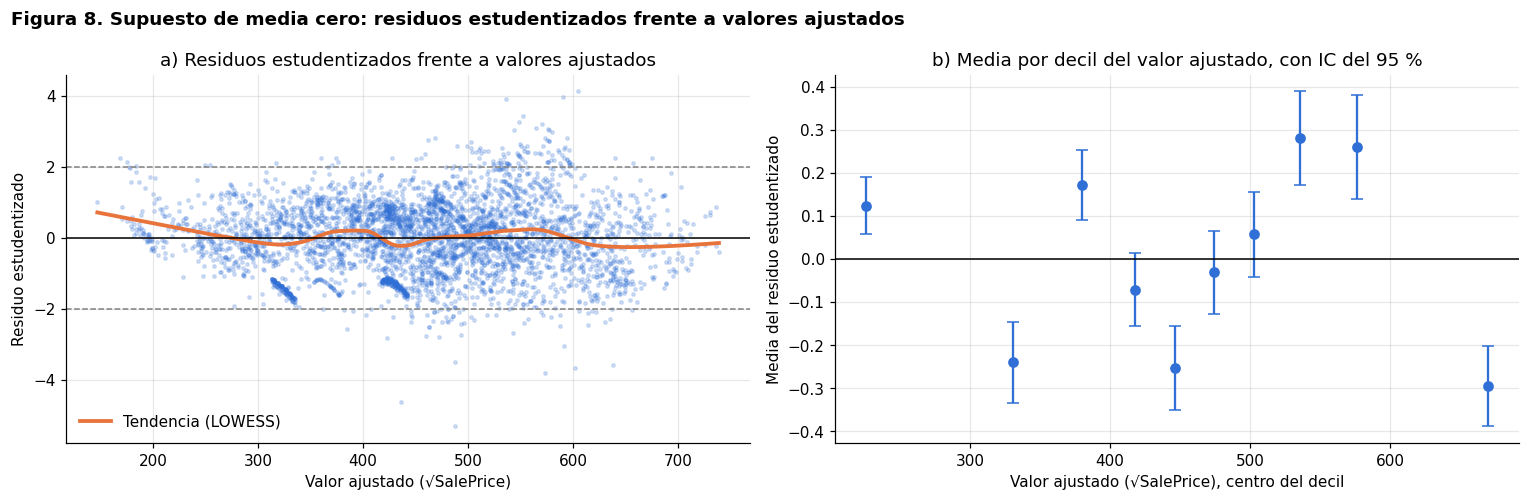

In [28]:
# Media de los residuos estudentizados por deciles del valor ajustado
deciles = pd.qcut(ajustados, 10, labels=False) + 1
filas_deciles = []
for k, grupo in residuos_estud.groupby(deciles):
    prueba = ttest_1samp(grupo, 0.0)
    ee = grupo.std(ddof=1) / np.sqrt(len(grupo))
    t_crit = st.t.ppf(0.975, len(grupo) - 1)
    filas_deciles.append({"decil": k, "ajustado_min": ajustados[deciles == k].min(),
                          "ajustado_max": ajustados[deciles == k].max(), "n": len(grupo), "media": grupo.mean(),
                          "IC95_inferior": grupo.mean() - t_crit * ee, "IC95_superior": grupo.mean() + t_crit * ee,
                          "p_valor": prueba.pvalue})
deciles_pd = pd.DataFrame(filas_deciles)
deciles_pd["IC_incluye_0"] = np.where((deciles_pd["IC95_inferior"] <= 0) & (deciles_pd["IC95_superior"] >= 0), "sí", "no")
display(HTML("<b>Media de los residuos estudentizados por decil del valor ajustado (√SalePrice)</b>"))
display(deciles_pd.style.hide(axis="index").format({
    "ajustado_min": lambda v: num_es(v, ".1f"), "ajustado_max": lambda v: num_es(v, ".1f"),
    "media": lambda v: num_es(v, ".4f"), "IC95_inferior": lambda v: num_es(v, ".4f"),
    "IC95_superior": lambda v: num_es(v, ".4f"), "p_valor": p_es}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
ax1.scatter(ajustados, residuos_estud, s=5, alpha=0.2, color=AZUL)
curva = lowess(residuos_estud, ajustados, frac=0.2)
ax1.plot(curva[:, 0], curva[:, 1], color=NARANJA, lw=2.5, label="Tendencia (LOWESS)")
ax1.axhline(0, color="black", lw=1)
for limite in (-2, 2):
    ax1.axhline(limite, color="gray", lw=1, ls="--")
ax1.set(title="a) Residuos estudentizados frente a valores ajustados",
        xlabel="Valor ajustado (√SalePrice)", ylabel="Residuo estudentizado")
ax1.legend(frameon=False, loc="lower left")

centros = (deciles_pd["ajustado_min"] + deciles_pd["ajustado_max"]) / 2
ax2.errorbar(centros, deciles_pd["media"],
             yerr=[deciles_pd["media"] - deciles_pd["IC95_inferior"], deciles_pd["IC95_superior"] - deciles_pd["media"]],
             fmt="o", color=AZUL, ecolor=AZUL, capsize=4, ms=6)
ax2.axhline(0, color="black", lw=1)
ax2.set(title="b) Media por decil del valor ajustado, con IC del 95 %",
        xlabel="Valor ajustado (√SalePrice), centro del decil", ylabel="Media del residuo estudentizado")
fig.suptitle("Figura 8. Supuesto de media cero: residuos estudentizados frente a valores ajustados",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Lectura de la Figura 8 y de la tabla por deciles**

- **La tendencia general es cercana a 0** (curva LOWESS del panel a). Solo se aleja un poco en los valores ajustados más bajos, donde hay pocos departamentos.
- **Pero la media por decil no es 0 en 7 de los 10 deciles**: sus IC del 95 % no incluyen el 0. Las desviaciones van de −0,30 (decil 10, los departamentos más caros) a +0,28 (decil 8), sin un patrón ordenado: los signos se alternan entre deciles.
- En el panel a) se ven también **líneas diagonales de puntos**. Son grupos de departamentos con las mismas características (mismo edificio y tamaño) vendidos a distintos precios: el modelo les asigna casi el mismo valor ajustado, y su residuo cambia con el precio de venta.

variable,grupos,media_minima,media_maxima,grupos_con_IC_sin_0,F_ANOVA,p_valor_ANOVA
Size_sqf,9,"-0,3997","0,5159",9,"47,6977","< 0,0001"
YrSold,11,"-0,4109","0,8716",8,"57,8118","< 0,0001"
MonthSold,12,"-0,3019","0,2130",4,"6,7531","< 0,0001"
Floor,10,"-0,1146","0,1202",2,"2,2444","0,0169"
N_FacilitiesInApt,9,"-0,3623","0,8549",6,"48,0839","< 0,0001"
HallwayType,3,"-0,0001","0,0001",0,"0,0000","1,0000"
SubwayStation,8,"-0,0001","0,0004",0,"0,0000","1,0000"


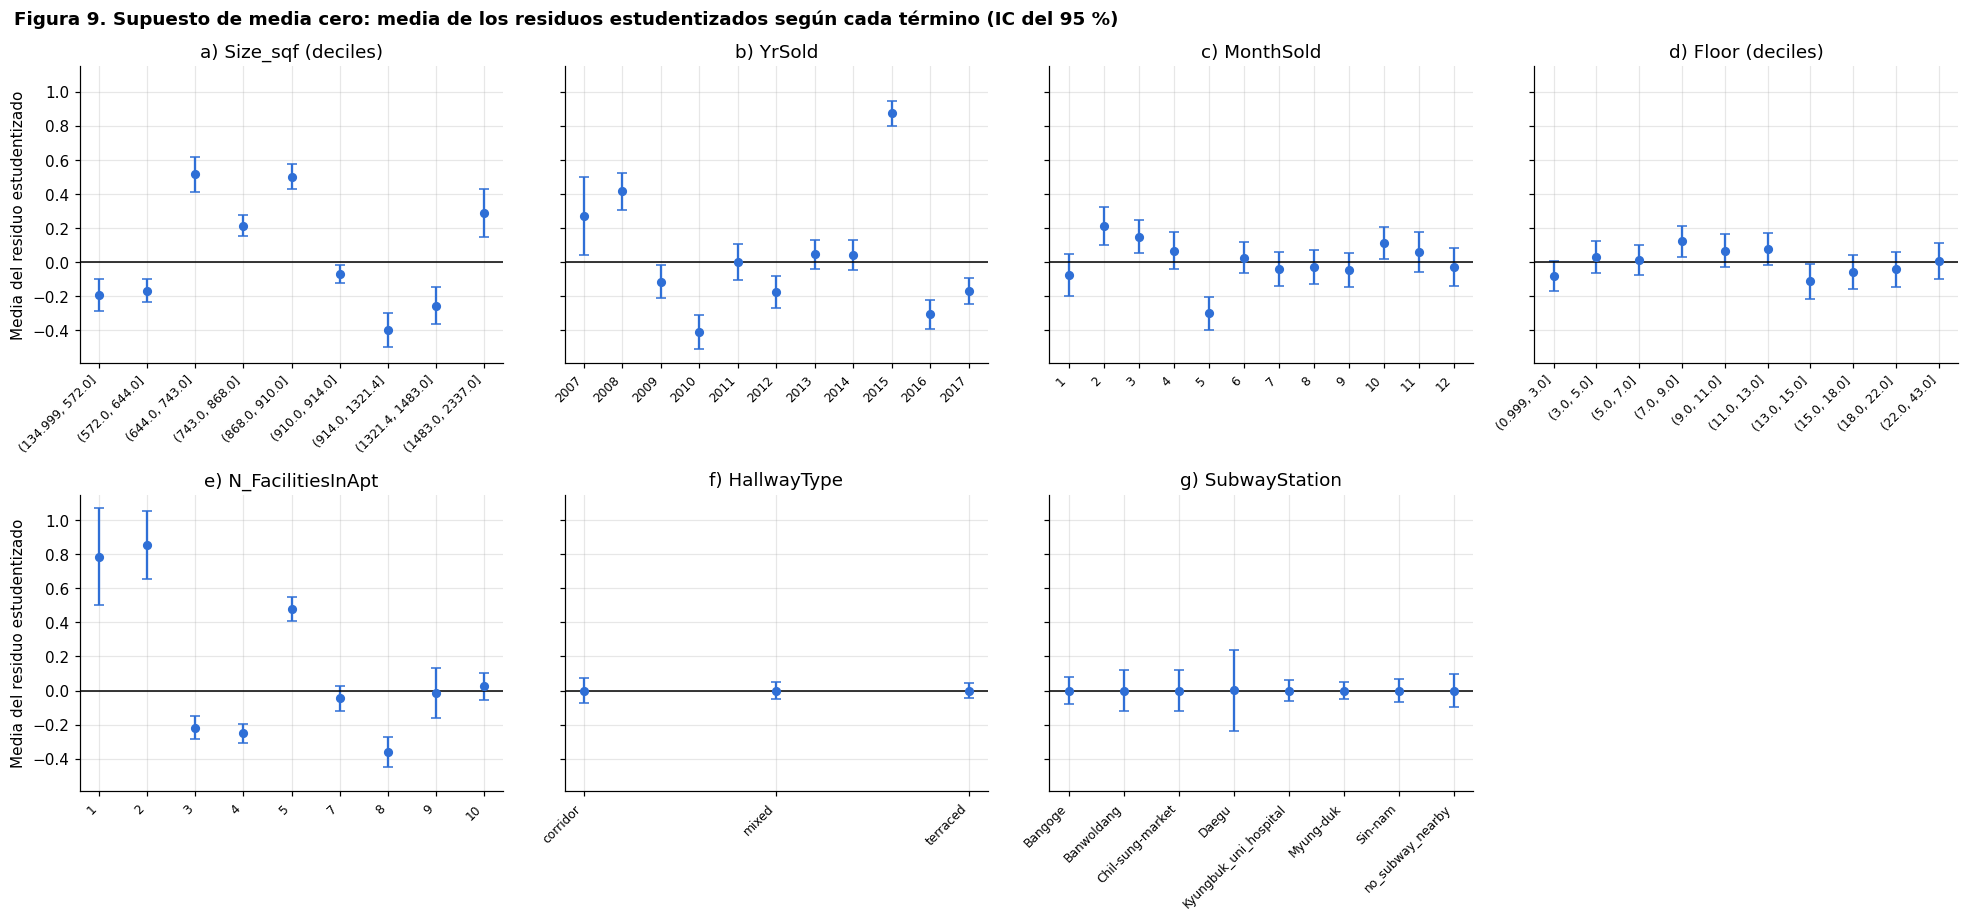

In [29]:
# Media de los residuos estudentizados según cada uno de los 7 términos
def grupos_variable(c):
    if c in categoricos:
        return train[c]
    if train[c].nunique() <= 15:
        return train[c]
    return pd.qcut(train[c], 10, duplicates="drop")  # variables con muchos valores: deciles


filas_por_variable, medias_por_variable = [], {}
for c in numericos + list(categoricos):
    g = grupos_variable(c)
    resumen = residuos_estud.groupby(g, observed=True).agg(["mean", "std", "count"])
    t_crit = st.t.ppf(0.975, resumen["count"] - 1)
    resumen["ic"] = t_crit * resumen["std"] / np.sqrt(resumen["count"])
    medias_por_variable[c] = resumen
    anova = f_oneway(*[grupo.values for _, grupo in residuos_estud.groupby(g, observed=True)])
    filas_por_variable.append({"variable": c, "grupos": len(resumen),
                               "media_minima": resumen["mean"].min(), "media_maxima": resumen["mean"].max(),
                               "grupos_con_IC_sin_0": int(((resumen["mean"] - resumen["ic"]) > 0).sum()
                                                          + ((resumen["mean"] + resumen["ic"]) < 0).sum()),
                               "F_ANOVA": anova.statistic, "p_valor_ANOVA": anova.pvalue})
por_variable_pd = pd.DataFrame(filas_por_variable)
display(HTML("<b>Media de los residuos estudentizados según cada término</b> "
             "(ANOVA de un factor, H₀: la media del residuo es igual en todos los grupos)"))
display(por_variable_pd.style.hide(axis="index").format({
    "media_minima": lambda v: num_es(v, ".4f"), "media_maxima": lambda v: num_es(v, ".4f"),
    "F_ANOVA": lambda v: num_es(v, ".4f"), "p_valor_ANOVA": p_es}))

fig, ejes = plt.subplots(2, 4, figsize=(18, 8.5), sharey=True)
for ax, letra, c in zip(ejes.flat, "abcdefg", numericos + list(categoricos)):
    resumen = medias_por_variable[c]
    etiquetas = [str(v) for v in resumen.index]
    posiciones = np.arange(len(resumen))
    ax.errorbar(posiciones, resumen["mean"], yerr=resumen["ic"], fmt="o", color=AZUL, ecolor=AZUL, capsize=3, ms=5)
    ax.axhline(0, color="black", lw=1)
    ax.set_xticks(posiciones, etiquetas, rotation=45 if len(etiquetas) > 6 or c in categoricos else 0,
                  ha="right" if len(etiquetas) > 6 or c in categoricos else "center", fontsize=8)
    titulo = f"{letra}) {c}" + (" (deciles)" if c in numericos and train[c].nunique() > 15 else "")
    ax.set(title=titulo)
for ax in ejes[:, 0]:
    ax.set_ylabel("Media del residuo estudentizado")
ejes.flat[7].axis("off")
fig.suptitle("Figura 9. Supuesto de media cero: media de los residuos estudentizados según cada término (IC del 95 %)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Lectura de la Figura 9 y de la tabla por término**

- **`HallwayType` y `SubwayStation` cumplen el supuesto** (media 0 en todas sus categorías, p = 1). Esto ocurre por construcción: cada categoría tiene su propia indicadora en el modelo, y mínimos cuadrados hace que el residuo promedio de cada una sea 0.
- **`Floor` lo cumple casi por completo:** las medias por decil van de −0,11 a 0,12, solo 2 de 10 IC excluyen el 0 y el ANOVA es apenas significativo (p = 0,017).
- **`MonthSold` tiene desviaciones moderadas:** la mayoría de los meses está cerca de 0, salvo mayo (−0,30) y febrero (+0,21).
- **`YrSold`, `N_FacilitiesInApt` y `Size_sqf` no cumplen el supuesto** (ANOVA con p < 0,0001):
  - **`YrSold`:** en 2015 el modelo subestima el precio en 0,87 desviaciones estándar en promedio, y en 2010 y 2016 lo sobreestima (−0,41 y −0,31). La curva cuadrática describe la tendencia general, pero no los saltos de un año a otro, como el pico de 2015 que se ve en la Figura 3.
  - **`N_FacilitiesInApt`:** los departamentos con 1, 2 y 5 instalaciones quedan subestimados (+0,79, +0,85 y +0,48) y los de 3, 4 y 8 sobreestimados (−0,22, −0,25 y −0,36). El patrón no es una curva sino saltos, porque cada valor corresponde a unos pocos edificios: la recta resume el efecto promedio, pero no el nivel de precio propio de cada edificio.
  - **`Size_sqf`:** las medias por decil alternan de signo (de −0,40 a +0,52). Los tamaños se concentran en pocos valores, que corresponden a tipos de departamento de edificios concretos, y la curva cuadrática no captura las diferencias entre ellos.

**Conclusión de 6.1**

El supuesto de media cero **se cumple globalmente y para las variables categóricas y `Floor`, pero no se cumple condicionalmente** para `YrSold`, `N_FacilitiesInApt` y `Size_sqf`, ni en varios deciles del valor ajustado. Las desviaciones son de hasta 0,4 desviaciones estándar en la mayoría de los grupos y de hasta 0,87 en los casos extremos (año 2015 y edificios con 1 o 2 instalaciones). El modelo es insesgado en promedio, pero se equivoca de forma sistemática en ciertos años y en ciertos edificios. En la mayoría de los casos esto refleja diferencias de precio entre años y entre edificios que las formas suaves (rectas y parábolas) no alcanzan a representar.

### 6.2 Varianza constante

**Supuesto:** Var(ε | X) = σ², la misma para todos los departamentos (homocedasticidad). Si no se cumple, los coeficientes siguen siendo insesgados, pero los errores estándar clásicos dejan de ser correctos y las pruebas t y F pueden equivocarse.

**Prueba de Breusch-Pagan**

- **H₀:** la varianza de los errores es constante. **H₁:** la varianza depende de los términos del modelo.
- **Procedimiento:** se ajusta una regresión auxiliar de los residuos al cuadrado sobre los 16 términos del modelo. Si la varianza fuera constante, esos términos no explicarían nada de los residuos al cuadrado.
- **Estadístico:** el multiplicador de Lagrange LM = n·R² de la regresión auxiliar, que bajo H₀ sigue una χ² con 16 grados de libertad. Se rechaza H₀ si LM supera el valor crítico, o si p < 0,05. También se reporta la versión F, equivalente. Los estadísticos t de la regresión auxiliar indican **de qué términos depende la varianza**.

**Intento de corrección: transformación de Box-Cox.** Una forma usual de estabilizar la varianza es transformar la variable dependiente: y(λ) = (y^λ − 1)/λ, y log(y) si λ = 0. λ = 1 deja `SalePrice` sin transformar y λ = 0,5 equivale a la raíz cuadrada del modelo final. El λ óptimo se estima por máxima verosimilitud de perfil; su intervalo de confianza del 95 % incluye los λ cuya log-verosimilitud está a menos de 1,92 del máximo. Para comparar las escalas se usa también la **razón de dispersión**: la desviación estándar de los residuos estudentizados en el 20 % de valores ajustados más altos dividida por la del 20 % más bajo, que vale 1 si la varianza es constante.

In [30]:
from statsmodels.stats.diagnostic import het_breuschpagan

lm_bp, p_lm_bp, f_bp, p_f_bp = het_breuschpagan(ajuste_clasico.resid, X_elegida)
gl_bp = X_elegida.shape[1] - 1
bp_pd = pd.DataFrame([
    {"version": "Multiplicador de Lagrange (n·R² auxiliar)", "estadistico": lm_bp, "distribucion": f"χ² con {gl_bp} gl",
     "valor_critico_5pct": st.chi2.ppf(0.95, gl_bp), "p_valor": p_lm_bp},
    {"version": "F", "estadistico": f_bp, "distribucion": f"F({gl_bp}, {n_obs - gl_bp - 1})",
     "valor_critico_5pct": st.f.ppf(0.95, gl_bp, n_obs - gl_bp - 1), "p_valor": p_f_bp},
])
bp_pd["decision_5pct"] = np.where(bp_pd["p_valor"] < 0.05, "se rechaza H₀: varianza no constante", "no se rechaza H₀")
display(HTML("<b>Prueba de Breusch-Pagan del modelo final</b> (MCO con √SalePrice; "
             "H₀: la varianza de los errores es constante)"))
display(bp_pd.style.hide(axis="index").format({
    "estadistico": lambda v: num_es(v, ",.2f"), "valor_critico_5pct": lambda v: num_es(v, ",.2f"), "p_valor": p_es}))

# Regresión auxiliar de la prueba: residuos² sobre los términos del modelo. Sus t indican de qué depende la varianza.
auxiliar_bp = sm.OLS(ajuste_clasico.resid ** 2, X_elegida).fit()
auxiliar_pd = pd.DataFrame({"termino": X_elegida.columns, "estadistico_t": auxiliar_bp.tvalues.values,
                            "p_valor": auxiliar_bp.pvalues.values})
auxiliar_pd = auxiliar_pd[auxiliar_pd["termino"] != "const"].sort_values("estadistico_t", key=np.abs, ascending=False)
display(HTML("<b>Regresión auxiliar de Breusch-Pagan: términos de los que depende la varianza</b> "
             "(t positivo: la varianza aumenta con el término)"))
display(auxiliar_pd.style.hide(axis="index").format({"estadistico_t": lambda v: num_es(v, ".2f"), "p_valor": p_es}))

version,estadistico,distribucion,valor_critico_5pct,p_valor,decision_5pct
Multiplicador de Lagrange (n·R² auxiliar),"573,56",χ² con 16 gl,"26,30","< 0,0001",se rechaza H₀: varianza no constante
F,"41,47","F(16, 4106)","1,65","< 0,0001",se rechaza H₀: varianza no constante


termino,estadistico_t,p_valor
1/MonthSold,"9,68","< 0,0001"
SubwayStation_Banwoldang,"8,29","< 0,0001"
SubwayStation_Sin-nam,"-8,00","< 0,0001"
(Size_sqf - media)²,"7,10","< 0,0001"
HallwayType_corridor,"-4,66","< 0,0001"
SubwayStation_Myung-duk,"-4,45","< 0,0001"
SubwayStation_Chil-sung-market,"-3,83","0,0001"
YrSold,"-3,83","0,0001"
SubwayStation_no_subway_nearby,"-3,68","0,0002"
HallwayType_mixed,"-2,09","0,0363"


SalePrice,lambda,log_verosimilitud_perfil,Breusch_Pagan,p_valor_BP,razon_dispersion
sin transformar (λ = 1),"1,000","-43.153,6","844,0","< 0,0001","2,000"
"raíz cuadrada (λ = 0,5)","0,500","-42.531,5","573,6","< 0,0001","1,337"
"Box-Cox estimado (λ = 0,362)","0,362","-42.494,9","535,1","< 0,0001","1,172"


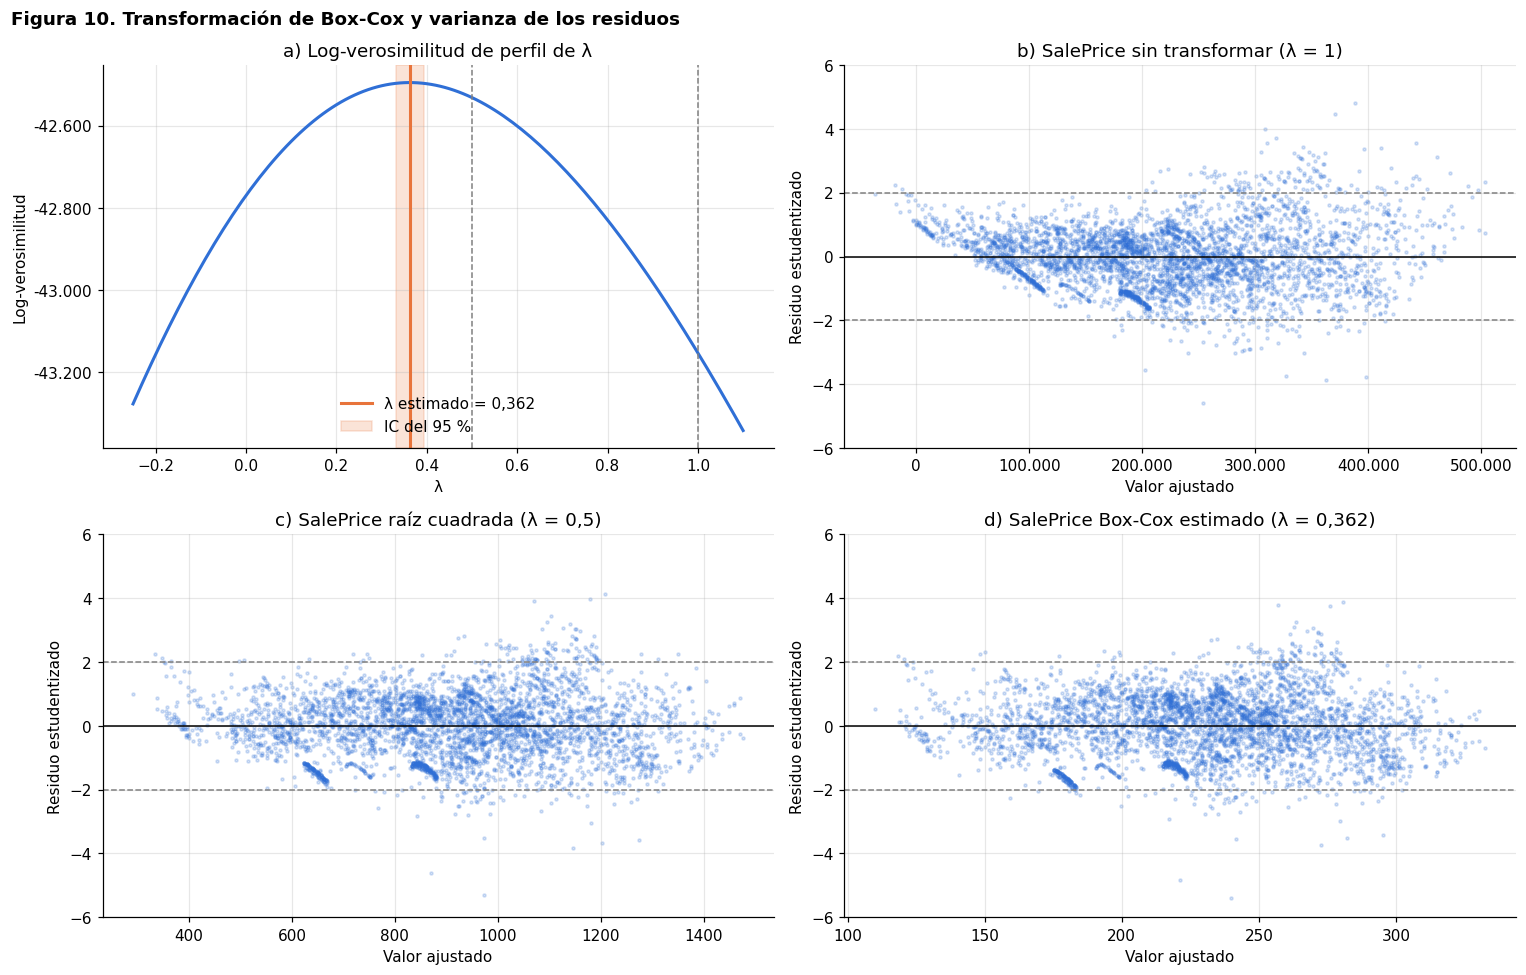

In [31]:
from scipy.optimize import brentq, minimize_scalar
from scipy.stats import anderson, jarque_bera, kurtosis, normaltest, skew
from statsmodels.stats.diagnostic import lilliefors

# Box-Cox de SalePrice: y(λ) = (y^λ − 1) / λ, y log(y) si λ = 0. λ se estima por máxima verosimilitud de perfil
# con la misma estructura de términos del modelo final.
suma_log_y = float(np.log(y_venta).sum())


def bc_y(lam):
    return np.log(y_venta) if abs(lam) < 1e-9 else (y_venta ** lam - 1) / lam


def log_ver_perfil(lam):
    aj = sm.OLS(bc_y(lam), X_elegida).fit()
    return -n_obs / 2 * np.log(aj.ssr / n_obs) + (lam - 1) * suma_log_y


lambda_bc = float(minimize_scalar(lambda l: -log_ver_perfil(l), bounds=(-1, 1.5), method="bounded").x)
umbral_ic = log_ver_perfil(lambda_bc) - st.chi2.ppf(0.95, 1) / 2  # IC del 95 % por razón de verosimilitud
ic_lambda = (brentq(lambda l: log_ver_perfil(l) - umbral_ic, lambda_bc - 1, lambda_bc),
             brentq(lambda l: log_ver_perfil(l) - umbral_ic, lambda_bc, lambda_bc + 1))
display(HTML(f"<b>λ de Box-Cox estimado:</b> {coma(lambda_bc, 3)} "
             f"(IC del 95 %: {coma(ic_lambda[0], 3)} a {coma(ic_lambda[1], 3)})"))


def razon_dispersion_r(r, ajustados_):
    quintil = pd.qcut(ajustados_, 5, labels=False)
    return r[quintil == 4].std() / r[quintil == 0].std()


modelos_lambda = {}
filas_lambda = []
for nombre, lam in [("sin transformar (λ = 1)", 1.0), ("raíz cuadrada (λ = 0,5)", 0.5),
                    (f"Box-Cox estimado (λ = {coma(lambda_bc, 3)})", lambda_bc)]:
    aj = sm.OLS(bc_y(lam), X_elegida).fit()
    r = pd.Series(OLSInfluence(aj).resid_studentized_internal, index=train.index)
    modelos_lambda[nombre] = (aj, r)
    lm, lm_p, _, _ = het_breuschpagan(aj.resid, X_elegida)
    filas_lambda.append({"SalePrice": nombre, "lambda": lam, "log_verosimilitud_perfil": log_ver_perfil(lam),
                         "Breusch_Pagan": lm, "p_valor_BP": lm_p,
                         "razon_dispersion": razon_dispersion_r(r, aj.fittedvalues)})
lambda_pd = pd.DataFrame(filas_lambda)
display(HTML("<b>Varianza de los residuos según la transformación de SalePrice</b>"))
display(lambda_pd.style.hide(axis="index").format({
    "lambda": lambda v: num_es(v, ".3f"), "log_verosimilitud_perfil": lambda v: num_es(v, ",.1f"),
    "Breusch_Pagan": lambda v: num_es(v, ",.1f"), "p_valor_BP": p_es,
    "razon_dispersion": lambda v: num_es(v, ".3f")}))

fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
ax = ejes[0, 0]
ax.plot(rejilla := np.linspace(-0.25, 1.1, 136), [log_ver_perfil(l) for l in rejilla], color=AZUL, lw=2)
ax.axvline(lambda_bc, color=NARANJA, lw=2, label=f"λ estimado = {coma(lambda_bc, 3)}")
ax.axvspan(*ic_lambda, color=NARANJA, alpha=0.2, label="IC del 95 %")
for ref in (0.5, 1.0):
    ax.axvline(ref, color="gray", lw=1, ls="--")
ax.yaxis.set_major_formatter(miles)
ax.set(title="a) Log-verosimilitud de perfil de λ", xlabel="λ", ylabel="Log-verosimilitud")
ax.legend(frameon=False, loc="lower center")
for ax, letra, (nombre, (aj, r)) in zip([ejes[0, 1], ejes[1, 0], ejes[1, 1]], "bcd", modelos_lambda.items()):
    ax.scatter(aj.fittedvalues, r, s=4, alpha=0.2, color=AZUL)
    for limite in (-2, 2):
        ax.axhline(limite, color="gray", lw=1, ls="--")
    ax.axhline(0, color="black", lw=1)
    limite_y = max(6, float(np.abs(r).max()) + 0.5)
    ax.set(title=f"{letra}) SalePrice {nombre}", xlabel="Valor ajustado", ylabel="Residuo estudentizado",
           ylim=(-limite_y, limite_y))
    if "λ = 1)" in nombre:
        ax.xaxis.set_major_formatter(miles)
fig.suptitle("Figura 10. Transformación de Box-Cox y varianza de los residuos", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Resultado de la varianza constante**

- **El modelo final no cumple el supuesto:** LM = 573,56, muy por encima del valor crítico de 26,30 (χ² con 16 gl), con p < 0,0001; la versión F da la misma conclusión (41,47 frente a 1,65).
- **De qué depende la varianza:** es mayor en los departamentos vendidos a principios de año (`1/MonthSold`), en los cercanos a *Banwoldang* y en los de tamaño alejado del promedio (`(Size_sqf − media)²`). Es menor cerca de *Sin-nam*, *Myung-duk* y *Chil-sung-market*, sin metro cercano, en edificios *corridor* y en los años más recientes. La varianza no depende solo del nivel del precio, sino sobre todo de **la ubicación, el tipo de edificio y el momento de la venta**.
- **La transformación de Box-Cox no lo corrige:** el λ óptimo es 0,362 (IC del 95 %: 0,331 a 0,393). Reduce la razón de dispersión de 1,34 (raíz cuadrada) a 1,17, pero la prueba de Breusch-Pagan sigue rechazando con claridad (535,1 frente a 573,6). En la Figura 10 la diferencia entre los paneles c) y d) es pequeña. La raíz cuadrada ya captura casi toda la mejora frente a `SalePrice` sin transformar (razón de 2,00 y BP de 844,0).

**Decisión:** se mantiene la raíz cuadrada, que es más fácil de interpretar y casi igual de efectiva, y se usan **errores estándar robustos HC3** en todas las pruebas del modelo (sección 5). Los errores HC3 no hacen constante la varianza, pero corrigen los errores estándar para que las pruebas t y F sigan siendo válidas.

### 6.3 Normalidad de los residuos

**Supuesto:** ε ~ Normal(0, σ²). La normalidad hace que las pruebas t y F y los intervalos de confianza sean exactos. Con muestras grandes, como esta (n = 4.123), las pruebas sobre los coeficientes siguen siendo aproximadamente válidas aunque los errores no sean normales (teorema central del límite). Donde más importa la normalidad es en los intervalos de predicción de departamentos individuales.

Se revisan los residuos estudentizados del modelo final (los mismos de 6.1), que bajo normalidad siguen aproximadamente una N(0, 1):

- **Histograma** comparado con la curva normal estándar, y **gráfico Q-Q**: si los residuos son normales, los puntos caen sobre la recta.
- **Pruebas de normalidad** (H₀: los residuos son normales). Jarque-Bera y D'Agostino-Pearson miden la asimetría y la curtosis; Kolmogorov-Smirnov (con la corrección de Lilliefors) mide la mayor distancia entre la distribución de los residuos y la normal; Anderson-Darling hace lo mismo dando más peso a las colas, y se compara con su valor crítico al 5 %.
- **Forma de la distribución:** asimetría y curtosis en exceso (ambas valen 0 en una normal), y porcentaje de residuos con |r| > 2 y |r| > 3 (4,55 % y 0,27 % en una normal).

prueba,mide,estadistico,p_valor,conclusion_5pct
Jarque-Bera,asimetría y curtosis,"15,359","0,0005",se rechaza normalidad
D'Agostino-Pearson (K²),asimetría y curtosis,"12,176","0,0023",se rechaza normalidad
Kolmogorov-Smirnov (Lilliefors),distancia máxima entre distribuciones,"0,033","0,0010",se rechaza normalidad
Anderson-Darling,"distancia, con más peso en las colas","4,627",—,"se rechaza normalidad (valor crítico al 5 %: 0,752)"


medida,valor,valor_esperado_si_normal
Asimetría,"0,008","0,00"
Curtosis en exceso,"0,299","0,00"
% de residuos con |r| > 2,"4,366","4,55"
% de residuos con |r| > 3,"0,412","0,27"


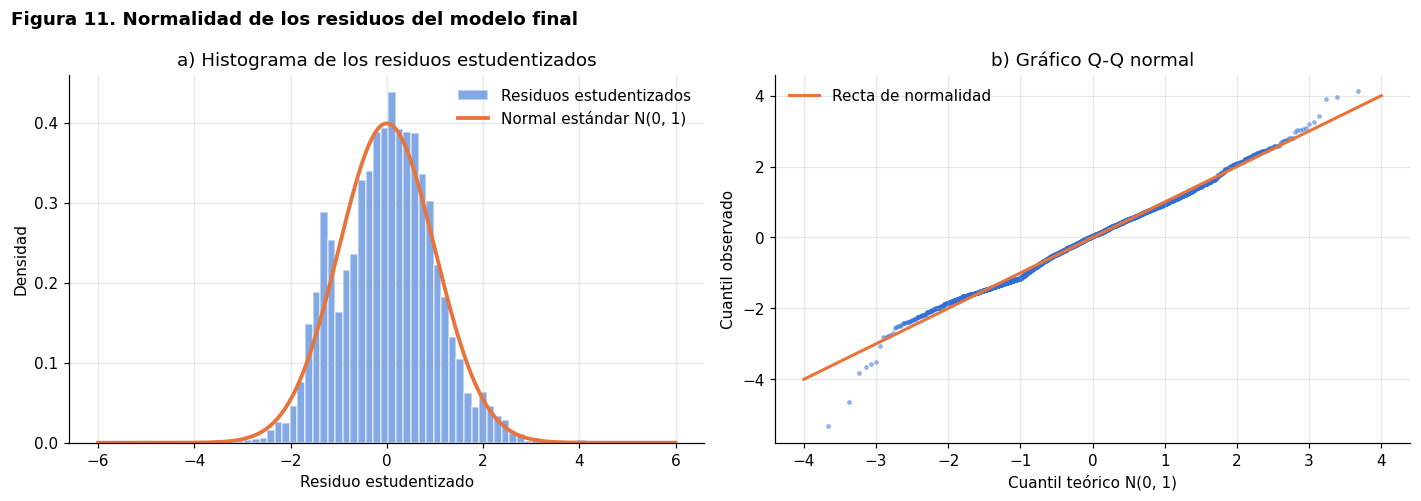

In [32]:
# Normalidad de los residuos estudentizados del modelo final (calculados en 6.1)
r_final = residuos_estud
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    ad = anderson(r_final, dist="norm")
ks_estad, ks_p = lilliefors(r_final, dist="norm")
jb = jarque_bera(r_final)
dag = normaltest(r_final)
pruebas_normalidad = pd.DataFrame([
    {"prueba": "Jarque-Bera", "mide": "asimetría y curtosis", "estadistico": jb.statistic, "p_valor": jb.pvalue},
    {"prueba": "D'Agostino-Pearson (K²)", "mide": "asimetría y curtosis", "estadistico": dag.statistic, "p_valor": dag.pvalue},
    {"prueba": "Kolmogorov-Smirnov (Lilliefors)", "mide": "distancia máxima entre distribuciones", "estadistico": ks_estad, "p_valor": ks_p},
    {"prueba": "Anderson-Darling", "mide": "distancia, con más peso en las colas", "estadistico": ad.statistic,
     "p_valor": np.nan},
])
pruebas_normalidad["conclusion_5pct"] = np.where(pruebas_normalidad["p_valor"] < 0.05, "se rechaza normalidad", "no se rechaza")
valor_critico_ad = ad.critical_values[list(ad.significance_level).index(5.0)]
pruebas_normalidad.loc[3, "conclusion_5pct"] = ("se rechaza normalidad" if ad.statistic > valor_critico_ad else "no se rechaza") \
    + f" (valor crítico al 5 %: {coma(valor_critico_ad, 3)})"
display(HTML("<b>Pruebas de normalidad de los residuos estudentizados</b> (H₀: los residuos siguen una distribución normal)"))
display(pruebas_normalidad.style.hide(axis="index").format({
    "estadistico": lambda v: num_es(v, ",.3f"), "p_valor": lambda v: "—" if pd.isna(v) else p_es(v)}))

forma_pd = pd.DataFrame([
    {"medida": "Asimetría", "valor": skew(r_final), "valor_esperado_si_normal": 0.0},
    {"medida": "Curtosis en exceso", "valor": kurtosis(r_final), "valor_esperado_si_normal": 0.0},
    {"medida": "% de residuos con |r| > 2", "valor": (np.abs(r_final) > 2).mean() * 100, "valor_esperado_si_normal": 4.55},
    {"medida": "% de residuos con |r| > 3", "valor": (np.abs(r_final) > 3).mean() * 100, "valor_esperado_si_normal": 0.27},
])
display(HTML("<b>Forma de la distribución de los residuos estudentizados</b>"))
display(forma_pd.style.hide(axis="index").format({
    "valor": lambda v: num_es(v, ".3f"), "valor_esperado_si_normal": lambda v: num_es(v, ".2f")}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
ax1.hist(r_final, bins=60, density=True, color=AZUL, alpha=0.6, edgecolor="white", label="Residuos estudentizados")
rejilla_n = np.linspace(-6, 6, 400)
ax1.plot(rejilla_n, st.norm.pdf(rejilla_n), color=NARANJA, lw=2.5, label="Normal estándar N(0, 1)")
ax1.set(title="a) Histograma de los residuos estudentizados", xlabel="Residuo estudentizado", ylabel="Densidad")
ax1.legend(frameon=False)
teoricos = st.norm.ppf((np.arange(1, n_obs + 1) - 0.5) / n_obs)
ax2.scatter(teoricos, np.sort(r_final.values), s=5, alpha=0.4, color=AZUL)
ax2.plot([-4, 4], [-4, 4], color=NARANJA, lw=2, label="Recta de normalidad")
ax2.set(title="b) Gráfico Q-Q normal", xlabel="Cuantil teórico N(0, 1)", ylabel="Cuantil observado")
ax2.legend(frameon=False)
fig.suptitle("Figura 11. Normalidad de los residuos del modelo final",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Resultado de la normalidad**

- **Las cuatro pruebas rechazan la normalidad** (Jarque-Bera p = 0,0005, D'Agostino-Pearson p = 0,002, Kolmogorov-Smirnov p = 0,001 y Anderson-Darling 4,63 frente al valor crítico de 0,75).
- **Pero la desviación es muy pequeña:** la asimetría es 0,01 y la curtosis en exceso 0,30, ambas muy cerca de 0. El 4,4 % de los residuos supera |2| (4,55 % en una normal) y el 0,41 % supera |3| (0,27 % en una normal; son 17 departamentos frente a unos 11 esperados). En el gráfico Q-Q los puntos siguen la recta en casi todo el rango.
- Con 4.123 observaciones, las pruebas detectan incluso desviaciones mínimas. **Los residuos son prácticamente normales**, gracias en buena parte al retiro del id 3798: con ese departamento, la curtosis en exceso era 1,33 (sección 6.5). Además, con una muestra de este tamaño, las pruebas sobre los coeficientes no dependen de la normalidad (teorema central del límite).

### 6.4 Independencia de los errores

**Supuesto:** los errores de distintos departamentos no están correlacionados: Cov(εᵢ, εⱼ) = 0. Si los errores de observaciones cercanas se parecen (autocorrelación), los coeficientes siguen siendo insesgados, pero los errores estándar subestiman la incertidumbre: los estadísticos t salen más grandes y los p-valores más pequeños de lo que deberían.

**Estadístico de Durbin-Watson**

DW = Σ (eₜ − eₜ₋₁)² / Σ eₜ², con t = 2, …, n

- Compara el residuo de cada observación con el de la anterior. Va de 0 a 4 y es aproximadamente 2·(1 − ρ), donde ρ es la correlación entre residuos consecutivos.
- **DW ≈ 2:** no hay autocorrelación. **DW < 2:** autocorrelación positiva (residuos consecutivos parecidos). **DW > 2:** autocorrelación negativa. Una regla práctica es preocuparse si DW < 1,5 o DW > 2,5.
- **H₀:** ρ = 0 (errores independientes). Las tablas de valores críticos de Durbin-Watson no llegan a n = 4.123, así que el p-valor se obtiene con la aproximación normal para muestras grandes: bajo H₀, DW ~ N(2, 4/n). Como confirmación se reporta la prueba de Breusch-Godfrey con un rezago.

**El orden importa.** DW mide la correlación entre observaciones **consecutivas**, así que depende de cómo se ordenen los datos. El orden natural es el **cronológico**: el archivo ya está ordenado por fecha de venta (el id sigue la fecha). También se calcula ordenando por edificio y fecha, para ver si la dependencia viene de departamentos del mismo edificio, y en orden aleatorio, como referencia de lo que daría el estadístico sin dependencia.

orden_de_los_datos,Durbin_Watson,rho_estimado,correlacion_e_t_e_t_menos_1,z,p_valor,decision_5pct
cronológico (fecha de venta),"1,104","0,448","0,448","-28,8","< 0,0001",se rechaza H₀: errores autocorrelacionados
por edificio y fecha,"0,623","0,689","0,688","-44,2","< 0,0001",se rechaza H₀: errores autocorrelacionados
aleatorio (referencia),"1,985","0,007","0,007","-0,5","0,6392",no se rechaza H₀


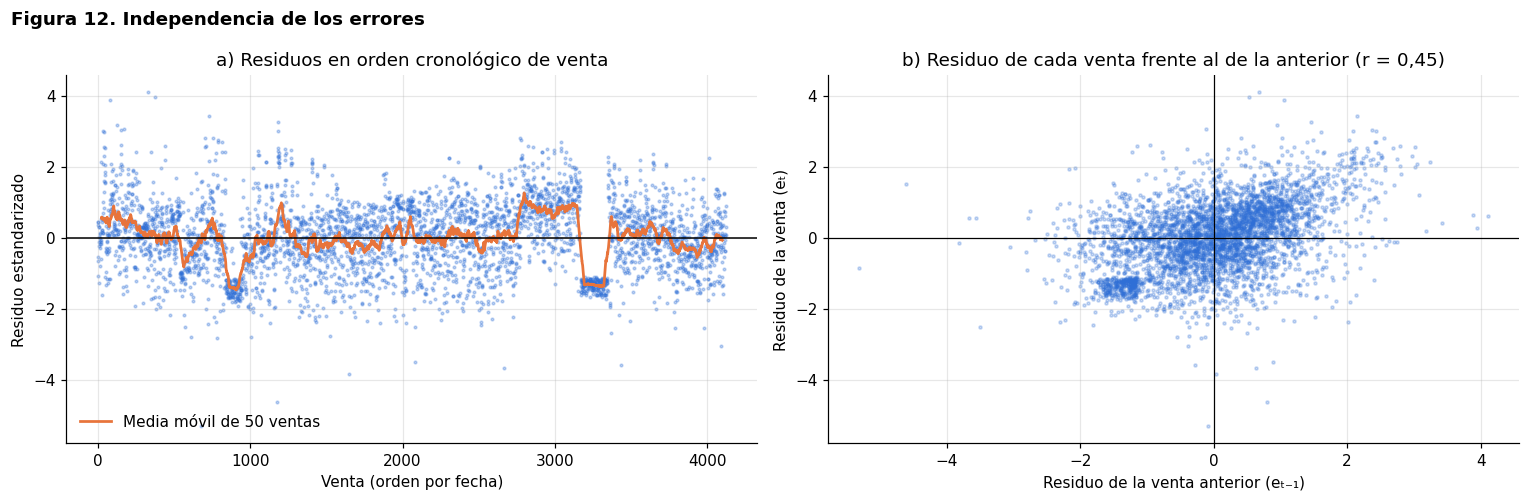

In [33]:
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson

# Durbin-Watson depende del orden de las observaciones. El orden natural es el cronológico (fecha de venta);
# el archivo ya viene así (el id sigue la fecha de venta).
orden_cronologico = train.sort_values(["YrSold", "MonthSold", "id"]).index
ajuste_cronologico = sm.OLS(y_elegida.loc[orden_cronologico], X_elegida.loc[orden_cronologico]).fit()
e_crono = ajuste_cronologico.resid

# Orden por edificio y fecha: muestra si la dependencia viene de departamentos del mismo edificio
columnas_edificio = ["YearBuilt", "N_Parkinglot_Ground", "N_Parkinglot_Basement", "N_APT", "N_manager",
                     "N_elevators", "N_FacilitiesInApt", "HallwayType", "SubwayStation", "TimeToBusStop"]
clave_edificio = train[columnas_edificio].astype(str).agg("|".join, axis=1)
orden_edificio = train.assign(edificio=clave_edificio).sort_values(["edificio", "YrSold", "MonthSold", "id"]).index
# Orden aleatorio: referencia de lo que daría el estadístico sin dependencia
orden_aleatorio = train.index[np.random.default_rng(42).permutation(n_obs)]


def fila_dw(nombre, orden):
    e = ajuste_clasico.resid.loc[orden].values
    dw = durbin_watson(e)
    z = (dw - 2) / np.sqrt(4 / n_obs)  # aproximación normal de DW bajo H₀ para n grande
    return {"orden_de_los_datos": nombre, "Durbin_Watson": dw, "rho_estimado": 1 - dw / 2,
            "correlacion_e_t_e_t_menos_1": np.corrcoef(e[:-1], e[1:])[0, 1], "z": z, "p_valor": 2 * st.norm.sf(abs(z))}


dw_pd = pd.DataFrame([fila_dw("cronológico (fecha de venta)", orden_cronologico),
                      fila_dw("por edificio y fecha", orden_edificio),
                      fila_dw("aleatorio (referencia)", orden_aleatorio)])
dw_pd["decision_5pct"] = np.where(dw_pd["p_valor"] < 0.05, "se rechaza H₀: errores autocorrelacionados", "no se rechaza H₀")
display(HTML("<b>Prueba de Durbin-Watson del modelo final</b> (H₀: los errores no están autocorrelacionados)"))
display(dw_pd.style.hide(axis="index").format({
    "Durbin_Watson": lambda v: num_es(v, ".3f"), "rho_estimado": lambda v: num_es(v, ".3f"),
    "correlacion_e_t_e_t_menos_1": lambda v: num_es(v, ".3f"), "z": lambda v: num_es(v, ".1f"), "p_valor": p_es}))

import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    bg = acorr_breusch_godfrey(ajuste_cronologico, nlags=1)
display(HTML(f"<b>Prueba de Breusch-Godfrey (orden cronológico, 1 rezago):</b> LM = {num_es(bg[0], ',.1f')}, "
             f"p {p_es(bg[1]) if bg[1] < 1e-4 else '= ' + p_es(bg[1])}"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
r_crono = (e_crono / np.sqrt(ajuste_cronologico.mse_resid)).values
ax1.scatter(np.arange(n_obs), r_crono, s=3, alpha=0.3, color=AZUL)
media_movil = pd.Series(r_crono).rolling(50, center=True).mean()
ax1.plot(np.arange(n_obs), media_movil, color=NARANJA, lw=1.8, label="Media móvil de 50 ventas")
ax1.axhline(0, color="black", lw=1)
ax1.set(title="a) Residuos en orden cronológico de venta", xlabel="Venta (orden por fecha)", ylabel="Residuo estandarizado")
ax1.legend(frameon=False, loc="lower left")
ax2.scatter(r_crono[:-1], r_crono[1:], s=4, alpha=0.25, color=AZUL)
ax2.axhline(0, color="black", lw=0.8)
ax2.axvline(0, color="black", lw=0.8)
ax2.set(title=f"b) Residuo de cada venta frente al de la anterior (r = {coma(np.corrcoef(r_crono[:-1], r_crono[1:])[0, 1], 2)})",
        xlabel="Residuo de la venta anterior (eₜ₋₁)", ylabel="Residuo de la venta (eₜ)")
fig.suptitle("Figura 12. Independencia de los errores", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Resultado de la independencia**

- **Se rechaza la independencia:** en orden cronológico, DW = 1,10, lejos de 2 y por debajo de 1,5. La correlación entre residuos de ventas consecutivas es ρ = 0,45 (p < 0,0001). La prueba de Breusch-Godfrey llega a la misma conclusión (LM = 886,8, p < 0,0001). En orden aleatorio, en cambio, DW = 1,99: la dependencia es real y está en el orden de los datos.
- **De dónde viene:** al ordenar por edificio y fecha, DW baja a 0,62 (ρ = 0,69). Los errores de departamentos **del mismo edificio** se parecen: si el modelo sobreestima un departamento, suele sobreestimar también a sus vecinos. En la Figura 12a se ven bloques de ventas consecutivas con residuos parecidos, por ejemplo cerca de las ventas 900 y 3.200, donde un grupo de departamentos del mismo edificio vendidos en pocos meses queda con residuos cercanos a −1,4. Es la misma causa que en 6.1: el modelo no captura el nivel de precio propio de cada edificio y de cada momento.
- **Consecuencia:** los coeficientes siguen siendo insesgados, pero sus errores estándar (incluso los HC3) **subestiman la incertidumbre**, así que los p-valores de la sección 5 son más pequeños de lo que deberían. Como la gran mayoría de los estadísticos t son muy grandes (de 6 a 87 en valor absoluto), las conclusiones sobre esos términos no cambian. Las que habría que leer con más cautela son las de los términos con t menor: la indicadora de *Chil-sung-market* (t = −4,4) y la de *Daegu*, que ya no era significativa.
- **Posible corrección (no aplicada):** usar errores estándar agrupados por edificio (*cluster-robust*), que permiten que los errores de un mismo edificio estén correlacionados.

### 6.5 Observaciones influyentes: diagonal de la matriz H y distancia de Cook

Con todos los datos, los residuos del modelo no eran normales: tenían colas más pesadas que la normal (curtosis en exceso de 1,33) y una leve asimetría. Aquí se revisa si esa falta de normalidad se debía a unas pocas observaciones que influyen demasiado en el ajuste, y si convenía retirarlas. Esta revisión llevó a retirar el **id 3798** del modelo final (4.7); los cálculos de esta sección se hacen sobre el modelo final, y la tabla de escenarios lo compara con el modelo ajustado con todos los datos.

- **Diagonal de la matriz H (leverage).** La matriz H = X(XᵀX)⁻¹Xᵀ convierte los precios observados en precios ajustados (ŷ = Hy). Su diagonal hᵢᵢ mide cuánto pesa cada departamento en su propio valor ajustado; es alta cuando sus valores de X son raros o están lejos del centro de los datos. Las hᵢᵢ suman p = 17, así que su promedio es p/n = 0,0041. Se considera leverage alto si hᵢᵢ > 2p/n, y muy alto si hᵢᵢ > 3p/n.
- **Distancia de Cook.** Dᵢ = (rᵢ² / p) · hᵢᵢ / (1 − hᵢᵢ), donde rᵢ es el residuo estudentizado. Mide cuánto cambiarían todos los coeficientes si se retirara el departamento i. Combina las dos fuentes de influencia: un residuo grande (el modelo se equivoca mucho) y un leverage alto (valores de X poco comunes). Límites usuales: Dᵢ > 1 o Dᵢ > F₀,₅₀(p, n − p) indican una observación influyente, y Dᵢ > 4/n es un límite más estricto que se usa para señalar observaciones a revisar.

Luego se vuelve a ajustar el modelo final retirando distintos grupos de observaciones, para ver cuánto mejora la normalidad de los residuos y qué se pierde.

criterio,limite,observaciones
Leverage alto: hᵢᵢ > 2p/n,"0,0082",224
Leverage muy alto: hᵢᵢ > 3p/n,"0,0124",162
Cook moderado: Dᵢ > 4/n,"0,0010",156
"Cook influyente: Dᵢ > F₀,₅₀(p, n − p)","0,9612",0
Cook influyente: Dᵢ > 1,"1,0000",0
Leverage alto y Cook > 4/n a la vez,—,49


id,SalePrice,Size_sqf,YrSold,MonthSold,Floor,N_FacilitiesInApt,HallwayType,SubwayStation,leverage,distancia_Cook,residuo_estudentizado,leverage_alto
1685,76.991,910,2011,1,2,9,terraced,Myung-duk,"0,0073","0,0093","-4,63",no
974,92.920,1060,2009,11,2,9,terraced,Myung-duk,"0,0049","0,0081","-5,32",no
470,556.637,1928,2008,10,31,10,terraced,Kyungbuk_uni_hospital,"0,0072","0,0072","4,12",no
5676,88.495,587,2017,7,8,3,corridor,Daegu,"0,0179","0,0070","-2,56",sí
545,527.433,1928,2009,2,28,10,terraced,Kyungbuk_uni_hospital,"0,0063","0,0058","3,96",no
120,448.672,1690,2008,1,18,5,terraced,Banwoldang,"0,0061","0,0055","3,90",no
5313,336.283,839,2017,1,14,7,terraced,Daegu,"0,0210","0,0052","2,03",sí
3835,226.725,914,2014,10,21,10,terraced,Banwoldang,"0,0050","0,0040","-3,67",no
1050,448.672,1690,2010,1,18,5,terraced,Banwoldang,"0,0052","0,0036","3,43",no
1987,176.991,2337,2011,6,5,4,mixed,Myung-duk,"0,0159","0,0036","-1,95",sí


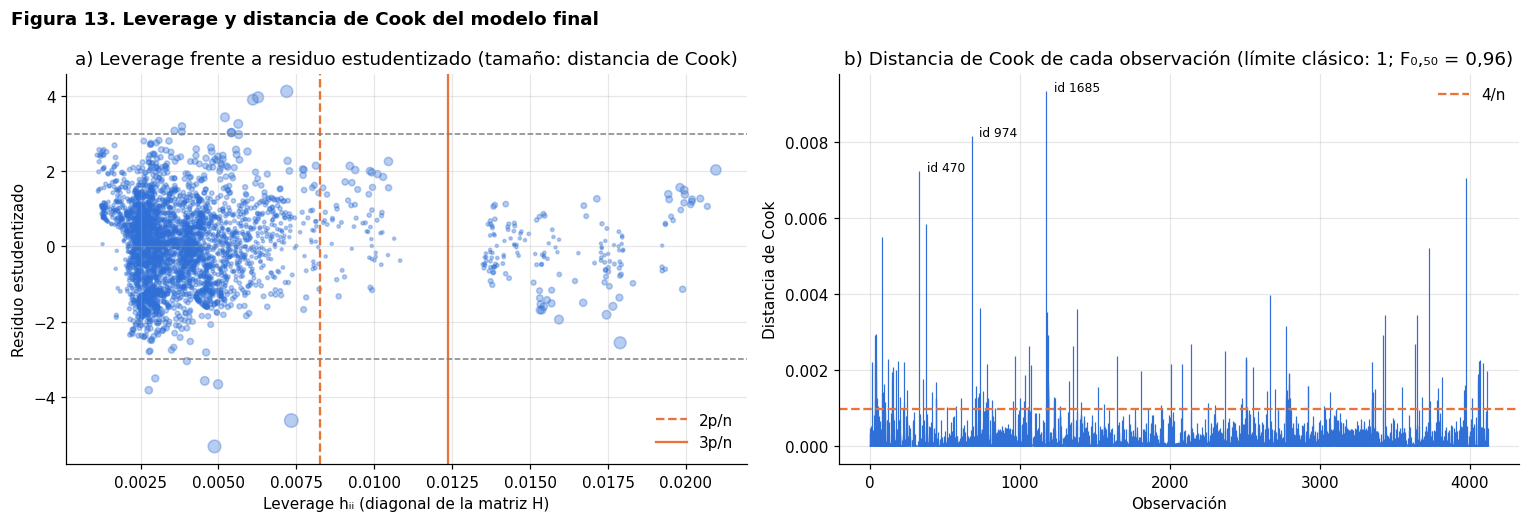

In [34]:
# Diagonal de la matriz H (leverage) y distancia de Cook del modelo final (MCO con la raíz cuadrada de SalePrice)
influencia_final = OLSInfluence(ajuste_clasico)
n_par = X_elegida.shape[1]
leverage_s = pd.Series(influencia_final.hat_matrix_diag, index=train.index)
cook = pd.Series(influencia_final.cooks_distance[0], index=train.index)
limites = {"h_2p_n": 2 * n_par / n_obs, "h_3p_n": 3 * n_par / n_obs, "cook_4_n": 4 / n_obs,
           "cook_F50": st.f.ppf(0.5, n_par, n_obs - n_par)}
alto_leverage = leverage_s > limites["h_2p_n"]
alto_cook = cook > limites["cook_4_n"]

criterios_pd = pd.DataFrame([
    {"criterio": "Leverage alto: hᵢᵢ > 2p/n", "limite": limites["h_2p_n"], "observaciones": int(alto_leverage.sum())},
    {"criterio": "Leverage muy alto: hᵢᵢ > 3p/n", "limite": limites["h_3p_n"],
     "observaciones": int((leverage_s > limites["h_3p_n"]).sum())},
    {"criterio": "Cook moderado: Dᵢ > 4/n", "limite": limites["cook_4_n"], "observaciones": int(alto_cook.sum())},
    {"criterio": "Cook influyente: Dᵢ > F₀,₅₀(p, n − p)", "limite": limites["cook_F50"],
     "observaciones": int((cook > limites["cook_F50"]).sum())},
    {"criterio": "Cook influyente: Dᵢ > 1", "limite": 1.0, "observaciones": int((cook > 1).sum())},
    {"criterio": "Leverage alto y Cook > 4/n a la vez", "limite": np.nan,
     "observaciones": int((alto_leverage & alto_cook).sum())},
])
display(HTML(f"<b>Observaciones con leverage alto o influyentes</b> (n = {num_es(n_obs, ',d')}, p = {n_par}; "
             f"leverage máximo = {coma(leverage_s.max(), 4)}, Cook máximo = {coma(cook.max(), 4)})"))
display(criterios_pd.style.hide(axis="index").format({"limite": lambda v: num_es(v, ".4f")}))

top_cook = (train.loc[cook.nlargest(10).index, ["id", respuesta] + numericos + list(categoricos)]
            .assign(leverage=leverage_s, distancia_Cook=cook, residuo_estudentizado=residuos_estud,
                    leverage_alto=lambda t: np.where(t["leverage"] > limites["h_2p_n"], "sí", "no")))
display(HTML("<b>Las 10 observaciones con mayor distancia de Cook</b>"))
display(top_cook.style.hide(axis="index").format({
    "id": lambda v: str(v), respuesta: lambda v: num_es(v, ",.0f"), "leverage": lambda v: num_es(v, ".4f"),
    "distancia_Cook": lambda v: num_es(v, ".4f"), "residuo_estudentizado": lambda v: num_es(v, ".2f")}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.scatter(leverage_s, residuos_estud, s=4 + 8000 * cook, alpha=0.35, color=AZUL)
ax1.axvline(limites["h_2p_n"], color=NARANJA, lw=1.5, ls="--", label="2p/n")
ax1.axvline(limites["h_3p_n"], color=NARANJA, lw=1.5, label="3p/n")
for limite in (-3, 3):
    ax1.axhline(limite, color="gray", lw=1, ls="--")
ax1.set(title="a) Leverage frente a residuo estudentizado (tamaño: distancia de Cook)",
        xlabel="Leverage hᵢᵢ (diagonal de la matriz H)", ylabel="Residuo estudentizado")
ax1.legend(frameon=False, loc="lower right")
ax2.vlines(np.arange(n_obs), 0, cook.values, color=AZUL, lw=0.8)
ax2.axhline(limites["cook_4_n"], color=NARANJA, lw=1.5, ls="--", label="4/n")
for i_obs in cook.nlargest(3).index:
    ax2.annotate(f"id {train.loc[i_obs, 'id']}", (train.index.get_loc(i_obs), cook[i_obs]), fontsize=8,
                 xytext=(5, 0), textcoords="offset points")
ax2.set(title=f"b) Distancia de Cook de cada observación (límite clásico: 1; F₀,₅₀ = {coma(limites['cook_F50'], 2)})",
        xlabel="Observación", ylabel="Distancia de Cook")
ax2.legend(frameon=False)
fig.suptitle("Figura 13. Leverage y distancia de Cook del modelo final", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [35]:
# ¿Qué pasa si se retiran observaciones? Se vuelve a ajustar el modelo final (MCO con la raíz cuadrada de SalePrice
# y errores HC3) sin ellas, y se comparan la normalidad, la varianza y los coeficientes.
def ajustar_mco(X_base, y_base, indices):
    """Si al retirar observaciones una categoría queda con menos de 2 departamentos, su efecto ya no se puede
    estimar: se retira la categoría (su indicadora y el departamento que quede) y se informa."""
    Xs = X_base.loc[indices]
    perdidas = [col for col in Xs.columns if col != "const" and set(np.unique(Xs[col])) <= {0.0, 1.0} and Xs[col].sum() < 2]
    if perdidas:
        indices = Xs.index[(Xs[perdidas] == 0).all(axis=1)]
        Xs = X_base.loc[indices].drop(columns=perdidas)
    ys = np.sqrt(y_base.loc[indices])
    mco = sm.OLS(ys, Xs).fit(cov_type="HC3")
    r = OLSInfluence(sm.OLS(ys, Xs).fit()).resid_studentized_internal
    return mco, pd.Series(r, index=indices), Xs, perdidas


nada = pd.Series(False, index=train.index)
escenarios = [
    (f"Con el id {id_retirado} (todos los datos)", X_elegida_completa, y_venta_completo, X_elegida_completa.index),
    (f"Modelo final (sin el id {id_retirado})", X_elegida, y_venta, train.index),
    ("Modelo final, sin leverage alto (hᵢᵢ > 2p/n)", X_elegida, y_venta, train.index[~alto_leverage.values]),
    ("Modelo final, sin leverage alto y Cook > 4/n", X_elegida, y_venta, train.index[~(alto_leverage & alto_cook).values]),
    ("Modelo final, sin Cook > 4/n", X_elegida, y_venta, train.index[~alto_cook.values]),
    (f"Modelo final, sin la siguiente más influyente (id {train.loc[cook.idxmax(), 'id']})", X_elegida, y_venta,
     train.index[~(cook == cook.max()).values]),
]
filas_escenarios = []
for nombre, X_base, y_base, indices in escenarios:
    mco, r, Xs, perdidas = ajustar_mco(X_base, y_base, indices)
    cambio = (mco.params / modelo_final.params.reindex(mco.params.index) - 1).abs().drop("const")
    filas_escenarios.append({
        "escenario": nombre, "observaciones": len(r),
        "categorias_que_se_pierden": ", ".join(col.split("_", 1)[1] for col in perdidas) or "ninguna",
        "asimetria": skew(r), "curtosis_en_exceso": kurtosis(r),
        "p_valor_Jarque_Bera": jarque_bera(r).pvalue, "p_valor_Breusch_Pagan": het_breuschpagan(mco.resid, Xs)[1],
        "cambio_mediano_coef_pct": cambio.median() * 100,
        "cambio_max_coef_pct": cambio.max() * 100, "coef_que_mas_cambia": cambio.idxmax(),
        "significativos_5pct": int((mco.pvalues.drop("const") < 0.05).sum())})
escenarios_pd = pd.DataFrame(filas_escenarios)
display(HTML("<b>Efecto de retirar observaciones sobre la normalidad, la varianza y los coeficientes</b>"))
display(escenarios_pd.style.hide(axis="index").format({
    "observaciones": lambda v: num_es(v, ",d"),
    "asimetria": lambda v: num_es(v, ".3f"), "curtosis_en_exceso": lambda v: num_es(v, ".3f"),
    "p_valor_Jarque_Bera": p_es, "p_valor_Breusch_Pagan": p_es,
    "cambio_mediano_coef_pct": lambda v: num_es(v, ".1f"), "cambio_max_coef_pct": lambda v: num_es(v, ".1f")}))

# Departamentos comparables con el departamento retirado
retirado = train_completo.loc[train_completo["id"] == id_retirado].iloc[0]
comparables = train_completo[(train_completo["Size_sqf"] == retirado["Size_sqf"])
                             & (train_completo["SubwayStation"] == retirado["SubwayStation"])
                             & (train_completo["HallwayType"] == retirado["HallwayType"])
                             & (train_completo["YrSold"].between(retirado["YrSold"] - 1, retirado["YrSold"] + 1))]
display(HTML(f"<b>Departamentos comparables con el id {id_retirado}</b> (mismo tamaño, estación y tipo de "
             f"pasillo, vendidos entre {retirado['YrSold'] - 1} y {retirado['YrSold'] + 1})"))
mostrar(comparables[["id", respuesta, "YrSold", "MonthSold", "Floor", "N_FacilitiesInApt"]]
        .sort_values(respuesta).assign(id=lambda t: t["id"].astype(str)), decimales=0)

escenario,observaciones,categorias_que_se_pierden,asimetria,curtosis_en_exceso,p_valor_Jarque_Bera,p_valor_Breusch_Pagan,cambio_mediano_coef_pct,cambio_max_coef_pct,coef_que_mas_cambia,significativos_5pct
Con el id 3798 (todos los datos),4.124,ninguna,"-0,128","1,330","< 0,0001","< 0,0001","0,6","8,3",SubwayStation_Daegu,15
Modelo final (sin el id 3798),4.123,ninguna,"0,008","0,299","0,0005","< 0,0001","0,0","0,0",Size_sqf,15
"Modelo final, sin leverage alto (hᵢᵢ > 2p/n)",3.899,"Chil-sung-market, Daegu","-0,007","0,317","0,0003","< 0,0001","2,8","15,2",SubwayStation_no_subway_nearby,14
"Modelo final, sin leverage alto y Cook > 4/n",4.074,ninguna,"-0,010","0,357","< 0,0001","< 0,0001","2,5","132,0",SubwayStation_Daegu,15
"Modelo final, sin Cook > 4/n",3.967,ninguna,"0,052","-0,358","< 0,0001","< 0,0001","8,2","141,6",SubwayStation_Daegu,15
"Modelo final, sin la siguiente más influyente (id 1685)",4.122,ninguna,"0,028","0,219","0,0124","< 0,0001","0,7","6,2",SubwayStation_Daegu,15


id,SalePrice,YrSold,MonthSold,Floor,N_FacilitiesInApt
3798,54.867,2.014,10,3,9
3612,224.690,2.014,7,20,9
4123,288.495,2.015,3,2,9
4304,326.548,2.015,6,8,9
4514,327.433,2.015,11,7,9
4486,384.070,2.015,10,16,9


**Resultado del leverage y la distancia de Cook**

- **Ninguna observación es influyente según los límites clásicos:** en el modelo final, la mayor distancia de Cook es 0,009 (id 1685), muy lejos de 1 y de F₀,₅₀ = 0,96. Con todos los datos, la mayor era la del id 3798 (0,017), también lejos de esos límites.
- **Hay 224 departamentos con leverage alto** (hᵢᵢ > 2p/n = 0,0082) y 162 con leverage muy alto. Son sobre todo los de las estaciones con pocos departamentos, cuyas indicadoras se estiman con pocos datos: **todos** los de *Chil-sung-market* (75) y *Daegu* (60), más 36 sin metro cercano. El mayor leverage es 0,021 (id 5313). Que su leverage sea alto no significa que el modelo se equivoque con ellos: casi todos tienen residuos entre −2 y 2 (Figura 13, panel a).
- **La falta de normalidad no venía de las observaciones de alto leverage, sino de residuos muy grandes con leverage normal**, y sobre todo de uno: el id 3798, con un residuo estudentizado de −8,3.

**Efecto de retirar observaciones** (tabla de escenarios)

| Escenario | Qué pasa |
|---|---|
| Retirar el id 3798 (modelo final frente a todos los datos) | Con **un solo departamento**, la curtosis en exceso baja de 1,33 a 0,30 y la asimetría de −0,13 a 0,01. Los coeficientes casi no cambian (0,6 % en mediana). **Se retira.** |
| Retirar además las 224 con leverage alto | La normalidad no mejora (curtosis de 0,30 a 0,32) y el modelo **pierde dos estaciones completas** (*Chil-sung-market* y *Daegu*). |
| Retirar además las 49 con leverage alto y Cook > 4/n | La normalidad no mejora (curtosis de 0,30 a 0,36). |
| Retirar además las 156 con Cook > 4/n | La curtosis pasa a −0,36: no mejora, solo cambia de signo. Además se pierde el 3,8 % de los datos y los coeficientes cambian 8,2 % en mediana. |
| Retirar además la siguiente más influyente (id 1685) | Mejora mínima (curtosis de 0,30 a 0,22). No justifica retirar un dato que no tiene señales de error. |

**Decisión**

- **Se retira solo el id 3798.** Mejora de forma considerable la normalidad de los residuos y todo indica que es un dato anómalo: se vendió en 54.867, mientras que los departamentos comparables (mismo tamaño, estación y tipo de pasillo, vendidos entre 2013 y 2015) se vendieron entre 224.690 y 384.070.
- **No se retira ninguna de las observaciones de alto apalancamiento ni las señaladas por la distancia de Cook.** No mejoran la normalidad, algunas harían perder estaciones completas del modelo y ninguna supera los límites clásicos de influencia.

### 6.6 Resumen de la verificación de supuestos

| Supuesto | Prueba | Resultado | ¿Se cumple? | Qué se hizo |
|---|---|---|---|---|
| Media cero | Prueba t, medias por decil y por variable, ANOVA | Media global 0, pero desviaciones sistemáticas en `YrSold` (hasta 0,87 desviaciones estándar en 2015), `N_FacilitiesInApt` y `Size_sqf` | Parcialmente | Se mantiene la estructura del modelo; corregirlo exigiría tratar esas variables como categóricas |
| Varianza constante | Breusch-Pagan | LM = 573,6, p < 0,0001; Box-Cox (λ = 0,362) reduce la dispersión pero no la corrige | No | Raíz cuadrada de `SalePrice` y errores estándar robustos HC3 |
| Normalidad | Jarque-Bera, D'Agostino-Pearson, Kolmogorov-Smirnov, Anderson-Darling | Asimetría 0,01 y curtosis en exceso 0,30; las pruebas rechazan por el tamaño de la muestra | Prácticamente sí | Se retiró el id 3798, un dato anómalo |
| Independencia | Durbin-Watson | DW = 1,10 (ρ = 0,45) en orden cronológico; 0,62 por edificio | No | Se reporta; los errores estándar subestiman la incertidumbre |
| Observaciones influyentes | Diagonal de la matriz H, distancia de Cook | Ningún departamento supera los límites clásicos (Cook máximo 0,009) | Sí | Solo se retiró el id 3798 |

**Puntos clave para el informe**

- El modelo final explica el **90 % de la variabilidad del precio** (R² en pesos), con un error típico de **33.655**.
- Los coeficientes son confiables en su **dirección y orden de magnitud**: todos los términos, salvo la indicadora de *Daegu*, son significativos con estadísticos t muy grandes.
- Los dos supuestos que no se cumplen (varianza constante e independencia) tienen la misma raíz: **los departamentos de un mismo edificio y de un mismo momento se parecen entre sí** más de lo que el modelo captura. No sesgan los coeficientes, pero hacen que su precisión real sea menor que la que muestran las pruebas.
- Los errores HC3 corrigen el problema de la varianza. El de la independencia podría corregirse con errores estándar agrupados por edificio.

## 7. Bondad de ajuste del modelo

Se calculan las medidas de bondad de ajuste del modelo final: MCO con la raíz cuadrada de `SalePrice`, errores estándar HC3, estimado con 4.123 departamentos (sin el id 3798).

**Qué mide cada medida** (n = 4.123 observaciones, p = 17 parámetros, k = p − 1 = 16 términos sin el intercepto)

| Medida | Fórmula | Qué mide |
|---|---|---|
| R² | 1 − SCE / SCT | Proporción de la variabilidad de la variable dependiente que explica el modelo. SCE es la suma de los residuos al cuadrado y SCT la suma de las desviaciones al cuadrado respecto a la media. Va de 0 a 1. |
| R² ajustado | 1 − (1 − R²)·(n − 1)/(n − p) | El R² penalizado por el número de parámetros. A diferencia del R², no sube solo por agregar términos. |
| Prueba F global | F = (SCR/k) / (SCE/(n − p)) | H₀: todos los coeficientes, salvo el intercepto, valen 0 (el modelo no explica nada). SCR es la variabilidad explicada. Se compara con una F(k, n − p). Se reporta con errores HC3, como en la sección 5, y en su versión clásica. |
| Error estándar de la regresión | σ̂ = √(SCE/(n − p)) | Desviación típica de los residuos: cuánto se alejan, en promedio, los valores observados de la recta del modelo. Está en la escala del modelo (√SalePrice). |
| MSE y RMSE en los datos de ajuste | MSE = Σ(yᵢ − ŷᵢ)²/n; RMSE = √MSE | Error cuadrático medio y su raíz, en pesos, calculados con los mismos datos con que se estimó el modelo. La predicción en pesos se obtiene elevando al cuadrado la predicción de √SalePrice, con la corrección de Duan (sección 4.7). El MSE está en pesos al cuadrado; el RMSE vuelve a pesos y es el que se interpreta. |
| MSE y RMSE en validación cruzada | Igual, pero con predicciones de datos que el modelo no usó | Se divide la muestra en 10 partes; el modelo se ajusta con 9 y predice la restante, 10 veces. Así se mide el error esperado con datos nuevos. |

**Dos formas de validación cruzada**

- **Aleatoria por departamento:** cada departamento cae al azar en una de las 10 partes. Es la forma estándar.
- **Por lote (edificio y mes):** todos los departamentos de un mismo edificio vendidos en el mismo mes caen en la misma parte. Como los errores de un mismo lote están correlacionados (sección 6.4), la forma aleatoria puede ser optimista: el modelo ve otras ventas del mismo lote al ajustarse. La forma por lote mide el error al predecir lotes que el modelo nunca vio.

In [36]:
# Medidas de bondad de ajuste del modelo final: MCO con √SalePrice, errores HC3, 4.123 departamentos (sin el id 3798)
n_ajuste, p_ajuste = int(ajuste_clasico.nobs), int(ajuste_clasico.df_model + 1)
gl_num, gl_den = int(ajuste_clasico.df_model), int(ajuste_clasico.df_resid)
sigma_hat = float(np.sqrt(ajuste_clasico.mse_resid))


def predecir_pesos(z, residuos):
    """Precio promedio en pesos: (z + eⱼ)² promediado sobre los residuos de ajuste (smearing de Duan)."""
    z = np.asarray(z, dtype=float)
    return ((z[:, None] + np.asarray(residuos, dtype=float)[None, :]) ** 2).mean(axis=1)


pred_ajuste = predecir_pesos(ajuste_clasico.fittedvalues, ajuste_clasico.resid)
error_ajuste = y_venta.values - pred_ajuste
sct_pesos = float(np.sum((y_venta.values - y_venta.mean()) ** 2))
mse_ajuste = float(np.mean(error_ajuste ** 2))

escala_pd = pd.DataFrame([
    {"medida": "R²", "valor": ajuste_clasico.rsquared, "escala": "√SalePrice"},
    {"medida": "R² ajustado", "valor": ajuste_clasico.rsquared_adj, "escala": "√SalePrice"},
    {"medida": f"Prueba F global con errores HC3: F({gl_num}, {gl_den})", "valor": modelo_final.fvalue, "escala": "√SalePrice"},
    {"medida": "Prueba F global con errores HC3: p-valor", "valor": modelo_final.f_pvalue, "escala": "√SalePrice"},
    {"medida": f"Prueba F global clásica: F({gl_num}, {gl_den})", "valor": ajuste_clasico.fvalue, "escala": "√SalePrice"},
    {"medida": f"Valor crítico F al 5 %", "valor": st.f.ppf(0.95, gl_num, gl_den), "escala": "√SalePrice"},
    {"medida": "Error estándar de la regresión σ̂", "valor": sigma_hat, "escala": "√SalePrice"},
])
formatos = [".4f", ".4f", ",.2f", "p", ",.2f", ".3f", ".3f"]
escala_pd["valor"] = [p_es(v) if f == "p" else num_es(v, f) for v, f in zip(escala_pd["valor"], formatos)]
mostrar(escala_pd, f"Medidas en la escala del modelo (n = {num_es(n_ajuste, ',d')}, p = {p_ajuste} parámetros)")

medida,valor,escala
R²,"0,9126",√SalePrice
R² ajustado,"0,9123",√SalePrice
"Prueba F global con errores HC3: F(16, 4106)","3.820,23",√SalePrice
Prueba F global con errores HC3: p-valor,"< 0,0001",√SalePrice
"Prueba F global clásica: F(16, 4106)","2.679,86",√SalePrice
Valor crítico F al 5 %,"1,646",√SalePrice
Error estándar de la regresión σ̂,"34,361",√SalePrice


datos,MSE,RMSE,RMSE_pct_del_precio_medio,R2
ajuste (los mismos datos con que se estimó),1.132.677.595,33.655,"15,2","0,8998"
validación cruzada aleatoria por departamento,1.140.740.941,33.775,"15,2","0,8991"
validación cruzada por lote (edificio y mes),1.392.120.720,37.311,"16,8","0,8768"


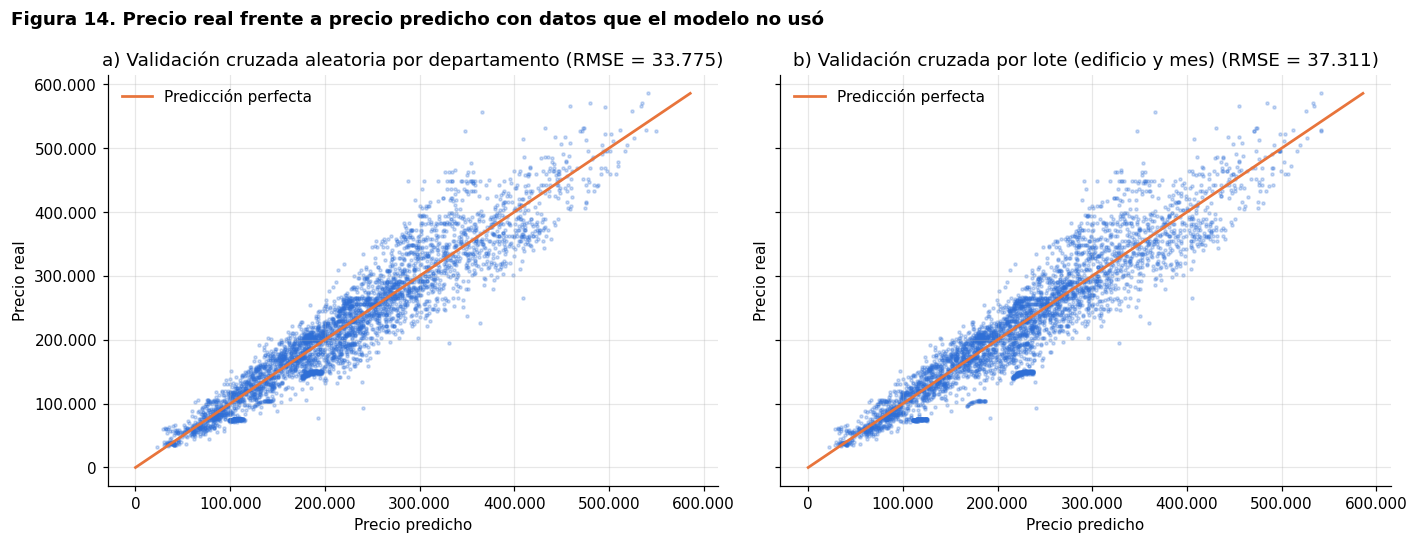

In [37]:
# Validación cruzada de 10 particiones: el modelo se ajusta con el 90 % de los departamentos y se predice el 10 %
# restante, 10 veces. Se usan dos formas de partir los datos:
#  - aleatoria por departamento (semilla fija);
#  - por lote: todos los departamentos de un mismo edificio vendidos en el mismo mes caen en la misma partición,
#    así el modelo nunca ve otras ventas del lote que predice (los errores de un lote están correlacionados, 6.4).
def validacion_cruzada(asignacion):
    pred = np.empty(n_ajuste)
    for k in np.unique(asignacion):
        prueba_idx = np.where(asignacion == k)[0]
        ajuste_idx = np.where(asignacion != k)[0]
        aj = sm.OLS(y_elegida.iloc[ajuste_idx], X_elegida.iloc[ajuste_idx]).fit()
        pred[prueba_idx] = predecir_pesos(X_elegida.iloc[prueba_idx].values @ aj.params.values, aj.resid)
    return pred


asignacion_aleatoria = np.empty(n_ajuste, dtype=int)
for k, parte in enumerate(np.array_split(np.random.default_rng(42).permutation(n_ajuste), 10)):
    asignacion_aleatoria[parte] = k
lote = pd.factorize(train[columnas_edificio].astype(str).agg("|".join, axis=1)
                    + "|" + train["YrSold"].astype(str) + "|" + train["MonthSold"].astype(str))[0]
lotes_unicos = np.unique(lote)
asignacion_lote = pd.Series(np.random.default_rng(42).integers(0, 10, len(lotes_unicos)), index=lotes_unicos)[lote].values

pred_cv = {"aleatoria por departamento": validacion_cruzada(asignacion_aleatoria),
           "por lote (edificio y mes)": validacion_cruzada(asignacion_lote)}


def medidas_pesos(nombre, pred):
    e = y_venta.values - pred
    mse = float(np.mean(e ** 2))
    return {"datos": nombre, "MSE": mse, "RMSE": np.sqrt(mse), "RMSE_pct_del_precio_medio": np.sqrt(mse) / y_venta.mean() * 100,
            "R2": 1 - float(np.sum(e ** 2)) / sct_pesos}


pesos_pd = pd.DataFrame([medidas_pesos("ajuste (los mismos datos con que se estimó)", pred_ajuste)]
                        + [medidas_pesos(f"validación cruzada {k}", v) for k, v in pred_cv.items()])
display(HTML(f"<b>Medidas en pesos</b> (precio medio de venta: {num_es(y_venta.mean(), ',.0f')}; "
             f"lotes edificio-mes: {num_es(len(lotes_unicos), ',d')})"))
display(pesos_pd.style.hide(axis="index").format({
    "MSE": lambda v: num_es(v, ",.0f"), "RMSE": lambda v: num_es(v, ",.0f"),
    "RMSE_pct_del_precio_medio": lambda v: num_es(v, ".1f"), "R2": lambda v: num_es(v, ".4f")}))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, letra, (nombre, pred) in zip(ejes, "ab", pred_cv.items()):
    ax.scatter(pred, y_venta.values, s=4, alpha=0.25, color=AZUL)
    limite = [0, max(y_venta.max(), pred.max())]
    ax.plot(limite, limite, color=NARANJA, lw=1.8, label="Predicción perfecta")
    rmse = np.sqrt(np.mean((y_venta.values - pred) ** 2))
    ax.set(title=f"{letra}) Validación cruzada {nombre} (RMSE = {num_es(rmse, ',.0f')})",
           xlabel="Precio predicho", ylabel="Precio real")
    ax.xaxis.set_major_formatter(miles)
    ax.yaxis.set_major_formatter(miles)
    ax.legend(frameon=False, loc="upper left")
fig.suptitle("Figura 14. Precio real frente a precio predicho con datos que el modelo no usó",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretación**

**Medidas en la escala del modelo**

- **R² = 0,913:** el modelo explica el **91,3 %** de la variabilidad de √SalePrice. Las 7 variables elegidas capturan la mayor parte de lo que hace variar el precio.
- **R² ajustado = 0,912:** prácticamente igual al R². Con 4.123 observaciones y 17 parámetros, la penalización por el número de términos es mínima: el modelo no está inflado por exceso de parámetros.
- **Prueba F global:** F = 3.820 con errores HC3 (2.680 en la versión clásica), frente a un valor crítico de 1,65 al 5 %, con p < 0,0001. Se rechaza H₀: el modelo en su conjunto explica el precio.
- **Error estándar de la regresión σ̂ = 34,36:** es la desviación típica de los residuos en unidades de √SalePrice. En pesos equivale aproximadamente a 2·√precio·σ̂, así que **depende del nivel del precio**: cerca de 21.700 para un departamento de 100.000, 32.400 para uno de 221.700 (el precio medio) y 43.500 para uno de 400.000. Es la varianza no constante de la sección 6.2: el modelo se equivoca más en pesos con los departamentos caros.

**Medidas en pesos**

- **Datos de ajuste:** RMSE = **33.655** (15,2 % del precio medio de 221.728) y R² en pesos de 0,900. El MSE (1.132.677.595 pesos²) no se interpreta directamente porque está en pesos al cuadrado; su raíz es el RMSE.
- **Validación cruzada aleatoria:** RMSE = **33.775** (MSE = 1.140.740.941) y R² de 0,899. Es apenas un 0,4 % mayor que en los datos de ajuste: **el modelo no está sobreajustado** y predice departamentos que no usó casi igual de bien que los que usó.
- **Validación cruzada por lote:** RMSE = **37.311** (MSE = 1.392.120.720), 16,8 % del precio medio, y R² de 0,877. El error es un 11 % mayor que con la partición aleatoria: es el efecto de los errores correlacionados dentro de cada lote (6.4). Al predecir un lote nuevo, el modelo no cuenta con otras ventas del mismo edificio y mes que le indiquen si ese lote se vendió por encima o por debajo de lo típico.
- **Figura 14:** en las dos validaciones los puntos se agrupan alrededor de la recta de predicción perfecta, sin curvaturas, y la dispersión crece con el precio, de nuevo por la varianza no constante.

**Conclusión:** el modelo tiene un **buen ajuste**: explica cerca del 90 % de la variabilidad del precio y no está sobreajustado. Para un departamento nuevo, el error típico esperado es de unos **33.800 a 37.300**, entre el 15 % y el 17 % del precio medio. La cifra más realista para un informe es la de la validación por lote (**37.311**), porque es la que más se parece a predecir ventas nuevas. El error es menor en los departamentos baratos y mayor en los caros.

## 8. Intervalos de confianza de los parámetros

Se calculan los intervalos de confianza del 95 % para los 17 parámetros del modelo final (MCO con √SalePrice, 4.123 departamentos, sin el id 3798) con tres métodos. La sección 5.1 ya mostraba los errores estándar clásico y HC3 y el intervalo HC3; aquí se agregan el intervalo clásico y el intervalo bootstrap para compararlos en una sola tabla.

**Qué significa cada columna de la tabla**

| Columna | Qué es |
|---|---|
| `termino`, `coeficiente` | Columna del modelo y estimación de su parámetro β̂ (escala √SalePrice), los mismos de la sección 5.1. |
| `EE_clasico` | Error estándar de mínimos cuadrados: supone que la varianza de los errores es constante. |
| `EE_HC3` | Error estándar robusto a varianza no constante (HC3). Es el que se usa en todo el informe (secciones 5 y 7). |
| `EE_bootstrap` | Desviación estándar de los 2.000 coeficientes estimados en los remuestreos bootstrap. |
| `IC95_clasico_inf`, `IC95_clasico_sup` | β̂ ± t₀,₉₇₅;₄.₁₀₆ × EE clásico, con t₀,₉₇₅;₄.₁₀₆ = 1,9605. |
| `IC95_HC3_inf`, `IC95_HC3_sup` | β̂ ± 1,9605 × EE HC3. Son los mismos intervalos de la sección 5.1. |
| `IC95_bootstrap_inf`, `IC95_bootstrap_sup` | **Bootstrap por pares (percentil):** se sacan 2.000 muestras de 4.123 departamentos con reemplazo, se reestima el modelo en cada una y se toman los percentiles 2,5 y 97,5 de cada coeficiente. No usa ninguna fórmula de error estándar ni supone varianza constante o normalidad: la incertidumbre sale de la variación de los coeficientes entre muestras. |
| `incluye_0_...` | «sí» si el intervalo contiene el 0, es decir, si el término no es significativo al 5 % con ese método. |
| `ancho_HC3_vs_clasico`, `ancho_bootstrap_vs_clasico` | Ancho del intervalo HC3 o bootstrap dividido entre el ancho del clásico. Mayor que 1: el intervalo clásico era demasiado estrecho para ese término; menor que 1: era demasiado ancho. |

termino,coeficiente,EE_clasico,EE_HC3,EE_bootstrap,IC95_clasico_inf,IC95_clasico_sup,IC95_HC3_inf,IC95_HC3_sup,IC95_bootstrap_inf,IC95_bootstrap_sup,incluye_0_clasico,incluye_0_HC3,incluye_0_bootstrap,ancho_HC3_vs_clasico,ancho_bootstrap_vs_clasico
const,"-30.907,7","407,497","388,945","397,082","-31.706,6","-30.108,8","-31.670,2","-30.145,2","-31.692,7","-30.111,6",no,no,no,"0,95","0,99"
Size_sqf,"0,210678","0,002346","0,00243207","0,00239473","0,206078","0,215277","0,20591","0,215446","0,205931","0,215352",no,no,no,"1,04","1,02"
(Size_sqf - media)²,"-9,92832e-05","3,09333e-06","3,26209e-06","3,23418e-06","-0,000105348","-9,32186e-05","-0,000105679","-9,28877e-05","-0,00010553","-9,29895e-05",no,no,no,"1,05","1,03"
YrSold,"15,4503","0,202485","0,193667","0,197776","15,0533","15,8473","15,0706","15,83","15,0532","15,8405",no,no,no,"0,96","0,99"
(YrSold - media)²,"1,00816","0,07351","0,0703413","0,0688251","0,864036","1,15227","0,870248","1,14606","0,873055","1,14252",no,no,no,"0,96","0,93"
1/MonthSold,"-44,4769","2,10554","2,51628","2,47397","-48,6049","-40,3489","-49,4101","-39,5436","-49,3188","-39,8785",no,no,no,"1,20","1,14"
Floor,"1,24312","0,0748953","0,0774319","0,0780803","1,09629","1,38996","1,09131","1,39493","1,09336","1,39686",no,no,no,"1,03","1,03"
N_FacilitiesInApt,"11,9781","0,338664","0,329242","0,337977","11,3142","12,6421","11,3326","12,6236","11,3319","12,6567",no,no,no,"0,97","1,00"
HallwayType_mixed,"-41,2959","2,58075","2,12611","2,11165","-46,3556","-36,2363","-45,4642","-37,1276","-45,3343","-37,1967",no,no,no,"0,82","0,80"
HallwayType_corridor,"-43,5773","2,83884","2,51076","2,50408","-49,143","-38,0117","-48,4998","-38,6549","-48,5009","-38,7606",no,no,no,"0,88","0,88"


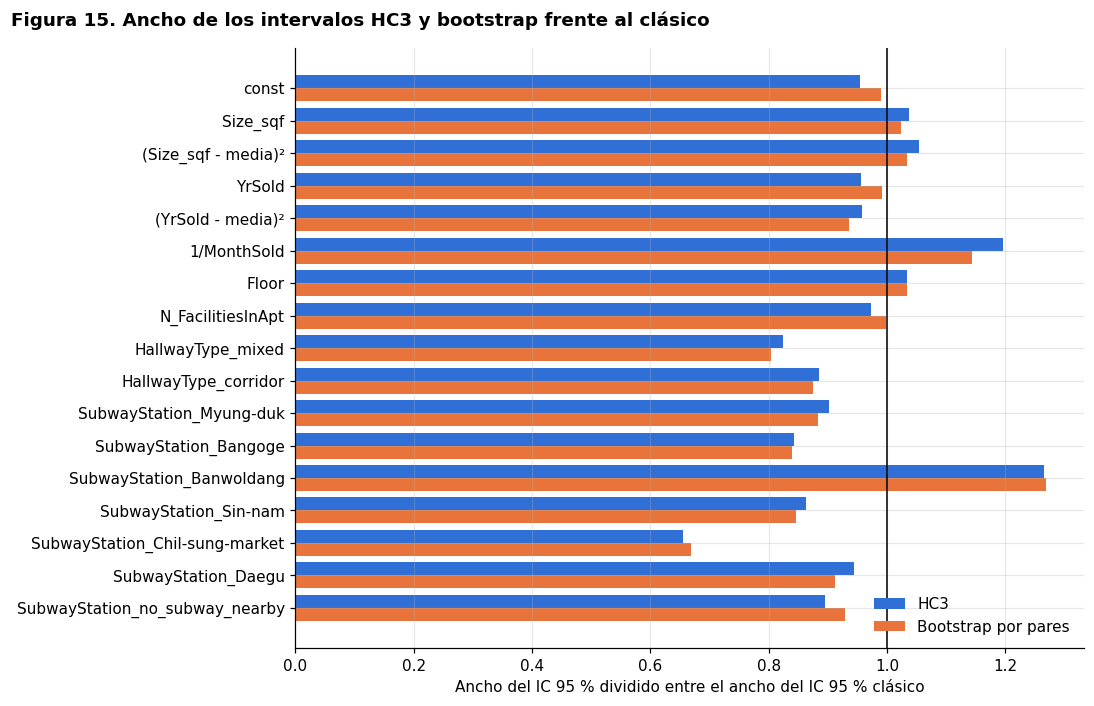

In [38]:
# Intervalos de confianza del 95 % para los parámetros del modelo final (MCO con √SalePrice, 4.123 departamentos)
# 1) Clásico: β̂ ± t₀,₉₇₅;n−p · EE clásico (supone varianza constante)
# 2) HC3:     β̂ ± t₀,₉₇₅;n−p · EE HC3 (el mismo de la sección 5.1)
# 3) Bootstrap por pares: se remuestrean departamentos con reemplazo, se reestima el modelo B veces y se toman
#    los percentiles 2,5 y 97,5 de los coeficientes. No supone varianza constante ni normalidad.
B_bootstrap = 2000
rng_boot = np.random.default_rng(42)
X_np, y_np = X_elegida.values.astype(float), y_elegida.values.astype(float)
coef_boot = np.empty((B_bootstrap, X_np.shape[1]))
for b in range(B_bootstrap):
    muestra = rng_boot.integers(0, n_obs, n_obs)
    coef_boot[b] = np.linalg.lstsq(X_np[muestra], y_np[muestra], rcond=None)[0]

beta = ajuste_clasico.params.values
ee_clasico, ee_hc3, ee_boot = ajuste_clasico.bse.values, modelo_final.bse.values, coef_boot.std(axis=0, ddof=1)
t_c = st.t.ppf(0.975, ajuste_clasico.df_resid)
ic_pd = pd.DataFrame({
    "termino": X_elegida.columns,
    "coeficiente": beta,
    "EE_clasico": ee_clasico,
    "EE_HC3": ee_hc3,
    "EE_bootstrap": ee_boot,
    "IC95_clasico_inf": beta - t_c * ee_clasico,
    "IC95_clasico_sup": beta + t_c * ee_clasico,
    "IC95_HC3_inf": beta - t_c * ee_hc3,
    "IC95_HC3_sup": beta + t_c * ee_hc3,
    "IC95_bootstrap_inf": np.percentile(coef_boot, 2.5, axis=0),
    "IC95_bootstrap_sup": np.percentile(coef_boot, 97.5, axis=0),
})
for m in ["clasico", "HC3", "bootstrap"]:
    incluye = (ic_pd[f"IC95_{m}_inf"] <= 0) & (ic_pd[f"IC95_{m}_sup"] >= 0)
    ic_pd[f"incluye_0_{m}"] = np.where(incluye, "sí", "no")
ic_pd["ancho_HC3_vs_clasico"] = (ic_pd["IC95_HC3_sup"] - ic_pd["IC95_HC3_inf"]) / (ic_pd["IC95_clasico_sup"] - ic_pd["IC95_clasico_inf"])
ic_pd["ancho_bootstrap_vs_clasico"] = ((ic_pd["IC95_bootstrap_sup"] - ic_pd["IC95_bootstrap_inf"])
                                       / (ic_pd["IC95_clasico_sup"] - ic_pd["IC95_clasico_inf"]))

display(HTML(f"<b>Intervalos de confianza del 95 % de los parámetros</b> (escala √SalePrice; "
             f"t₀,₉₇₅;{num_es(int(ajuste_clasico.df_resid), ',d')} = {coma(t_c, 4)}; "
             f"bootstrap por pares con B = {num_es(B_bootstrap, ',d')} remuestreos, semilla 42)"))
formato_ic = {c: (lambda v: num_es(v, ",.6g")) for c in ic_pd.columns if c.startswith(("coeficiente", "EE_", "IC95_"))}
formato_ic.update({c: (lambda v: num_es(v, ".2f")) for c in ic_pd.columns if c.startswith("ancho_")})
display(ic_pd.style.hide(axis="index").format(formato_ic))

# Figura 15: ancho de cada intervalo en relación con el clásico (1 = igual de ancho que el clásico)
fig, ax = plt.subplots(figsize=(10, 6.5))
pos = np.arange(len(ic_pd))
ax.barh(pos - 0.2, ic_pd["ancho_HC3_vs_clasico"], height=0.4, color=AZUL, label="HC3")
ax.barh(pos + 0.2, ic_pd["ancho_bootstrap_vs_clasico"], height=0.4, color=NARANJA, label="Bootstrap por pares")
ax.axvline(1, color="black", lw=1)
ax.set_yticks(pos)
ax.set_yticklabels(ic_pd["termino"])
ax.invert_yaxis()
ax.set(xlabel="Ancho del IC 95 % dividido entre el ancho del IC 95 % clásico")
ax.legend(frameon=False, loc="lower right")
fig.suptitle("Figura 15. Ancho de los intervalos HC3 y bootstrap frente al clásico", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretación**

- **Los tres métodos llevan a las mismas conclusiones.** 16 de los 17 intervalos excluyen el 0 con los tres métodos. La única excepción es *Daegu*, cuyo intervalo incluye el 0 en los tres casos (clásico de −4,97 a 13,87; HC3 de −4,45 a 13,35; bootstrap de −4,34 a 12,86): su precio no se distingue del de la estación de referencia (5.1).
- **HC3 y bootstrap coinciden casi exactamente.** Sus errores estándar difieren en menos de un 3 % en todos los términos, y sus intervalos casi se superponen (en la Figura 15, las barras azules y naranjas tienen casi el mismo largo). Son dos formas distintas de tener en cuenta la varianza no constante, una con fórmula y otra por remuestreo, así que su acuerdo confirma que los intervalos HC3 usados en el informe son confiables.
- **El intervalo clásico se equivoca en ambos sentidos,** por la varianza no constante (6.2):
  - es **demasiado estrecho** en *Banwoldang* (los intervalos robustos son entre un 26 y un 27 % más anchos) y en `1/MonthSold` (entre un 14 y un 20 % más anchos): con el clásico, esos coeficientes parecen más precisos de lo que son;
  - es **demasiado ancho** en *Chil-sung-market* (los robustos son un 33 % más estrechos), *mixed* (entre un 18 y un 20 %) y las demás estaciones;
  - en `Size_sqf`, `YrSold`, `Floor` y `N_FacilitiesInApt`, los términos con más peso, los tres intervalos casi coinciden (diferencias de ±5 %).
- **Ninguna conclusión cambia al elegir un método u otro,** porque los coeficientes significativos están lejos del 0. Por eso, para el informe se mantiene el **intervalo HC3** de la sección 5.1, y el bootstrap queda como verificación.

**Limitación.** Los tres métodos suponen que los departamentos son independientes entre sí. La sección 6.4 mostró que no es así: los errores de departamentos de un mismo edificio vendidos en el mismo mes están correlacionados. Con esa dependencia, los tres intervalos pueden ser más estrechos de lo que deberían, sobre todo en los términos que varían por edificio (`N_FacilitiesInApt`, `HallwayType` y `SubwayStation`). La estimación puntual de los coeficientes no se ve afectada; solo su precisión.

## 9. Pruebas de hipótesis sobre los parámetros

Tabla que reúne todas las pruebas de hipótesis sobre los parámetros del modelo final. Las cifras son las mismas de las secciones 5.1, 5.2 y 7.1, donde están explicadas e interpretadas.

- **Individual (t):** H₀: el parámetro del término vale 0. Grados de libertad n − p = 4.106.
- **Conjunta por variable (F de Wald):** H₀: todos los parámetros de la variable valen 0. Grados de libertad (número de columnas de la variable, 4.106).
- **Global (F):** H₀: todos los parámetros, salvo el intercepto, valen 0. Grados de libertad (16, 4.106).

Todas usan errores estándar HC3. Se rechaza H₀ si p < 0,05.

In [39]:
# Tabla resumen de las pruebas de hipótesis sobre los parámetros (errores HC3; mismas cifras de las secciones 5 y 7)
gl_res = int(modelo_final.df_resid)
filas_pruebas = []
for _, f in parametros_pd.iterrows():
    filas_pruebas.append({"prueba": "individual (5.1)", "termino_o_variable": f["termino"],
                          "hipotesis_nula": f"β({f['termino']}) = 0", "estadistico": "t",
                          "valor": f["estadistico_t"], "grados_de_libertad": num_es(gl_res, ",d"), "p_valor": f["p_valor"]})
for _, f in conjuntas_pd.iterrows():
    cols = [c for c in X_elegida.columns if describir_columna(c)[0] == f["variable"]]
    h0 = " = ".join(f"β({c})" for c in cols) + " = 0" if len(cols) <= 2 else f"los {len(cols)} β de {f['variable']} = 0"
    filas_pruebas.append({"prueba": "conjunta por variable (5.2)", "termino_o_variable": f["variable"],
                          "hipotesis_nula": h0, "estadistico": "F", "valor": f["estadistico_F"],
                          "grados_de_libertad": f"({f['gl_numerador']}, {num_es(f['gl_denominador'], ',d')})",
                          "p_valor": f["p_valor"]})
filas_pruebas.append({"prueba": "global del modelo (5.2 y 7.1)", "termino_o_variable": "todos los términos",
                      "hipotesis_nula": f"β₁ = β₂ = … = β₁₆ = 0", "estadistico": "F", "valor": modelo_final.fvalue,
                      "grados_de_libertad": f"({int(modelo_final.df_model)}, {num_es(gl_res, ',d')})",
                      "p_valor": modelo_final.f_pvalue})
pruebas_pd = pd.DataFrame(filas_pruebas)
pruebas_pd["decision_5pct"] = np.where(pruebas_pd["p_valor"] < 0.05, "se rechaza H₀", "no se rechaza H₀")

display(HTML(f"<b>Pruebas de hipótesis sobre los parámetros del modelo final</b> (errores estándar HC3; "
             f"{len(pruebas_pd)} pruebas; α = 0,05)"))
display(pruebas_pd.style.hide(axis="index").format({"valor": lambda v: num_es(v, ",.2f"), "p_valor": p_es}))

prueba,termino_o_variable,hipotesis_nula,estadistico,valor,grados_de_libertad,p_valor,decision_5pct
individual (5.1),const,β(const) = 0,t,"-79,47",4.106,"< 0,0001",se rechaza H₀
individual (5.1),Size_sqf,β(Size_sqf) = 0,t,"86,63",4.106,"< 0,0001",se rechaza H₀
individual (5.1),(Size_sqf - media)²,β((Size_sqf - media)²) = 0,t,"-30,44",4.106,"< 0,0001",se rechaza H₀
individual (5.1),YrSold,β(YrSold) = 0,t,"79,78",4.106,"< 0,0001",se rechaza H₀
individual (5.1),(YrSold - media)²,β((YrSold - media)²) = 0,t,"14,33",4.106,"< 0,0001",se rechaza H₀
individual (5.1),1/MonthSold,β(1/MonthSold) = 0,t,"-17,68",4.106,"< 0,0001",se rechaza H₀
individual (5.1),Floor,β(Floor) = 0,t,"16,05",4.106,"< 0,0001",se rechaza H₀
individual (5.1),N_FacilitiesInApt,β(N_FacilitiesInApt) = 0,t,"36,38",4.106,"< 0,0001",se rechaza H₀
individual (5.1),HallwayType_mixed,β(HallwayType_mixed) = 0,t,"-19,42",4.106,"< 0,0001",se rechaza H₀
individual (5.1),HallwayType_corridor,β(HallwayType_corridor) = 0,t,"-17,36",4.106,"< 0,0001",se rechaza H₀


**Resultado:** se rechaza H₀ en 24 de las 25 pruebas. La única que no se rechaza es la individual de *Daegu*; aun así, la variable `SubwayStation` es significativa en conjunto (ver 5.1 y 5.2).

En las variables que entran con una sola columna (`N_FacilitiesInApt`, `MonthSold` y `Floor`), la prueba conjunta equivale a la individual: F = t².

## 10. Efecto en pesos de una unidad de cada variable

Traduce a pesos los coeficientes de la sección 5.1 (interpretados en 4.7 y 5.1). Se parte del departamento de referencia de la sección 4.7 y se aumenta en una unidad una sola variable; en las categóricas, se cambia de la categoría de referencia a cada una de las demás.

- `delta_raiz_SalePrice`: cambio en √SalePrice. En `Size_sqf` y `YrSold` suma el término lineal y el cuadrático; en `MonthSold`, el cambio de 1/MonthSold.
- `pesos_depto_...`: cambio en pesos, (√P + Δ)² − P, para un departamento de 100.000, para el de referencia y para uno de 400.000. Como el modelo usa √SalePrice, el mismo cambio vale más pesos en un departamento caro.

In [40]:
# Efecto en pesos de aumentar una unidad cada variable, partiendo del departamento de referencia de la sección 4.7.
# Δz es el cambio en √SalePrice (suma de los coeficientes de todas las columnas de la variable);
# en pesos, para un departamento de precio P: (√P + Δz)² − P.
z_ref = float(predecir_referencia(numericos[0], [referencia[numericos[0]]]).iloc[0])
precio_ref = z_ref ** 2
unidades = {"Size_sqf": "pie²", "YrSold": "año", "MonthSold": "mes", "Floor": "piso", "N_FacilitiesInApt": "instalación"}
filas_efecto = []
for c in numericos:
    x0 = referencia[c]
    z0, z1 = predecir_referencia(c, [x0, x0 + 1]).values
    filas_efecto.append({"variable": c, "cambio": f"de {num_es(x0, ',.0f')} a {num_es(x0 + 1, ',.0f')} ({unidades[c]})",
                         "delta_raiz_SalePrice": z1 - z0})
for c, niveles in categoricos.items():
    for v in niveles[1:]:
        filas_efecto.append({"variable": c, "cambio": f"de «{niveles[0]}» a «{v}»",
                             "delta_raiz_SalePrice": float(modelo_final.params[f"{c}_{v}"])})
efecto_pd = pd.DataFrame(filas_efecto)
precios_nivel = {"pesos_depto_100000": 100_000, "pesos_depto_referencia": precio_ref, "pesos_depto_400000": 400_000}
for col, P in precios_nivel.items():
    efecto_pd[col] = (np.sqrt(P) + efecto_pd["delta_raiz_SalePrice"]) ** 2 - P

display(HTML(f"<b>Efecto en pesos de una unidad de cada variable</b> (departamento de referencia de 4.7: "
             f"precio predicho {num_es(precio_ref, ',.0f')}; las demás variables quedan fijas)"))
display(efecto_pd.style.hide(axis="index").format({
    "delta_raiz_SalePrice": lambda v: num_es(v, ",.4f"),
    **{c: (lambda v: num_es(v, ",.0f")) for c in precios_nivel}}))

variable,cambio,delta_raiz_SalePrice,pesos_depto_100000,pesos_depto_referencia,pesos_depto_400000
Size_sqf,de 910 a 911 (pie²),"0,2197",139,198,278
YrSold,de 2.013 a 2.014 (año),"17,0593",11.080,15.696,21.870
MonthSold,de 6 a 7 (mes),"1,0590",671,957,1.341
Floor,de 11 a 12 (piso),"1,2431",788,1.124,1.574
N_FacilitiesInApt,de 5 a 6 (instalación),"11,9781",7.719,10.960,15.295
HallwayType,de «terraced» a «mixed»,"-41,2959",-24.412,-35.585,-50.530
HallwayType,de «terraced» a «corridor»,"-43,5773",-25.662,-37.452,-53.222
SubwayStation,de «Kyungbuk_uni_hospital» a «Myung-duk»,"12,8555",8.296,11.774,16.426
SubwayStation,de «Kyungbuk_uni_hospital» a «Bangoge»,"15,9320",10.330,14.641,20.406
SubwayStation,de «Kyungbuk_uni_hospital» a «Banwoldang»,"57,0975",39.372,54.820,75.483


**Lectura:** en `Size_sqf`, `YrSold` y `MonthSold` el efecto de una unidad depende del punto de partida (son curvas; ver Figura 6), así que los valores de la tabla valen solo para el cambio indicado.